# 机器人末端功率（PC）时序预测：ARIMAX / LightGBM / Transformer 对比

> **全文结构**
> - **第 1–11 节：UR3e 主实验** —— 单步预测（第 3–9 节，含精度、效率、可解释性与 SHAP）与递归多步预测（第 10 节，$h=1$–$20$）；第 11 节汇总结论。
> - **第 12 节：UR10e 跨机型验证** —— 用完全相同的流程在 UR10e 上重做单步预测与可解释性，检验结论是否与机型无关。

## 1.1 任务定义（UR3e）

| 项目 | 设定 |
| --- | --- |
| 训练集 | `data/UR3e_train.csv`，116 条轨迹 / 105,400 个采样点 |
| 测试集 | `data/UR3e_test.csv`，12 条轨迹 / 6,000 个采样点 |
| 采样频率 | 50 Hz（$\Delta t = 20$ ms） |
| 输入特征 $x_t \in \mathbb{R}^{25}$ | $q_{1..6}$、$dq_{1..6}$、$T_{1..6}$、$F_x,F_y,F_z$、$Fa_1,Fa_2,Fa_3$、$M$ |
| 输出特征 $y_t$ | `PC` $= V \cdot I$（末端功率） |
| 观测窗口 | 过去 20 个时刻 $L=20$（400 ms） |
| 预测步长 | 单步 $h=1$（第 3–9 节）；多步 $h=1$–$20$（第 10 节） |

**预测形式**（单步超前，因果、不使用未来信息）：

$$
\hat{y}_t = f\left(\{x_{t-L},\dots,x_{t-1}\},\ \{y_{t-L},\dots,y_{t-1}\},\ x_t\right)
$$

即：**历史 20 步的输入 + 历史 20 步的输出 + 当前时刻输入 → 当前时刻输出**。

## 1.2 建模与评估约定

1. **按轨迹切窗**：滑窗只在单条轨迹内部滑动，绝不跨轨迹拼接，避免不同实验记录之间的伪连续。
2. **按轨迹划分验证集**：验证集用于超参数与早停，与训练集轨迹不重叠，测试集完全独立；划分后会**显式打印验证集的轨迹编号**，便于核对与复现。
3. **损失函数**：三个模型均以 RMSE（等价 MSE）为优化目标。
4. **ARIMAX 说明**：采用 AR(20)+外生输入的池化估计形式（$d=0$，带 L2 正则的闭式解）。之所以池化而非逐轨迹拟合，是因为单条轨迹仅 200–2000 点，而回归量高达 545 维，逐轨迹 SARIMAX 会严重过拟合；同时测试轨迹没有可用于估计参数的历史样本。正则强度用**按轨迹分组**的 5 折交叉验证选择，并复用每折的 Gram 矩阵以避免重复计算。
5. **评估指标**：RMSE、MAE、$R^2$、NRMSE(=RMSE/$\overline{y}$)、最大绝对误差（MaxAE），并统计逐轨迹 RMSE 的均值与波动。
6. **效率指标**：训练耗时（含超参搜索）、单样本推理延迟（batch=1，多次取中位数）、全测试集吞吐、模型参数量 / 文件大小。
7. **可解释性**：ARIMAX 用标准化系数（等价于线性 SHAP），LightGBM 用 TreeSHAP，Transformer 用注意力权重 + 梯度 SHAP 抽样估计。
8. **多步预测**：第 10 节把步长扩展到 $h=1,\dots,20$（20–400 ms），采用**递归策略**（只用 $h=1$ 的单步模型，把预测值回填为历史输出逐步外推），所有步长共用同一批样本；并以"回填真实标签"的 oracle 对照分离误差累积的贡献。
9. **跨机型验证**：第 12 节在 UR10e（100 Hz，96 条训练轨迹 / 48,000 个采样点）上复用同一套流程（同样的 `build_windows`、同样的划分种子、同样的超参），用于检验结论的可迁移性。

## 2. 环境、数据与滑窗构造

以下单元格依次完成：导入依赖与设备检查 → 读取数据并做一致性校验 → 按轨迹生成滑窗样本（每条轨迹 $n-20$ 个样本）→ 展平为 545 维表格特征（20×(25+1) 历史 + 25 当前输入）。

窗口覆盖 400 ms，训练集共 103,080 个滑窗、测试集 5,760 个滑窗。

In [1]:
from __future__ import annotations

import math
import os
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit, GroupKFold
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

warnings.filterwarnings("ignore")

# ---- 中文字体与绘图风格 ----
mpl.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
mpl.rcParams["axes.unicode_minus"] = False
try:
    plt.style.use("seaborn-v0_8-whitegrid")
except Exception:
    plt.style.use("ggplot")
plt.rcParams["figure.dpi"] = 110

SEED = 42
np.random.seed(SEED)

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = True
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"numpy {np.__version__} | pandas {pd.__version__} | torch {torch.__version__}")
print("计算设备:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "CPU")
DATA_DIR = Path("data")

train_df = pd.read_csv(DATA_DIR / "UR3e_train.csv")
test_df = pd.read_csv(DATA_DIR / "UR3e_test.csv")

GROUP = "trajectory_id"
TARGET = "PC"

FEATURE_COLS = (
    [f"q{i}" for i in range(1, 7)]          # 关节位置
    + [f"dq{i}" for i in range(1, 7)]       # 关节速度
    + [f"T{i}" for i in range(1, 7)]        # 关节力矩
    + ["Fx", "Fy", "Fz"]                    # 末端力
    + ["Fa1", "Fa2", "Fa3"]                 # 末端力矩
    + ["M"]                                 # 笛卡尔线动量范数
)
ALL_CHANNELS = FEATURE_COLS + [TARGET]
assert all(c in train_df.columns for c in ALL_CHANNELS + [GROUP, "t1"])

stat = pd.DataFrame(
    {
        "训练集": [
            len(train_df), train_df[GROUP].nunique(),
            train_df[GROUP].value_counts().median(),
            train_df[TARGET].mean(), train_df[TARGET].std(),
            train_df[TARGET].min(), train_df[TARGET].max(),
        ],
        "测试集": [
            len(test_df), test_df[GROUP].nunique(),
            test_df[GROUP].value_counts().median(),
            test_df[TARGET].mean(), test_df[TARGET].std(),
            test_df[TARGET].min(), test_df[TARGET].max(),
        ],
    },
    index=["样本数", "轨迹数", "轨迹长度中位数", "PC 均值/W", "PC 标准差/W", "PC 最小/W", "PC 最大/W"],
)
display(stat.round(3))

print("缺失值:", int(train_df.isna().sum().sum()), "/", int(test_df.isna().sum().sum()))
dt = train_df.groupby(GROUP)["t1"].diff().median()
print(f"采样周期中位数 {dt*1000:.1f} ms (≈{1/dt:.1f} Hz)")
print(f"输入维度 {len(FEATURE_COLS)}：{FEATURE_COLS}")

LAGS = 20          # 观测窗口：过去 20 个时刻 = 400 ms


def build_windows(df, lags=LAGS):
    """按轨迹滑窗构造样本。

    返回:
        seq : (N, lags, 26)  过去 lags 个时刻的 [输入 25 维 + 输出 1 维]
        cur : (N, 25)        当前时刻输入 x_t
        y   : (N,)           当前时刻目标 y_t = PC
        tid : (N,)           所属轨迹编号
        pos : (N,)           当前时刻在轨迹内的行号（用于画图）
        t   : (N,)           当前时刻时间戳
    """
    seqs, curs, ys, tids, poss, times = [], [], [], [], [], []
    for tid, g in df.groupby(GROUP, sort=True):
        g = g.sort_values("t1", kind="mergesort")
        X = g[FEATURE_COLS].to_numpy(np.float32)
        y = g[TARGET].to_numpy(np.float32)
        t = g["t1"].to_numpy(np.float64)
        n = len(g)
        if n <= lags:
            continue
        XY = np.concatenate([X, y[:, None]], axis=1)  # (n, 26)
        for k in range(lags, n):
            seqs.append(XY[k - lags:k])     # 历史输入 + 历史输出
            curs.append(X[k])               # 当前输入
            ys.append(y[k])
            tids.append(tid)
            poss.append(k)
            times.append(t[k])
    return (
        np.stack(seqs).astype(np.float32),
        np.stack(curs).astype(np.float32),
        np.asarray(ys, dtype=np.float32),
        np.asarray(tids),
        np.asarray(poss),
        np.asarray(times),
    )


Seq_tr, Cur_tr, y_tr, tid_tr, pos_tr, t_tr = build_windows(train_df)
Seq_te, Cur_te, y_te, tid_te, pos_te, t_te = build_windows(test_df)

print(f"训练窗口 {Seq_tr.shape} | 当前输入 {Cur_tr.shape} | 目标 {y_tr.shape}")
print(f"测试窗口 {Seq_te.shape} | 当前输入 {Cur_te.shape} | 目标 {y_te.shape}")
print(f"每个样本的原始特征长度 = {Seq_tr.shape[1] * Seq_tr.shape[2]} + {Cur_tr.shape[1]} = "
      f"{Seq_tr.shape[1] * Seq_tr.shape[2] + Cur_tr.shape[1]}")

numpy 2.5.4 | pandas 3.0.6 | torch 2.14.1+cu126
计算设备: cuda | NVIDIA GeForce RTX 4060 Laptop GPU


,训练集,测试集
样本数,105400.000,6000.000
轨迹数,116.000,12.000
轨迹长度中位数,500.000,500.000
PC 均值/W,44.153,45.839
PC 标准差/W,9.412,10.358
PC 最小/W,-6.250,29.224
PC 最大/W,142.500,105.772


缺失值: 0 / 0
采样周期中位数 20.0 ms (≈50.0 Hz)
输入维度 25：['q1', 'q2', 'q3', 'q4', 'q5', 'q6', 'dq1', 'dq2', 'dq3', 'dq4', 'dq5', 'dq6', 'T1', 'T2', 'T3', 'T4', 'T5', 'T6', 'Fx', 'Fy', 'Fz', 'Fa1', 'Fa2', 'Fa3', 'M']
训练窗口 (103080, 20, 26) | 当前输入 (103080, 25) | 目标 (103080,)
测试窗口 (5760, 20, 26) | 当前输入 (5760, 25) | 目标 (5760,)
每个样本的原始特征长度 = 520 + 25 = 545


In [2]:
# 注意：plt.style.use 会把 rcParams 重置为样式默认值（Arial），
# 因此中文字体必须在本单元（样式生效之后）再配置一次。
try:
    plt.style.use("seaborn-v0_8-whitegrid")
except Exception:
    pass

# ---- 统一字体与字号：全文所有图内标注文字都落在 9–10.5 pt 之间 ----
mpl.rcParams["font.family"] = "sans-serif"
mpl.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
mpl.rcParams["axes.unicode_minus"] = False

# ---- 统一图幅：A4 版心宽度 15.8 cm、300 dpi ----
DPI = 300                       # 位图输出分辨率
TEXT_W_CM = 15.8                # A4 版心宽度
FIG_W = TEXT_W_CM / 2.54        # ≈ 6.22 in

mpl.rcParams.update({
    "font.size": 10,             # 基准字号
    "axes.titlesize": 10.5,      # 子图标题
    "axes.labelsize": 10,        # 坐标轴标题
    "xtick.labelsize": 9,        # 刻度标签
    "ytick.labelsize": 9,
    "legend.fontsize": 9,        # 图例
    "legend.title_fontsize": 9,
    "figure.titlesize": 10.5,
    "figure.dpi": DPI,           # 屏幕显示与位图导出统一 300 dpi
    "savefig.dpi": DPI,
    "figure.figsize": (FIG_W, FIG_W * 0.5),
    "savefig.bbox": "tight",
})
FS_TICK, FS_LABEL, FS_TITLE, FS_LEGEND = 9, 10, 10.5, 9


def fig_size(h_ratio=0.5):
    """按 A4 版心取图幅：宽度固定 15.8 cm，高度 = 宽度 × h_ratio。"""
    return (FIG_W, FIG_W * h_ratio)


def tag_title(ax, tag, text="", fontsize=FS_TITLE, pad=6):
    """给分图加编号：居中标题，形如「(a) 子图说明」。"""
    ax.set_title(f"({tag}) {text}".strip(), loc="center", fontsize=fontsize, pad=pad)


FIG_DIR = Path("figures") / "train_test"
FIG_DIR.mkdir(parents=True, exist_ok=True)


def savefig(fig, name):
    """按 300 dpi 保存到 figures/train_test/，便于直接插入论文。"""
    path = FIG_DIR / f"{name}.png"
    fig.savefig(path, dpi=DPI, bbox_inches="tight")
    print(f"[saved] {path}  ({DPI} dpi)")
    return path


print(f"绘图字体: {mpl.rcParams['font.sans-serif'][0]} | "
      f"字号: 标题 {FS_TITLE} / 轴标签 {FS_LABEL} / 刻度与图例 {FS_TICK}")
print(f"图幅: 宽 {TEXT_W_CM} cm（A4 版心）× 高度按需 | 分辨率 {DPI} dpi | 输出目录 {FIG_DIR}")

绘图字体: Microsoft YaHei | 字号: 标题 10.5 / 轴标签 10 / 刻度与图例 9
图幅: 宽 15.8 cm（A4 版心）× 高度按需 | 分辨率 300 dpi | 输出目录 figures\train_test


## 3. 数据集划分与标准化

按 `trajectory_id` 分组划分：训练 80% 轨迹、验证 20% 轨迹（用于早停与正则强度选择），测试使用独立的 12 条轨迹。单元格会**打印验证集的轨迹编号**，便于核对划分是否与预期一致。

标准化统计量**只从训练集**估计，逐通道（输入 25 维 + 输出 1 维）计算均值与标准差，避免信息泄漏。

In [3]:
# ---------- 3.1 按轨迹分组划分 ----------
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
tr_idx, va_idx = next(gss.split(Seq_tr, y_tr, groups=tid_tr))

train_ids = np.unique(tid_tr[tr_idx])
valid_ids = np.unique(tid_tr[va_idx])

print(f"训练轨迹 {train_ids.size} 条 / {len(tr_idx)} 个窗口")
print(f"验证轨迹 {valid_ids.size} 条 / {len(va_idx)} 个窗口")
print(f"测试轨迹 {np.unique(tid_te).size} 条 / {len(y_te)} 个窗口")
print("\n【验证集轨迹编号】", sorted(int(t) for t in valid_ids))
print("【训练集轨迹编号】", sorted(int(t) for t in train_ids))

# ---------- 3.2 标准化（仅用训练集统计量） ----------
ch_mean = Seq_tr[tr_idx].reshape(-1, len(ALL_CHANNELS)).mean(0).astype(np.float32)
ch_std = Seq_tr[tr_idx].reshape(-1, len(ALL_CHANNELS)).std(0).astype(np.float32) + 1e-8
y_mu, y_sd = float(y_tr[tr_idx].mean()), float(y_tr[tr_idx].std())

scale_seq = lambda A: (A - ch_mean) / ch_std
scale_cur = lambda A: (A - ch_mean[: len(FEATURE_COLS)]) / ch_std[: len(FEATURE_COLS)]
scale_y = lambda y: (y - y_mu) / y_sd
inv_y = lambda z: z * y_sd + y_mu

# 序列输入（Transformer 用）
S_tr, S_va, S_te = scale_seq(Seq_tr[tr_idx]), scale_seq(Seq_tr[va_idx]), scale_seq(Seq_te)
C_tr, C_va, C_te = scale_cur(Cur_tr[tr_idx]), scale_cur(Cur_tr[va_idx]), scale_cur(Cur_te)
Y_tr, Y_va, Y_te = y_tr[tr_idx], y_tr[va_idx], y_te

# 展平输入（ARIMAX / LightGBM 用）：20×(25+1) + 25 = 545 维
flatten = lambda seq, cur: np.concatenate([seq.reshape(len(seq), -1), cur], axis=1).astype(np.float32)
F_tr, F_va, F_te = flatten(S_tr, C_tr), flatten(S_va, C_va), flatten(S_te, C_te)

FLAT_NAMES = (
    [f"{c}(t-{LAGS - i})" for i in range(LAGS) for c in ALL_CHANNELS]
    + [f"{c}(t)" for c in FEATURE_COLS]
)
assert len(FLAT_NAMES) == F_tr.shape[1]

print(f"\n展平特征维度 {F_tr.shape[1]}（其中 {LAGS} 个为输出自回归项）")
print(f"训练/验证/测试张量：{F_tr.shape} / {F_va.shape} / {F_te.shape}")
print(f"目标统计量（训练集）：均值 {y_mu:.2f} W，标准差 {y_sd:.2f} W")

训练轨迹 92 条 / 82560 个窗口
验证轨迹 24 条 / 20520 个窗口
测试轨迹 12 条 / 5760 个窗口

【验证集轨迹编号】 [1, 5, 11, 12, 13, 19, 27, 37, 41, 43, 46, 48, 54, 57, 68, 71, 84, 86, 89, 94, 95, 101, 110, 111]
【训练集轨迹编号】 [2, 3, 4, 6, 7, 8, 9, 10, 14, 15, 16, 17, 18, 20, 21, 22, 23, 24, 25, 26, 28, 29, 30, 31, 32, 33, 34, 35, 36, 38, 39, 40, 42, 44, 45, 47, 49, 50, 51, 52, 53, 55, 56, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 69, 70, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 85, 87, 88, 90, 91, 92, 93, 96, 97, 98, 99, 100, 102, 103, 104, 105, 106, 107, 108, 109, 112, 113, 114, 115, 116]

展平特征维度 545（其中 20 个为输出自回归项）
训练/验证/测试张量：(82560, 545) / (20520, 545) / (5760, 545)
目标统计量（训练集）：均值 44.18 W，标准差 9.18 W


## 4. 模型一：ARIMAX（AR(20) + 外生输入，池化估计）

$$
y_t = c + \sum_{l=1}^{L}\phi_l\,y_{t-l} + \sum_{l=0}^{L}\beta_l^{\top} x_{t-l} + \varepsilon_t
$$

- 自回归项：历史 20 个时刻的 `PC`；
- 外生输入项：当前时刻与历史 20 个时刻的 25 维输入；
- 以 L2 正则的闭式解求解（等价于高斯似然 + 岭惩罚），正则强度 $\alpha$ 通过**按轨迹分组**的 5 折交叉验证选择；
- 系数通过标准化特征回归得到，因此可直接比较量纲不同的变量，天然具备可解释性。

> 实现说明：回归量 545 维，若对每档 $\alpha$ 各做一次矩阵分解代价较高，因此**每折只计算一次 Gram 矩阵 $X^\top X$，再对不同 $\alpha$ 复用它求解**。
> 模型形式说明：MA 项会引入不可直接观测的误差状态，在 116 条短轨迹池化场景下难以稳定估计，且当前输入已携带瞬时信息，因此这里采用 AR-X 形式（$d=0$）。

In [4]:
def ridge_fit(X, y, alpha):
    """闭式岭回归：返回 (w, b)，对标准化目标做拟合。

    np.asarray(..., float64) 会新建副本，因此可以安全地原地中心化，
    避免在 545 维、8 万样本时同时持有两份大矩阵。
    """
    X = np.asarray(X, np.float64)
    y = np.asarray(y, np.float64)
    x_mean, y_mean = X.mean(0), y.mean()
    X -= x_mean
    A = X.T @ X
    A.flat[:: A.shape[0] + 1] += alpha
    w = np.linalg.solve(A, X.T @ (y - y_mean))
    return w, float(y_mean - x_mean @ w)


t0 = time.perf_counter()

# ---------- 4.1 按轨迹分组 5 折交叉验证选择 alpha ----------
# 每折只算一次 Gram 矩阵，再对不同 alpha 复用求解（比逐 alpha 重算快约 6 倍）
alpha_grid = [0.1, 1.0, 10.0, 100.0, 300.0, 1000.0]
gkf = GroupKFold(n_splits=5)
fold_scores = {a: [] for a in alpha_grid}

for kitr, kiva in gkf.split(F_tr, Y_tr, groups=tid_tr[tr_idx]):
    Xk = np.asarray(F_tr[kitr], np.float64)
    yk = scale_y(Y_tr[kitr])
    xm, ym = Xk.mean(0), yk.mean()
    Xk -= xm
    G = Xk.T @ Xk
    bb = Xk.T @ (yk - ym)
    del Xk

    Xv = F_tr[kiva].astype(np.float64)
    Yv = Y_tr[kiva]
    for a in alpha_grid:
        A = G.copy()
        A.flat[:: A.shape[0] + 1] += a
        w_ = np.linalg.solve(A, bb)
        pred = inv_y(Xv @ w_ + (ym - xm @ w_))
        fold_scores[a].append(math.sqrt(mean_squared_error(Yv, pred)))
    del Xv, G, bb

cv_table = pd.DataFrame({"alpha": alpha_grid,
                         "CV-RMSE / W": [float(np.mean(fold_scores[a])) for a in alpha_grid]})
cv_table = cv_table.sort_values("CV-RMSE / W").reset_index(drop=True)
display(cv_table.round(4))
BEST_ALPHA = float(cv_table.loc[0, "alpha"])

# ---------- 4.2 用最优 alpha 在全部训练窗口上重训 ----------
w_arx, b_arx = ridge_fit(F_tr, scale_y(Y_tr), BEST_ALPHA)
train_time_arx = time.perf_counter() - t0

pred_va_arx = inv_y(F_va @ w_arx + b_arx)
pred_te_arx = inv_y(F_te @ w_arx + b_arx)

print(f"最优 alpha = {BEST_ALPHA:g}（含 5 折搜索的训练总耗时 {train_time_arx:.2f} s）")
print(f"验证集 RMSE = {math.sqrt(mean_squared_error(Y_va, pred_va_arx)):.4f} W")
print(f"测试集 RMSE = {math.sqrt(mean_squared_error(Y_te, pred_te_arx)):.4f} W")
print(f"有效参数量（非零系数）: {int((np.abs(w_arx) > 1e-8).sum())} / {w_arx.size}")

,alpha,CV-RMSE / W
0,1.0,3.1148
1,10.0,3.1206
2,100.0,3.1681
3,300.0,3.1936
4,1000.0,3.2158
5,0.1,3.2943


最优 alpha = 1（含 5 折搜索的训练总耗时 2.32 s）
验证集 RMSE = 3.2796 W
测试集 RMSE = 3.0756 W
有效参数量（非零系数）: 545 / 545


## 5. 模型二：LightGBM（梯度提升树）

将 20 步滑窗直接展平为 545 维表格特征，用回归树集成学习非线性映射：

- 目标函数：`regression`（平方损失 → 优化 RMSE）
- 早停：验证集 RMSE 连续 100 轮不下降即停止
- 优势：对特征缩放不敏感、可并行、推理极快；增益重要度可量化每个滞后特征的贡献
- 参数选择：`feature_fraction=0.7` 让每棵树只看到约 70% 的特征，兼顾训练速度与泛化

In [5]:
import lightgbm as lgb

lgb_params = dict(
    objective="regression",
    metric="rmse",
    learning_rate=0.05,
    num_leaves=63,
    min_data_in_leaf=40,
    feature_fraction=0.7,
    bagging_fraction=0.8,
    bagging_freq=1,
    lambda_l2=1.0,
    num_threads=os.cpu_count(),
    verbosity=-1,
    seed=SEED,
    deterministic=True,
)

dtrain = lgb.Dataset(F_tr, label=Y_tr, feature_name=FLAT_NAMES)
dvalid = lgb.Dataset(F_va, label=Y_va, reference=dtrain)

t0 = time.perf_counter()
model_lgb = lgb.train(
    lgb_params,
    dtrain,
    num_boost_round=3000,
    valid_sets=[dvalid],
    valid_names=["valid"],
    callbacks=[lgb.early_stopping(100, verbose=False), lgb.log_evaluation(200)],
)
train_time_lgb = time.perf_counter() - t0

pred_va_lgb = model_lgb.predict(F_va, num_iteration=model_lgb.best_iteration)
pred_te_lgb = model_lgb.predict(F_te, num_iteration=model_lgb.best_iteration)

print(f"最优迭代轮数 {model_lgb.best_iteration} | 训练耗时 {train_time_lgb:.2f} s")
print(f"验证集 RMSE = {math.sqrt(mean_squared_error(Y_va, pred_va_lgb)):.4f} W")
print(f"测试集 RMSE = {math.sqrt(mean_squared_error(Y_te, pred_te_lgb)):.4f} W")

[200]	valid's rmse: 3.156
最优迭代轮数 173 | 训练耗时 14.91 s
验证集 RMSE = 3.1519 W
测试集 RMSE = 2.9806 W


## 6. 模型三：Transformer 编码器

把 20 个历史时刻（每步 25 维输入 + 1 维输出，共 26 维）视为序列 token，当前时刻输入作为第 21 个 token，显式建模时间依赖：

1. 线性投影到 $d_{\text{model}}=64$，并加可学习位置编码（21 个位置）；
2. 2 层 Pre-LN Transformer 编码器（4 头注意力、FFN 128、dropout 0.2，输入端另有 dropout）；
3. 取**当前 token** 的输出经 `LayerNorm + MLP` 回归 `PC`；
4. 损失函数 MSE，AdamW（lr $5\times10^{-4}$、weight decay $10^{-2}$）+ 余弦退火，梯度裁剪 1.0，验证集 RMSE 早停（patience 8，最多 40 epoch）。

> 模型规模刻意保持轻量（约 7.4 万参数）：在 92 条训练轨迹、窗口高度重叠的条件下，更大的模型验证误差更低但测试误差反而升高，说明它更容易记住单条轨迹的局部动态。

In [6]:
class PowerTransformer(nn.Module):
    def __init__(self, n_past=len(ALL_CHANNELS), n_cur=len(FEATURE_COLS),
                 d_model=64, nhead=4, num_layers=2, dim_ff=128, dropout=0.2):
        super().__init__()
        self.past_proj = nn.Linear(n_past, d_model)
        self.cur_proj = nn.Linear(n_cur, d_model)
        self.pos_emb = nn.Parameter(torch.zeros(1, LAGS + 1, d_model))
        nn.init.trunc_normal_(self.pos_emb, std=0.02)
        self.in_drop = nn.Dropout(dropout)
        layer = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=nhead, dim_feedforward=dim_ff,
            dropout=dropout, activation="gelu", batch_first=True, norm_first=True)
        self.encoder = nn.TransformerEncoder(layer, num_layers=num_layers, enable_nested_tensor=False)
        self.norm = nn.LayerNorm(d_model)
        self.head = nn.Sequential(
            nn.Linear(d_model, d_model // 2), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(d_model // 2, 1))

    def forward(self, seq, cur):
        # seq: (B, L, 26) 历史；cur: (B, 25) 当前输入
        h = torch.cat([self.past_proj(seq), self.cur_proj(cur).unsqueeze(1)], dim=1) + self.pos_emb
        h = self.encoder(self.in_drop(h))
        return self.head(self.norm(h[:, -1])).squeeze(-1)


@torch.no_grad()
def eval_rmse_w(model, loader):
    model.eval()
    se, n = 0.0, 0
    for s, c, y in loader:
        s, c, y = s.to(DEVICE), c.to(DEVICE), y.to(DEVICE)
        p = model(s, c) * y_sd + y_mu
        t = y * y_sd + y_mu
        se += ((p - t) ** 2).sum().item()
        n += y.numel()
    return math.sqrt(se / n)


@torch.no_grad()
def predict_transformer(model, seq, cur, batch_size=4096):
    model.eval()
    outs = []
    for s, c in DataLoader(TensorDataset(torch.from_numpy(seq), torch.from_numpy(cur)),
                           batch_size=batch_size, shuffle=False):
        outs.append(model(s.to(DEVICE), c.to(DEVICE)).cpu().numpy())
    return inv_y(np.concatenate(outs))


def train_transformer(model, train_ds, val_ds, epochs=40, batch_size=256,
                      lr=5e-4, weight_decay=1e-2, patience=8, verbose_every=2):
    tl = DataLoader(train_ds, batch_size=batch_size, shuffle=True, drop_last=True,
                    pin_memory=(DEVICE.type == "cuda"),
                    generator=torch.Generator().manual_seed(SEED))
    vl = DataLoader(val_ds, batch_size=2048, shuffle=False)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    loss_fn = nn.MSELoss()
    best_rmse, best_state, bad = float("inf"), None, 0
    hist = []
    for ep in range(1, epochs + 1):
        model.train()
        se, n = 0.0, 0
        for s, c, y in tl:
            s, c, y = s.to(DEVICE, non_blocking=True), c.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            loss = loss_fn(model(s, c), y)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
            se += loss.item() * len(y)
            n += len(y)
        sched.step()
        val_rmse = eval_rmse_w(model, vl)
        hist.append({"epoch": ep, "train_mse": se / n, "val_rmse": val_rmse})
        improved = val_rmse < best_rmse - 1e-5
        if improved:
            best_rmse, bad = val_rmse, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
        if ep % verbose_every == 0 or improved and ep <= 6:
            print(f"epoch {ep:3d} | train MSE {se/n:7.4f} | val RMSE {val_rmse:7.3f} W | best {best_rmse:7.3f} W")
        if bad >= patience:
            print(f"早停于 epoch {ep}（验证集连续 {patience} 轮未改善）")
            break
    model.load_state_dict(best_state)
    return hist, best_rmse


# ---------- 6.1 构建张量并训练 ----------
torch.manual_seed(SEED)      # 固定初始化，保证重复运行结果一致
model_tf = PowerTransformer().to(DEVICE)
n_params_tf = sum(p.numel() for p in model_tf.parameters())
print(f"Transformer 参数量 {n_params_tf:,} | 设备 {DEVICE}")

train_ds = TensorDataset(torch.from_numpy(S_tr), torch.from_numpy(C_tr),
                         torch.from_numpy(scale_y(Y_tr).astype(np.float32)))
val_ds = TensorDataset(torch.from_numpy(S_va), torch.from_numpy(C_va),
                       torch.from_numpy(scale_y(Y_va).astype(np.float32)))

t0 = time.perf_counter()
if DEVICE.type == "cuda":
    torch.cuda.synchronize()
hist_tf, best_val_tf = train_transformer(model_tf, train_ds, val_ds)
if DEVICE.type == "cuda":
    torch.cuda.synchronize()
train_time_tf = time.perf_counter() - t0

pred_va_tf = predict_transformer(model_tf, S_va, C_va)
pred_te_tf = predict_transformer(model_tf, S_te, C_te)

print(f"训练耗时 {train_time_tf:.2f} s | 验证集 RMSE = {best_val_tf:.4f} W | 测试集 RMSE = "
      f"{math.sqrt(mean_squared_error(Y_te, pred_te_tf)):.4f} W")

Transformer 参数量 73,921 | 设备 cuda
epoch   1 | train MSE  0.3228 | val RMSE   3.940 W | best   3.940 W
epoch   2 | train MSE  0.1480 | val RMSE   3.407 W | best   3.407 W
epoch   3 | train MSE  0.1267 | val RMSE   3.250 W | best   3.250 W
epoch   4 | train MSE  0.1184 | val RMSE   3.168 W | best   3.168 W
epoch   5 | train MSE  0.1129 | val RMSE   3.063 W | best   3.063 W
epoch   6 | train MSE  0.1115 | val RMSE   3.073 W | best   3.063 W
epoch   8 | train MSE  0.1035 | val RMSE   3.037 W | best   3.037 W
epoch  10 | train MSE  0.0996 | val RMSE   3.072 W | best   2.954 W
epoch  12 | train MSE  0.0982 | val RMSE   2.860 W | best   2.860 W
epoch  14 | train MSE  0.0951 | val RMSE   3.020 W | best   2.860 W
epoch  16 | train MSE  0.0931 | val RMSE   2.945 W | best   2.860 W
epoch  18 | train MSE  0.0915 | val RMSE   2.978 W | best   2.860 W
epoch  20 | train MSE  0.0889 | val RMSE   3.077 W | best   2.860 W
早停于 epoch 20（验证集连续 8 轮未改善）
训练耗时 95.78 s | 验证集 RMSE = 2.8603 W | 测试集 RMSE = 4.0007 W

## 7. 测试集评估：预测精度与计算效率

所有指标均在**原始功率量纲（W）**下计算，测试集为 12 条完全未见过的轨迹。

In [7]:
def regression_metrics(y, p):
    rmse = math.sqrt(mean_squared_error(y, p))
    ae = np.abs(y - p)
    return {
        "RMSE / W": rmse,
        "MAE / W": float(mean_absolute_error(y, p)),
        "R²": float(r2_score(y, p)),
        "NRMSE / %": 100 * rmse / np.mean(y),
        "P95 |误差| / W": float(np.percentile(ae, 95)),
        "Max |误差| / W": float(ae.max()),
    }


PRED = {"ARIMAX": pred_te_arx, "LightGBM": pred_te_lgb, "Transformer": pred_te_tf}
pred_df = pd.DataFrame({m: p for m, p in PRED.items()})
pred_df["y_true"] = Y_te

accuracy_table = pd.DataFrame({m: regression_metrics(Y_te, p) for m, p in PRED.items()}).T
accuracy_table.index.name = "模型"
display(accuracy_table.round(4))

# ---------- 逐轨迹 RMSE ----------
rows = []
for tid, idx in pd.Series(np.arange(len(Y_te))).groupby(tid_te):
    ii = idx.to_numpy()
    row = {"trajectory_id": int(tid), "样本数": len(ii), "PC 均值/W": Y_te[ii].mean()}
    for m in PRED:
        row[m] = math.sqrt(mean_squared_error(Y_te[ii], PRED[m][ii]))
    rows.append(row)
traj_rmse = pd.DataFrame(rows)
print("逐轨迹 RMSE（W）")
display(traj_rmse.round(3))
print(traj_rmse[list(PRED)].agg(["mean", "std", "min", "max"]).round(3))

,RMSE / W,MAE / W,R²,NRMSE / %,P95 |误差| / W,Max |误差| / W
模型,,,,,,
ARIMAX,3.0756,2.3341,0.9116,6.6978,6.1876,21.2063
LightGBM,2.9806,2.2226,0.9170,6.4909,5.8637,19.7809
Transformer,4.0007,2.9416,0.8504,8.7124,8.3551,23.8426


逐轨迹 RMSE（W）


,trajectory_id,样本数,PC 均值/W,ARIMAX,LightGBM,Transformer
0,1,480,58.507000,4.004,4.917,6.302
1,2,480,59.311001,4.466,4.144,5.391
2,3,480,59.360001,4.793,4.215,5.730
3,4,480,43.891998,2.800,2.715,4.345
4,5,480,44.320000,3.069,2.661,5.678
5,6,480,41.043999,2.509,2.490,3.197
6,7,480,39.518002,2.183,2.053,2.497
7,8,480,39.386002,2.163,2.049,2.087
8,9,480,39.914001,1.915,1.751,1.771
9,10,480,42.994999,2.639,2.487,2.459


      ARIMAX  LightGBM  Transformer
mean   2.935     2.814        3.648
std    0.962     1.027        1.715
min    1.915     1.751        1.771
max    4.793     4.917        6.302


In [8]:
def sync():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()


@torch.no_grad()
def tf_full():
    return predict_transformer(model_tf, S_te, C_te)


def arx_full():
    return inv_y(F_te @ w_arx + b_arx)


def lgb_full():
    return model_lgb.predict(F_te, num_iteration=model_lgb.best_iteration)


_seq1 = torch.from_numpy(S_te[:1]).to(DEVICE)
_cur1 = torch.from_numpy(C_te[:1]).to(DEVICE)


@torch.no_grad()
def tf_single():
    return float(model_tf(_seq1, _cur1).item())


def bench(fn, n_iter=200, warmup=20):
    """返回单次调用耗时的中位数（ms）。"""
    for _ in range(warmup):
        fn()
    sync()
    ts = []
    for _ in range(n_iter):
        t = time.perf_counter()
        fn()
        sync()
        ts.append(time.perf_counter() - t)
    return float(np.median(ts) * 1000)


def bench_batch(fn, n_iter=3):
    fn()
    sync()
    ts = []
    for _ in range(n_iter):
        t = time.perf_counter()
        fn()
        sync()
        ts.append(time.perf_counter() - t)
    return float(np.median(ts) * 1000)


single_lat = {
    "ARIMAX": bench(lambda: inv_y(F_te[:1] @ w_arx + b_arx)),
    "LightGBM": bench(lambda: model_lgb.predict(F_te[:1], num_iteration=model_lgb.best_iteration)),
    "Transformer": bench(tf_single),
}
batch_time = {
    "ARIMAX": bench_batch(arx_full),
    "LightGBM": bench_batch(lgb_full),
    "Transformer": bench_batch(tf_full),
}
n_test = len(Y_te)

eff_table = pd.DataFrame(
    {
        "训练耗时 / s": [train_time_arx, train_time_lgb, train_time_tf],
        "训练设备": ["CPU", "CPU", str(DEVICE).upper()],
        "模型规模": [
            f"{w_arx.size} 个系数",
            f"{model_lgb.best_iteration} 棵树 / {len(model_lgb.model_to_string()) / 1024:.0f} KB",
            f"{n_params_tf:,} 参数 / {n_params_tf * 4 / 1024:.0f} KB",
        ],
        "单样本延迟 / ms": [single_lat[m] for m in ["ARIMAX", "LightGBM", "Transformer"]],
        f"测试集 {n_test} 样本推理 / ms": [batch_time[m] for m in ["ARIMAX", "LightGBM", "Transformer"]],
        "吞吐 / (样本·s⁻¹)": [n_test / (batch_time[m] / 1000) for m in ["ARIMAX", "LightGBM", "Transformer"]],
    },
    index=["ARIMAX", "LightGBM", "Transformer"],
)
eff_table.index.name = "模型"
display(eff_table.round(3))

,训练耗时 / s,训练设备,模型规模,单样本延迟 / ms,测试集 5760 样本推理 / ms,吞吐 / (样本·s⁻¹)
模型,,,,,,
ARIMAX,2.323,CPU,545 个系数,0.009,5.735,1004341.683
LightGBM,14.914,CPU,173 棵树 / 1017 KB,0.069,13.533,425638.831
Transformer,95.785,CUDA,"73,921 参数 / 289 KB",0.985,44.587,129186.796


## 8. 预测效果可视化

所有图幅统一按 **A4 版心宽度 15.8 cm**（≈ 6.22 in）生成，图内文字统一取 9–10.5 pt，位图分辨率 300 dpi，因此可按 1:1 直接插入 Word / LaTeX 页面；由多个分图组成的图用 (a)(b)(c) 居中编号。

排版约定：

1. **能分则分**：除"同类图罗列"（三模型的散点 + 残差 2×3、跨机型指标 1×3 等）保留在同一张图内，其余原先合并的分图均拆为独立单图，避免子图过小、文字拥挤。
2. **按需拉长**：类别数多的横向条形图、热图、蜂群图适当加大高度（0.66–0.95 倍版心宽），使每行标签有足够间距，不出现文字重叠。
3. **留白防重叠**：用 `set_ylim` 预留图例空间，柱端数值竖排或旋转，长类别名旋转 30–45° 并右对齐。
4. 所有图同时以 300 dpi 保存到 `figures/train_test/`，文件名按节次编号（如 `09j_tf_lag_heatmap.png`），可直接插入论文。

[saved] figures\train_test\08a_traj3_pred.png  (300 dpi)


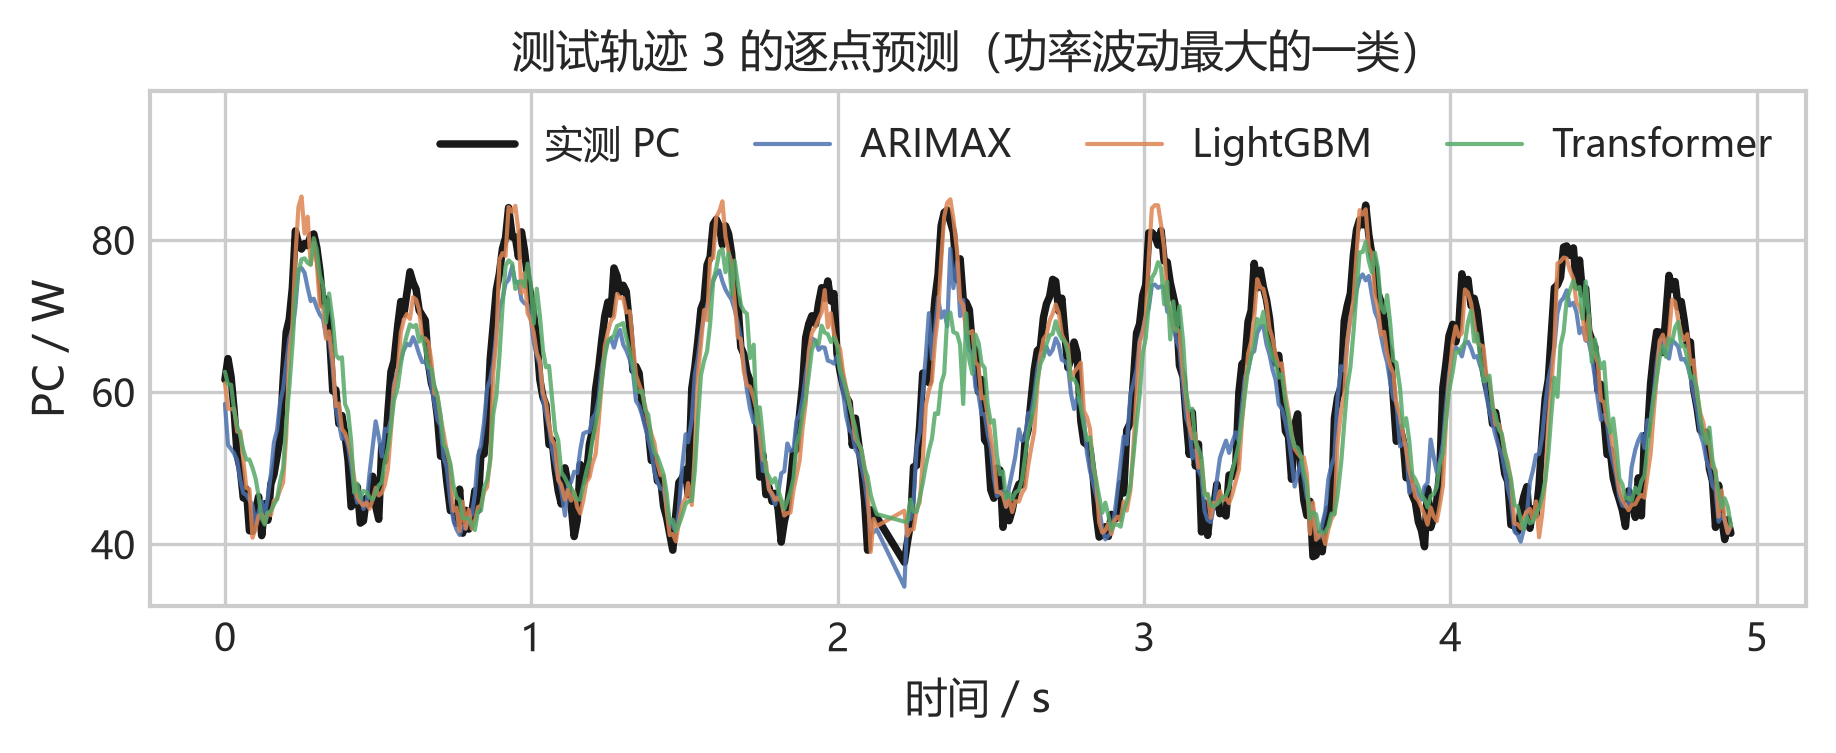

[saved] figures\train_test\08b_traj1_pred.png  (300 dpi)


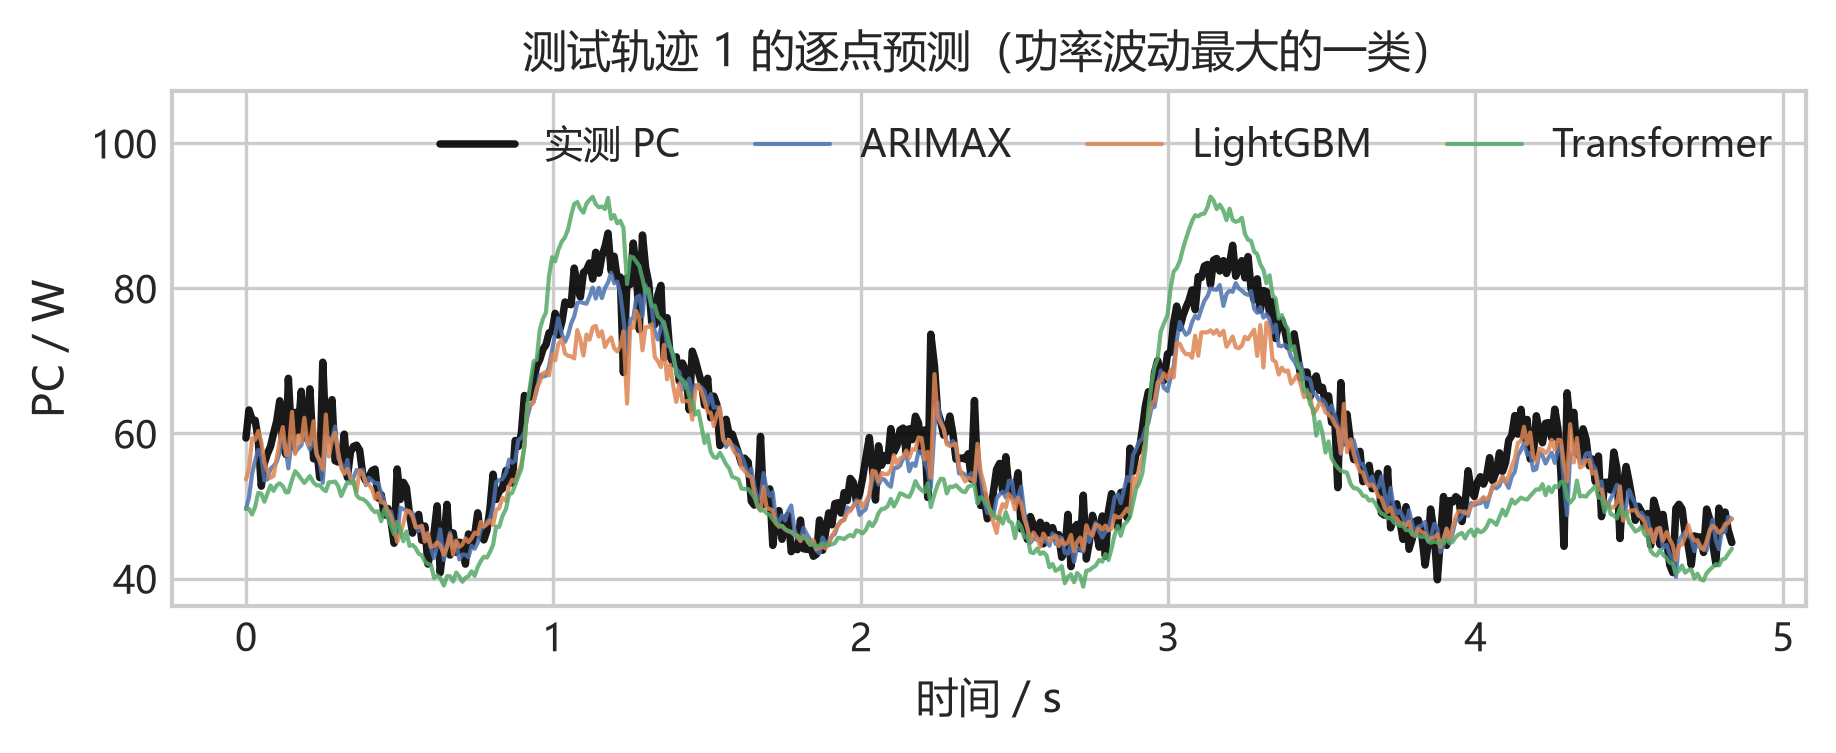

[saved] figures\train_test\08c_scatter_resid.png  (300 dpi)


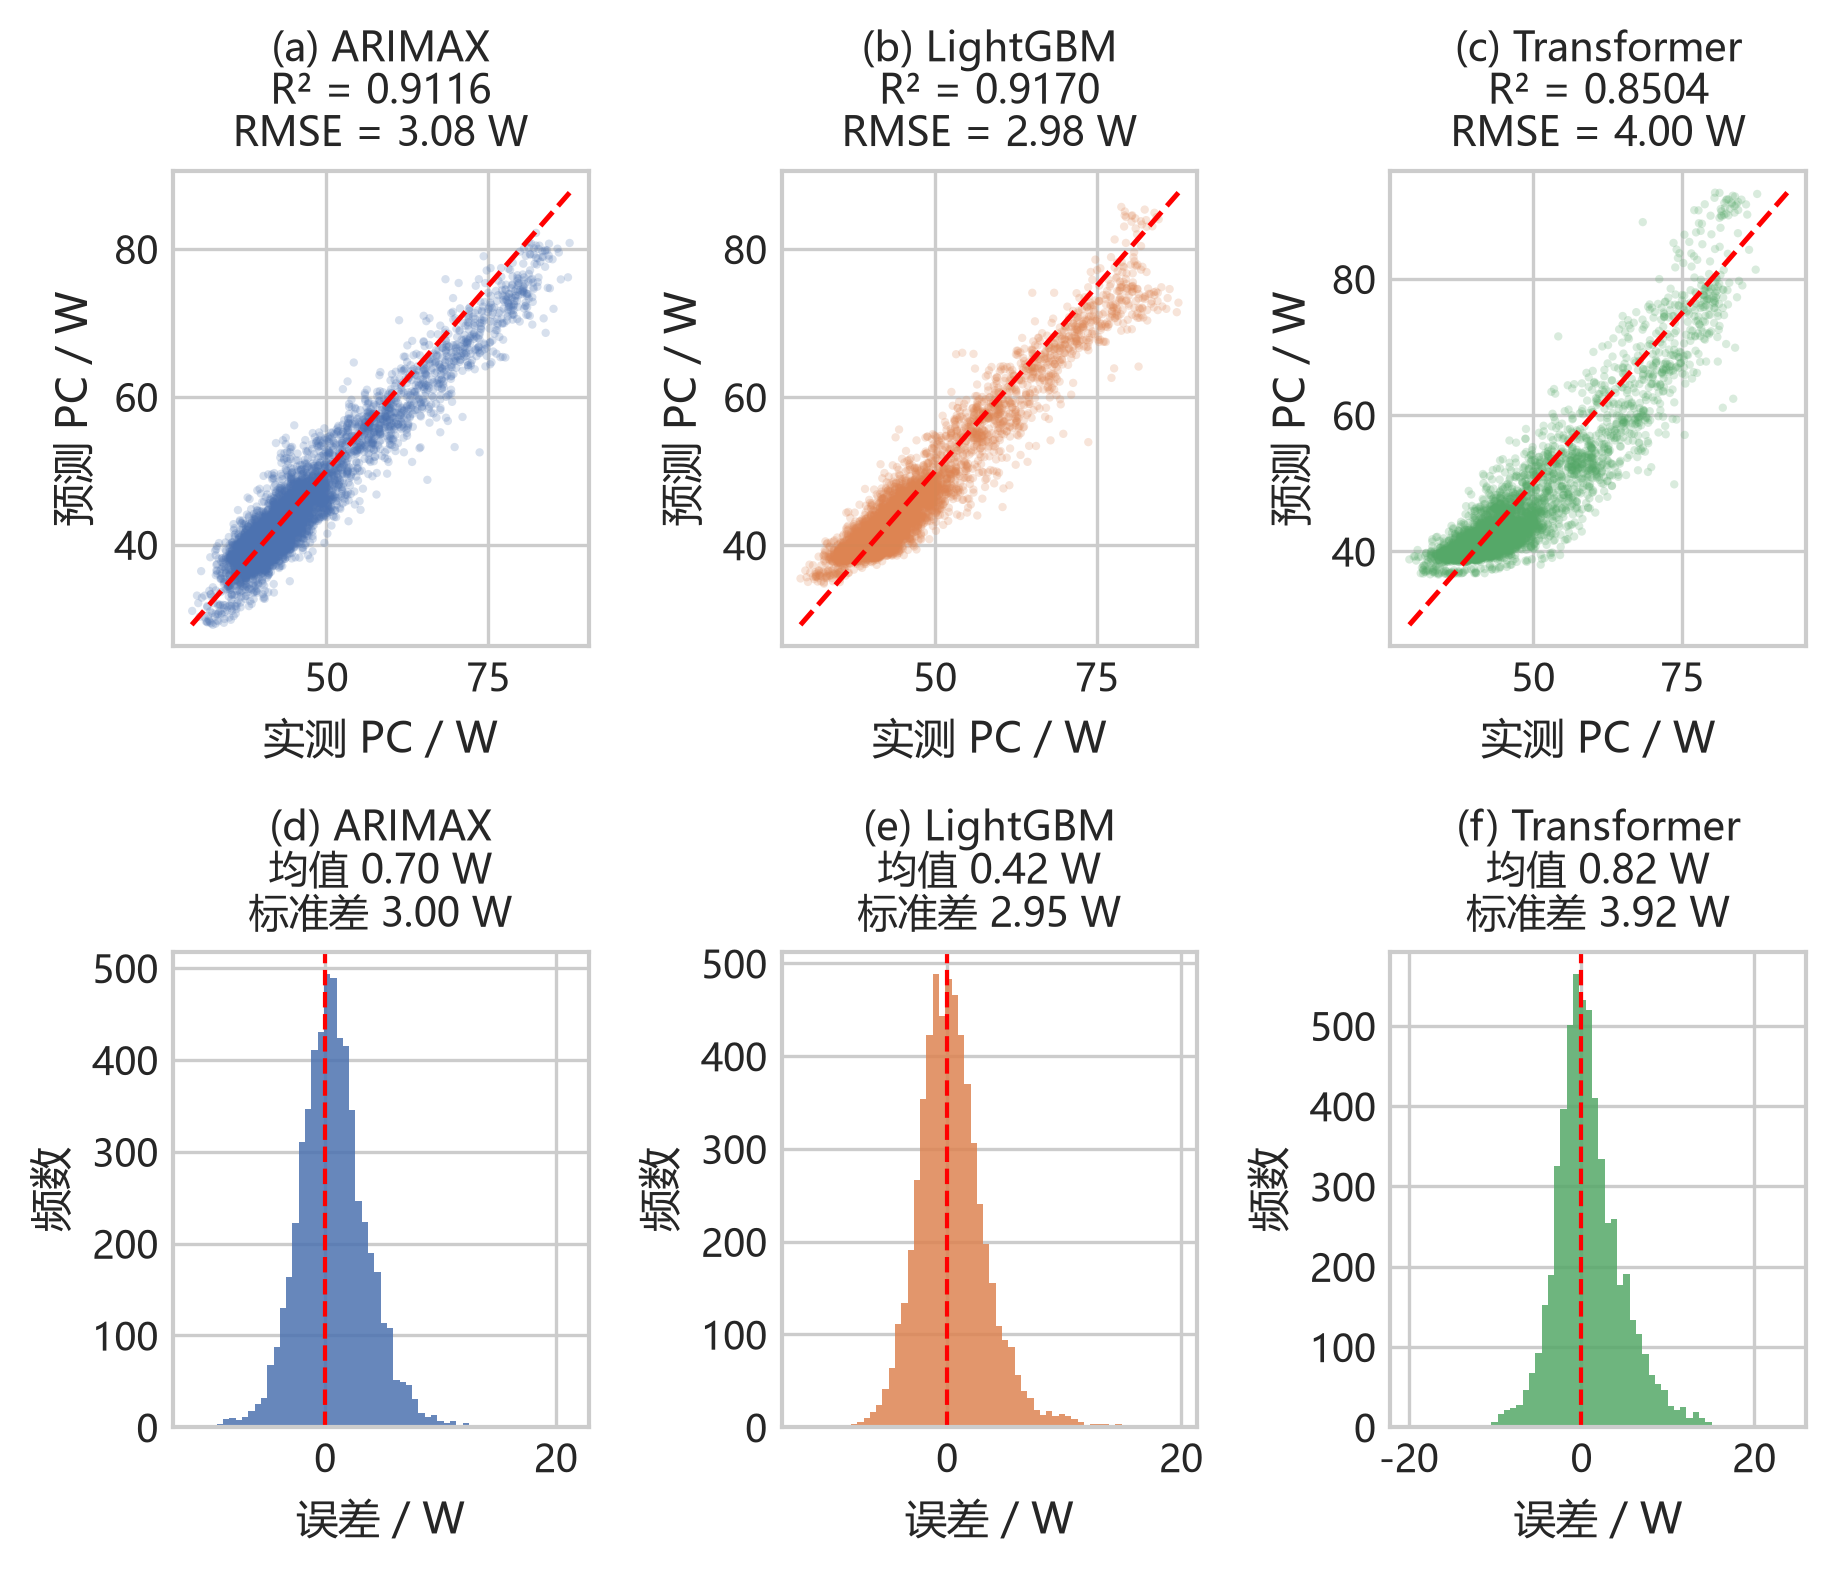

[saved] figures\train_test\08d_traj_rmse.png  (300 dpi)


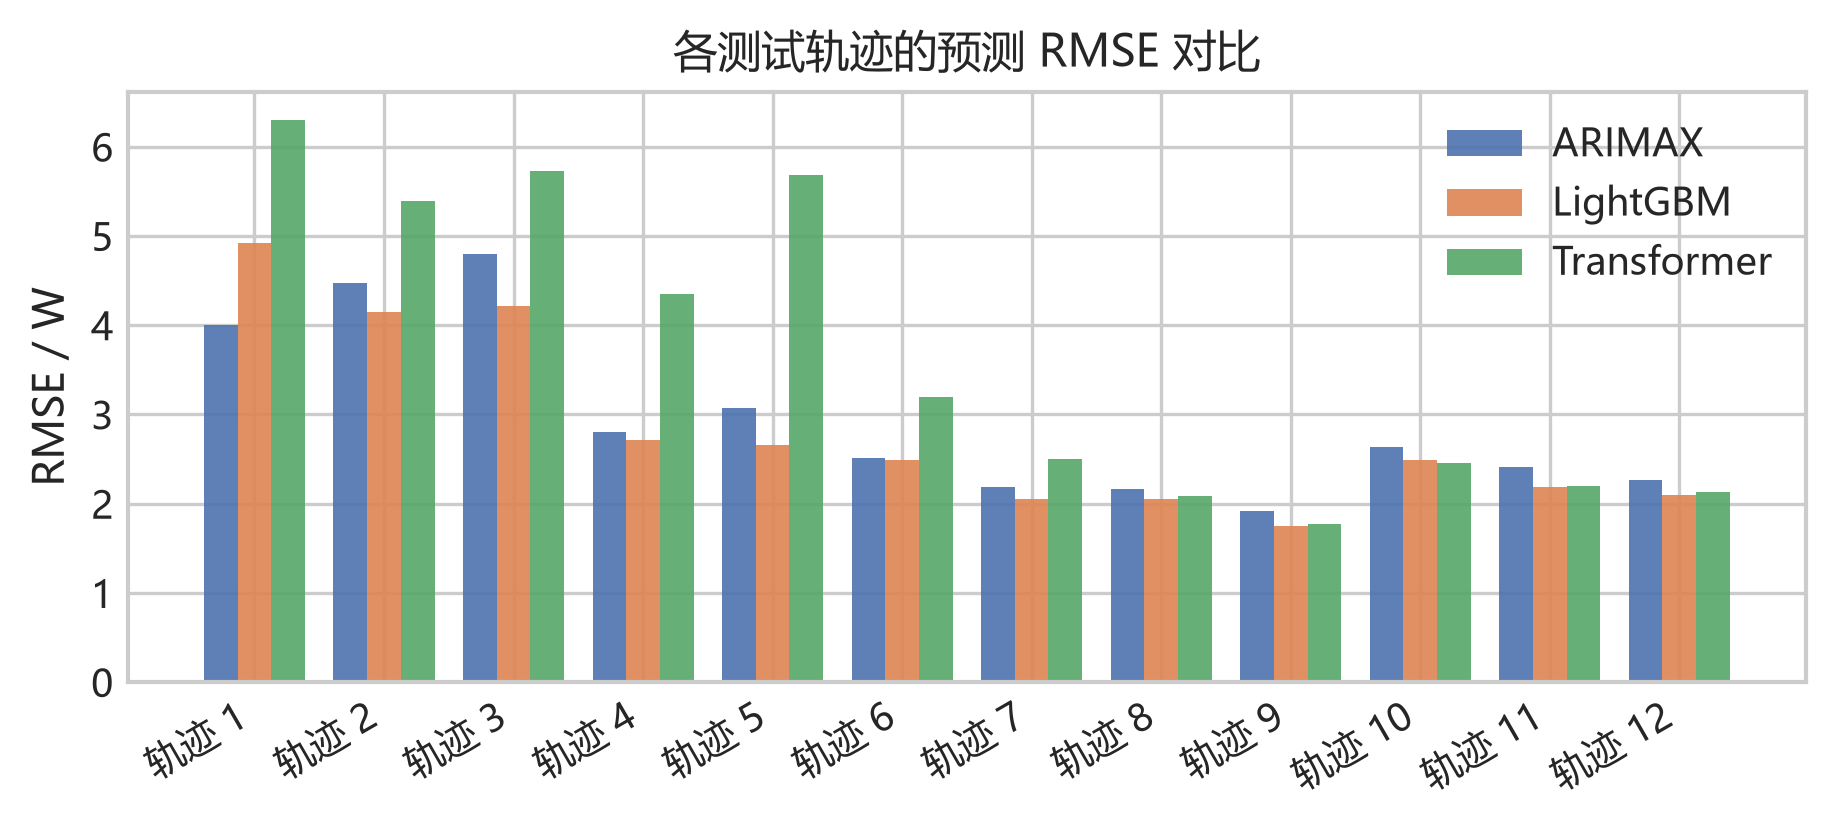

In [9]:
COLORS = {"ARIMAX": "#4C72B0", "LightGBM": "#DD8452", "Transformer": "#55A868"}

# ---------- 8.1 典型轨迹的逐点预测（每条轨迹一张图） ----------
traj_sel = (
    pd.DataFrame({"tid": tid_te, "y": Y_te})
    .groupby("tid")["y"].agg(["std", "count"])
    .query("count >= 300")
    .sort_values("std", ascending=False)
    .head(2)
    .index.tolist()
)

for tid, tag in zip(traj_sel, "ab"):
    m = tid_te == tid
    fig, ax = plt.subplots(figsize=fig_size(0.42))
    ax.plot(t_te[m] - t_te[m][0], Y_te[m], "k-", lw=1.8, alpha=0.9, label="实测 PC")
    for name, p in PRED.items():
        ax.plot(t_te[m] - t_te[m][0], p[m], lw=1.0, alpha=0.85, color=COLORS[name], label=name)
    ax.set_title(f"测试轨迹 {int(tid)} 的逐点预测（功率波动最大的一类）", fontsize=FS_TITLE)
    ax.set_xlabel("时间 / s", fontsize=FS_LABEL)
    ax.set_ylabel("PC / W", fontsize=FS_LABEL)
    ax.tick_params(labelsize=FS_TICK)
    ax.legend(ncol=4, fontsize=FS_LEGEND, loc="upper right", framealpha=0.9)
    _lo, _hi = ax.get_ylim()
    ax.set_ylim(_lo, _hi + 0.20 * (_hi - _lo))
    fig.tight_layout()
    savefig(fig, f"08{tag}_traj{int(tid)}_pred")
    plt.show()

# ---------- 8.2 三模型的预测-实测散点与残差分布（同类图罗列，保留 2×3） ----------
fig, axes = plt.subplots(2, 3, figsize=fig_size(0.86))
for j, (name, p) in enumerate(PRED.items()):
    ax = axes[0, j]
    ax.scatter(Y_te, p, s=4, alpha=0.22, color=COLORS[name], edgecolors="none")
    lo = min(Y_te.min(), p.min())
    hi = max(Y_te.max(), p.max())
    ax.plot([lo, hi], [lo, hi], "r--", lw=1.2)
    tag_title(ax, "abc"[j],
              f"{name}\nR² = {r2_score(Y_te, p):.4f}\nRMSE = "
              f"{math.sqrt(mean_squared_error(Y_te, p)):.2f} W", fontsize=9.5)
    ax.set_xlabel("实测 PC / W", fontsize=FS_LABEL)
    ax.set_ylabel("预测 PC / W", fontsize=FS_LABEL)
    ax.tick_params(labelsize=FS_TICK)

    ax2 = axes[1, j]
    err = Y_te - p
    ax2.hist(err, bins=60, color=COLORS[name], alpha=0.85)
    ax2.axvline(0, color="r", ls="--", lw=1)
    tag_title(ax2, "def"[j],
              f"{name}\n均值 {err.mean():.2f} W\n标准差 {err.std():.2f} W", fontsize=9.5)
    ax2.set_xlabel("误差 / W", fontsize=FS_LABEL)
    ax2.set_ylabel("频数", fontsize=FS_LABEL)
    ax2.tick_params(labelsize=FS_TICK)
fig.tight_layout()
savefig(fig, "08c_scatter_resid")
plt.show()

# ---------- 8.3 逐轨迹 RMSE ----------
fig, ax = plt.subplots(figsize=fig_size(0.46))
x = np.arange(len(traj_rmse))
width = 0.26
for k, name in enumerate(PRED):
    ax.bar(x + (k - 1) * width, traj_rmse[name], width, label=name, color=COLORS[name], alpha=0.9)
ax.set_xticks(x)
ax.set_xticklabels([f"轨迹 {t}" for t in traj_rmse["trajectory_id"]], rotation=30, ha="right",
                   fontsize=FS_TICK)
ax.set_ylabel("RMSE / W", fontsize=FS_LABEL)
ax.set_title("各测试轨迹的预测 RMSE 对比", fontsize=FS_TITLE)
ax.tick_params(labelsize=FS_TICK)
ax.legend(fontsize=FS_LEGEND)
fig.tight_layout()
savefig(fig, "08d_traj_rmse")
plt.show()

## 9. 可解释性分析

三个模型的可解释性粒度不同：

| 模型 | 可解释性来源 | 粒度 |
| --- | --- | --- |
| ARIMAX | 标准化回归系数 $\phi_l,\beta_l$；线性 SHAP | 全局、单特征×滞后阶；精确且可加 |
| LightGBM | 增益（gain）重要度；TreeSHAP | 全局 + 单样本；SHAP 精确且可加 |
| Transformer | 注意力权重；GradientSHAP（近似） | 时序关注分布 + 近似归因，注意力≠因果贡献 |

下面先看各模型自带的重要度（9.1–9.3），再用 SHAP 在**同一量纲（W）**下做跨模型比较（9.4）。

[saved] figures\train_test\09a_arimax_coef.png  (300 dpi)


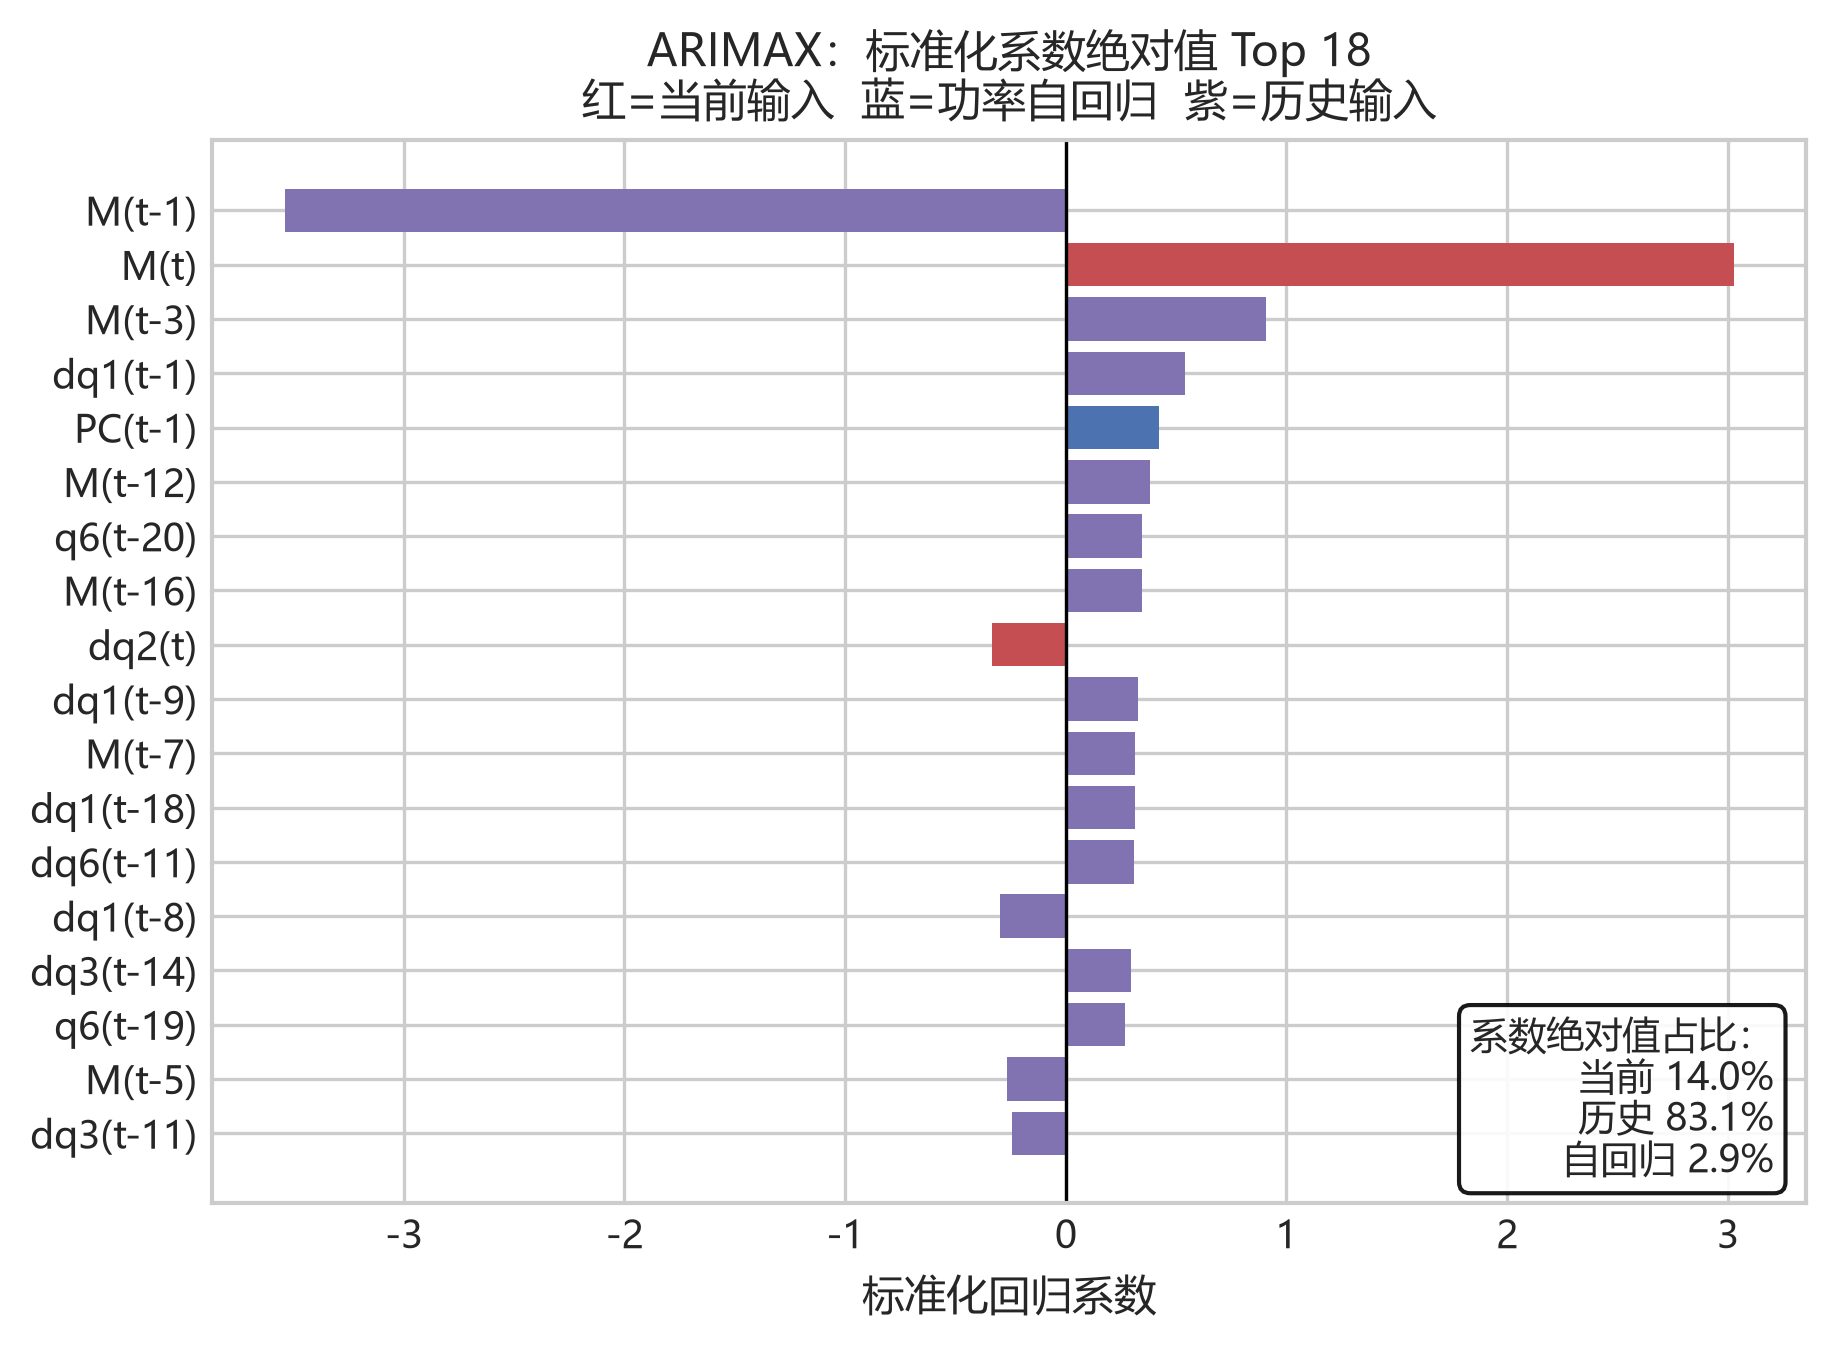

[saved] figures\train_test\09b_lgb_gain.png  (300 dpi)


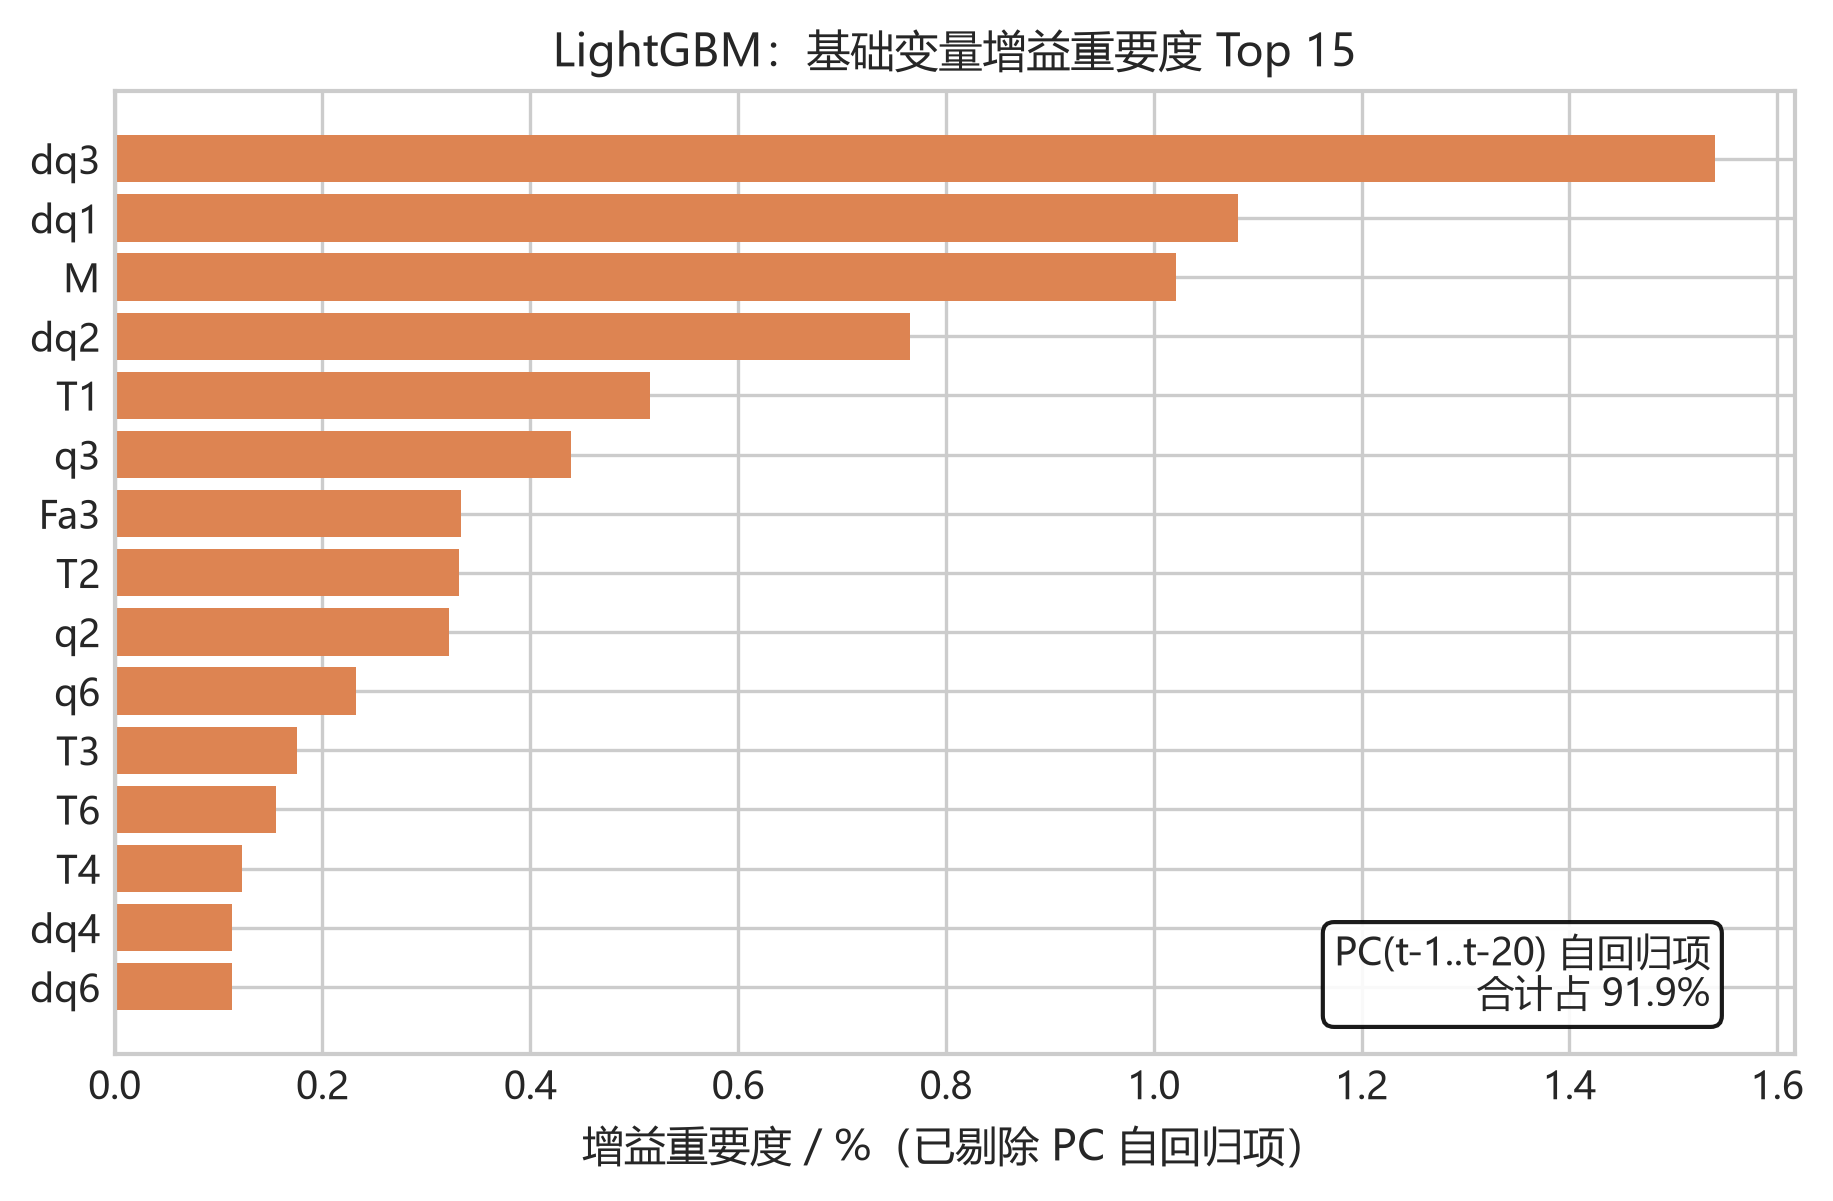

LightGBM 增益占比（%）：
当前输入 x(t)               0.76
历史输入 x(t-1..t-20)       7.33
功率自回归 PC(t-1..t-20)    91.92


In [10]:
LBL_CUR = "当前输入 x(t)"
LBL_HIS = f"历史输入 x(t-1..t-{LAGS})"
LBL_AR = f"功率自回归 PC(t-1..t-{LAGS})"


def split_share(values, names):
    """把重要度拆成：当前输入 / 历史输入 / 功率自回归 三部分（不重复计数）。"""
    values = np.asarray(values, dtype=float)
    cur = np.array([n.endswith("(t)") for n in names])
    ar = np.array([n.startswith("PC(") for n in names])
    return pd.Series({
        LBL_CUR: values[cur].sum(),
        LBL_HIS: values[~cur & ~ar].sum(),
        LBL_AR: values[ar].sum(),
    })


# ---------- 9.1 ARIMAX：标准化系数绝对值 Top 18（单图，纵向拉长） ----------
coef = pd.Series(w_arx, index=FLAT_NAMES)
top_coef = coef.reindex(coef.abs().sort_values(ascending=False).head(18).index)[::-1]
bar_colors = [
    "#C44E52" if n.endswith("(t)") else ("#4C72B0" if n.startswith("PC(") else "#8172B2")
    for n in top_coef.index
]
fig, ax = plt.subplots(figsize=fig_size(0.74))
ax.barh(range(len(top_coef)), top_coef.values, color=bar_colors)
ax.set_yticks(range(len(top_coef)))
ax.set_yticklabels(top_coef.index, fontsize=FS_TICK)
ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("标准化回归系数", fontsize=FS_LABEL)
ax.set_title("ARIMAX：标准化系数绝对值 Top 18\n红=当前输入  蓝=功率自回归  紫=历史输入",
             fontsize=FS_TITLE)
ax.tick_params(axis="x", labelsize=FS_TICK)

share_arx = split_share(coef.abs().values, list(coef.index))
share_arx = share_arx / share_arx.sum() * 100
ax.text(0.98, 0.02,
        "系数绝对值占比：\n"
        f"  当前 {share_arx[LBL_CUR]:.1f}%\n"
        f"  历史 {share_arx[LBL_HIS]:.1f}%\n"
        f"  自回归 {share_arx[LBL_AR]:.1f}%",
        transform=ax.transAxes, fontsize=FS_TICK, va="bottom", ha="right",
        bbox=dict(boxstyle="round", fc="white", alpha=0.9))
fig.tight_layout()
savefig(fig, "09a_arimax_coef")
plt.show()

# ---------- 9.2 LightGBM：按基础变量聚合的增益重要度（单图，纵向拉长） ----------
gain = pd.Series(
    model_lgb.feature_importance(importance_type="gain", iteration=model_lgb.best_iteration),
    index=FLAT_NAMES, dtype=float,
)
gain = gain / gain.sum() * 100
gain_base = gain.groupby([n.split("(")[0] for n in gain.index]).sum().sort_values(ascending=False)
pc_share = gain_base["PC"]
gain_base_wo_pc = gain_base.drop("PC").head(15)

fig, ax = plt.subplots(figsize=fig_size(0.66))
ax.barh(range(len(gain_base_wo_pc)), gain_base_wo_pc.values, color="#DD8452")
ax.set_yticks(range(len(gain_base_wo_pc)))
ax.set_yticklabels(gain_base_wo_pc.index, fontsize=FS_TICK)
ax.invert_yaxis()
ax.set_xlabel("增益重要度 / %（已剔除 PC 自回归项）", fontsize=FS_LABEL)
ax.set_title("LightGBM：基础变量增益重要度 Top 15", fontsize=FS_TITLE)
ax.text(0.95, 0.05, f"PC(t-1..t-{LAGS}) 自回归项\n合计占 {pc_share:.1f}%",
        transform=ax.transAxes, fontsize=FS_TICK, ha="right",
        bbox=dict(boxstyle="round", fc="white", alpha=0.9))
fig.tight_layout()
savefig(fig, "09b_lgb_gain")
plt.show()

share_lgb = split_share(gain.values, list(gain.index))
print("LightGBM 增益占比（%）：")
print((share_lgb / share_lgb.sum() * 100).round(2).to_string())

[saved] figures\train_test\09c_attn_heatmap.png  (300 dpi)


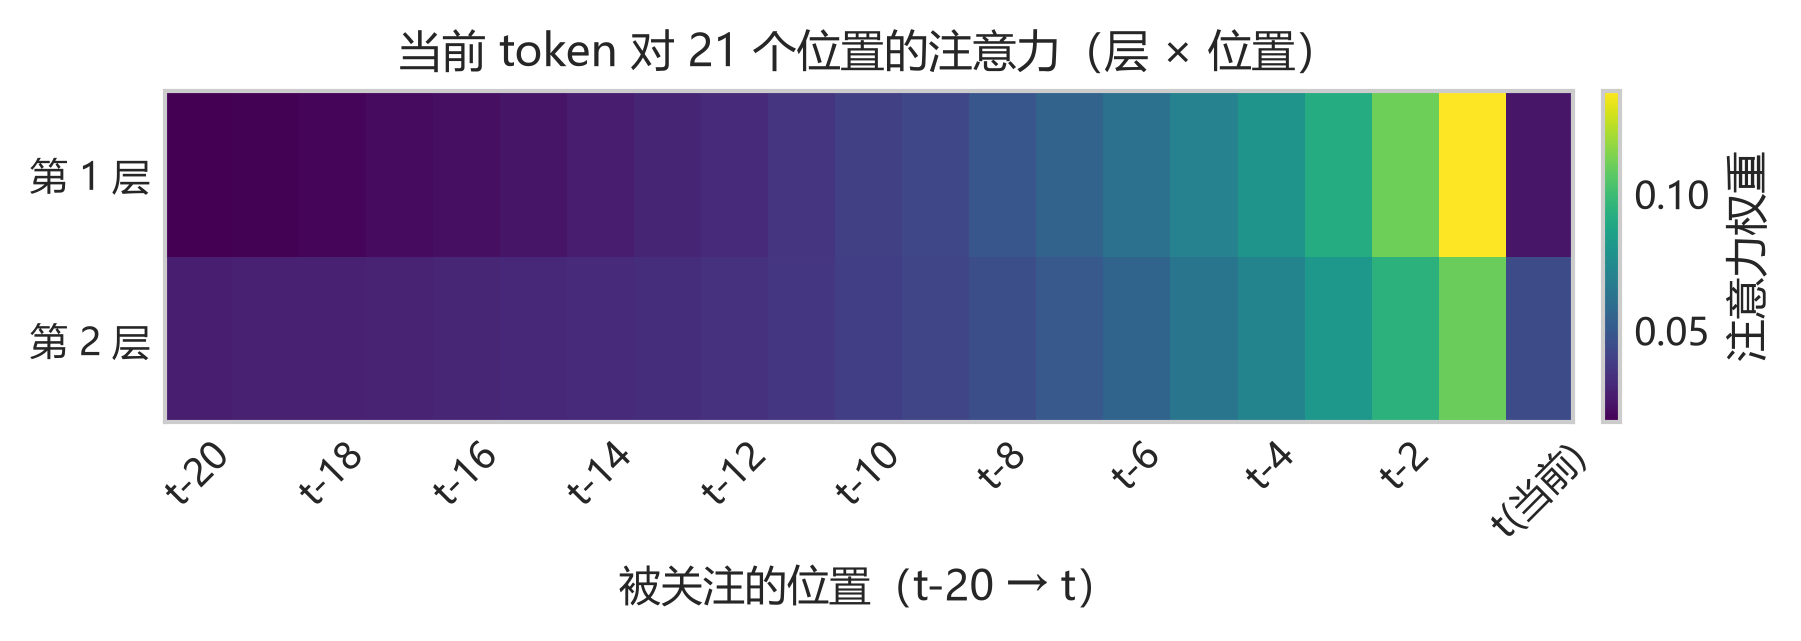

[saved] figures\train_test\09d_attn_avg.png  (300 dpi)


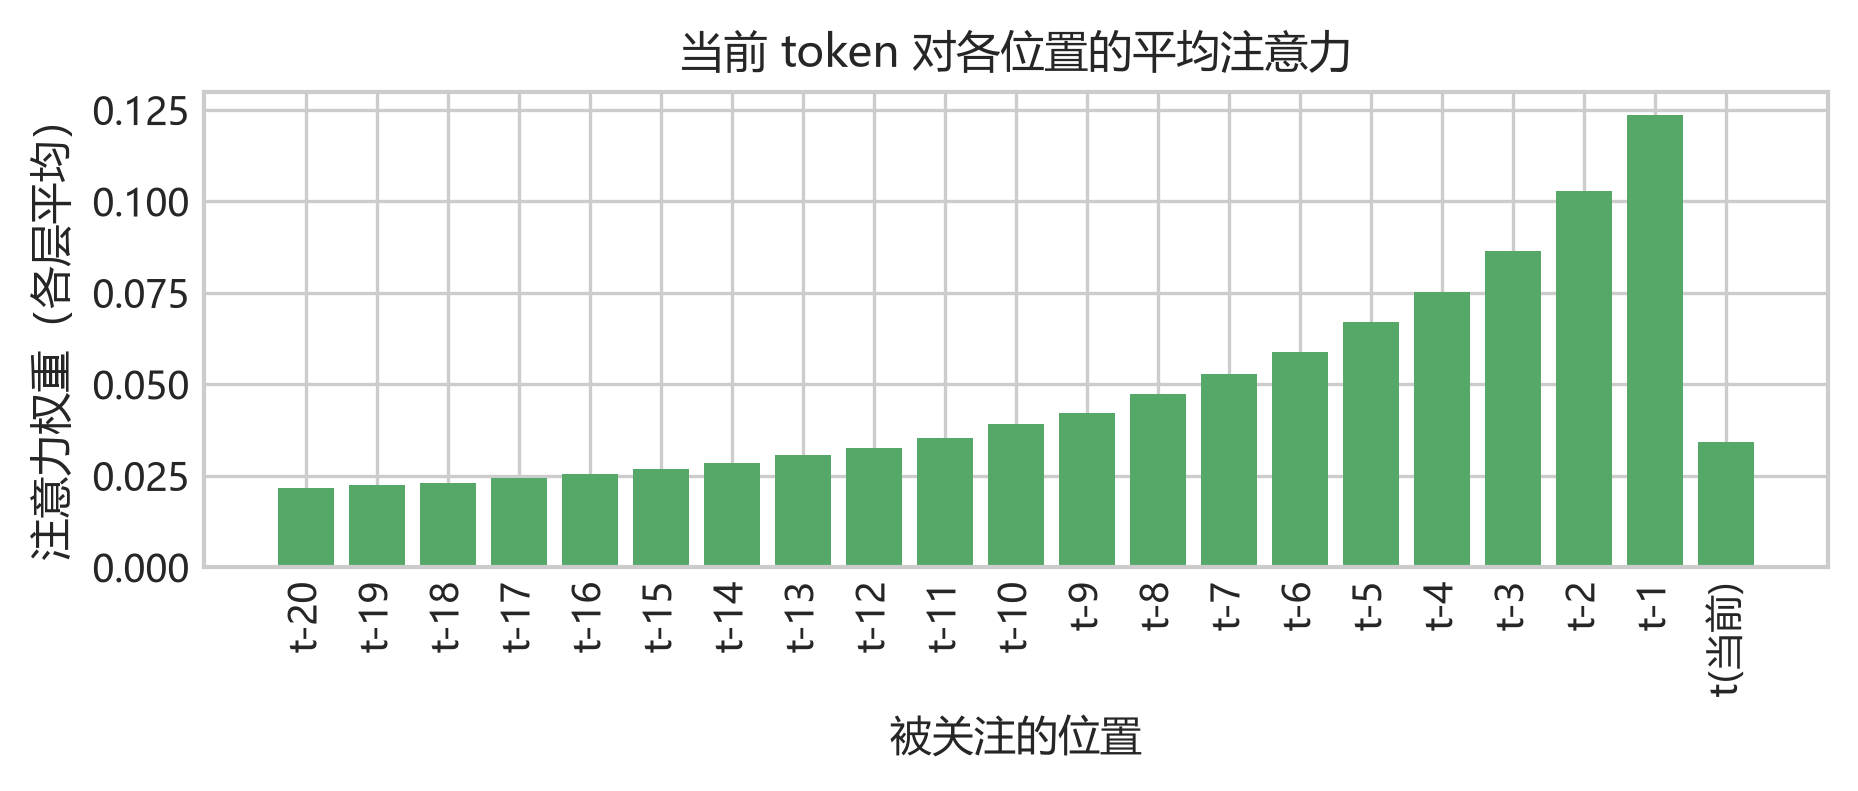

最后一层当前 token 的注意力（头平均、测试集平均）：
     t-20: 0.0267
     t-19: 0.0274
     t-18: 0.0276
     t-17: 0.0285
     t-16: 0.0294
     t-15: 0.0302
     t-14: 0.0310
     t-13: 0.0325
     t-12: 0.0338
     t-11: 0.0355
     t-10: 0.0389
      t-9: 0.0420
      t-8: 0.0457
      t-7: 0.0502
      t-6: 0.0557
      t-5: 0.0637
      t-4: 0.0714
      t-3: 0.0813
      t-2: 0.0944
      t-1: 0.1098
    t(当前): 0.0444
注意力峰值位置: t-1


In [11]:
# ---------- 9.3 Transformer：注意力分布（手动计算，兼容 need_weights=False） ----------
def compute_attention(model, seq, cur):
    layers = model.encoder.layers
    for layer in layers:                      # 清理可能残留的 hook
        layer.self_attn._forward_hooks.clear()
        layer.self_attn._forward_pre_hooks.clear()

    x_in = {}
    handles = [
        layer.self_attn.register_forward_pre_hook(
            lambda mod, args, i=i: x_in.__setitem__(i, args[0].detach()))
        for i, layer in enumerate(layers)
    ]
    was_training = model.training
    model.eval()
    with torch.no_grad():
        model(seq, cur)
    for h in handles:
        h.remove()
    if was_training:
        model.train()

    maps = []
    for i, layer in enumerate(layers):
        m = layer.self_attn
        x = x_in[i]
        B, N, D = x.shape
        q, k, _ = torch.nn.functional.linear(x, m.in_proj_weight, m.in_proj_bias).chunk(3, dim=-1)
        hd = D // m.num_heads
        q = q.view(B, N, m.num_heads, hd).transpose(1, 2)
        k = k.view(B, N, m.num_heads, hd).transpose(1, 2)
        att = torch.softmax(q @ k.transpose(-1, -2) / math.sqrt(hd), dim=-1)
        maps.append(att.mean(dim=(0, 1)).detach().cpu().numpy())   # 对样本与注意力头取平均
    return np.stack(maps)


A = compute_attention(model_tf,
                      torch.from_numpy(S_te[:1024]).to(DEVICE),
                      torch.from_numpy(C_te[:1024]).to(DEVICE))  # (层数, L+1, L+1)
labels = [f"t-{LAGS - i}" for i in range(LAGS)] + ["t(当前)"]
_POS = list(range(0, LAGS + 1, 2))          # 隔点显示，避免 21 个标签互相挤压

# ---------- 09c 注意力热图（层 × 位置） ----------
fig, ax = plt.subplots(figsize=fig_size(0.36))
im = ax.imshow(A[:, -1, :], aspect="auto", cmap="viridis"); ax.grid(False)
ax.set_xticks(_POS)
ax.set_xticklabels([labels[i] for i in _POS], fontsize=FS_TICK, rotation=45)
ax.set_yticks(range(A.shape[0]))
ax.set_yticklabels([f"第 {i + 1} 层" for i in range(A.shape[0])], fontsize=FS_TICK)
ax.set_xlabel("被关注的位置（t-20 → t）", fontsize=FS_LABEL)
ax.set_title(f"当前 token 对 {LAGS + 1} 个位置的注意力（层 × 位置）", fontsize=FS_TITLE)
ax.tick_params(labelsize=FS_TICK)
cb = fig.colorbar(im, ax=ax, fraction=0.05, pad=0.02)
cb.ax.tick_params(labelsize=FS_TICK)
cb.set_label("注意力权重", fontsize=FS_LABEL)
fig.tight_layout()
savefig(fig, "09c_attn_heatmap")
plt.show()

# ---------- 09d 各位置的平均注意力 ----------
fig, ax = plt.subplots(figsize=fig_size(0.44))
ax.bar(range(LAGS + 1), A.mean(0)[-1], color="#55A868")
ax.set_xticks(range(LAGS + 1))
ax.set_xticklabels(labels, fontsize=FS_TICK, rotation=90)
ax.set_xlabel("被关注的位置", fontsize=FS_LABEL)
ax.set_ylabel("注意力权重（各层平均）", fontsize=FS_LABEL)
ax.set_title("当前 token 对各位置的平均注意力", fontsize=FS_TITLE)
ax.tick_params(labelsize=FS_TICK)
fig.tight_layout()
savefig(fig, "09d_attn_avg")
plt.show()

last = A[-1, -1, :]
print("最后一层当前 token 的注意力（头平均、测试集平均）：")
for name, v in zip(labels, last):
    print(f"  {name:>7s}: {v:.4f}")
print("注意力峰值位置:", labels[int(np.argmax(last))])

### 9.4 SHAP：跨模型的统一归因（ARIMAX / LightGBM / Transformer）

9.1–9.3 分别用回归系数、树增益和注意力权重解释各模型，但这三者量纲不同、不可直接比较。SHAP 基于合作博弈的 Shapley 值，把预测值分解为「基线 + 各特征贡献之和」，是唯一能在三类模型间横向对比的归因框架：

| 模型 | 解释器 | 说明 |
|---|---|---|
| ARIMAX | 线性 SHAP（精确解） | 对线性模型有解析解 $\phi_j = w_j(x_j - \mathbb{E}x_j)$，无采样误差 |
| LightGBM | `shap.TreeExplainer` | TreeSHAP 在树上精确计算，同时给出基线与逐样本贡献 |
| Transformer | `shap.GradientExplainer` | 以 100 条背景样本做期望梯度近似，属采样估计，故仅用于**相对**排序 |

SHAP 值统一换算到功率量纲（W），并校验可加性 $\sum_j \phi_j + \mathbb{E}[f] = f(x)$。由于 20 阶滞后之间、以及 $M$ 与 $d\dot q$ 之间存在强共线性，ARIMAX 的绝对 |SHAP| 会被分摊放大并相互抵消，因此**跨模型比较统一采用"占该模型自身总 |SHAP| 的百分比"**。

为便于对照，所有逐步归因结果再聚合到三个语义组：**当前输入** $x_t$、**历史输入** $x_{t-1..t-20}$、**功率自回归** $\mathrm{PC}_{t-1..t-20}$。

LightGBM SHAP 矩阵 (600, 545) | 基线 E[f(X)] = 44.171 W
SHAP 可加性检查（平均绝对误差）= 4.68e-14 W

按基础变量聚合的平均 |SHAP| / W（Top 15）


,ARIMAX（线性SHAP）,LightGBM（TreeSHAP）
PC,7.176,7.128
M,85.747,0.542
dq1,31.910,0.254
T1,1.171,0.227
q2,3.239,0.164
dq3,11.208,0.145
T2,0.446,0.142
dq2,15.727,0.132
Fz,1.633,0.117
T3,0.269,0.109


相对重要度（占该模型总 |SHAP| 的百分比，Top 15）


,ARIMAX（线性SHAP）,LightGBM（TreeSHAP）
PC,2.82,70.79
M,33.72,5.38
dq1,12.55,2.52
T1,0.46,2.25
q2,1.27,1.63
dq3,4.41,1.44
T2,0.18,1.41
dq2,6.18,1.31
Fz,0.64,1.16
T3,0.11,1.08


SHAP 贡献占比（%）


,当前输入 x(t),历史输入 x(t-1..t-20),功率自回归 PC(t-1..t-20)
ARIMAX,14.48,82.69,2.82
LightGBM,4.68,24.53,70.79


[saved] figures\train_test\09e_shap_importance.png  (300 dpi)


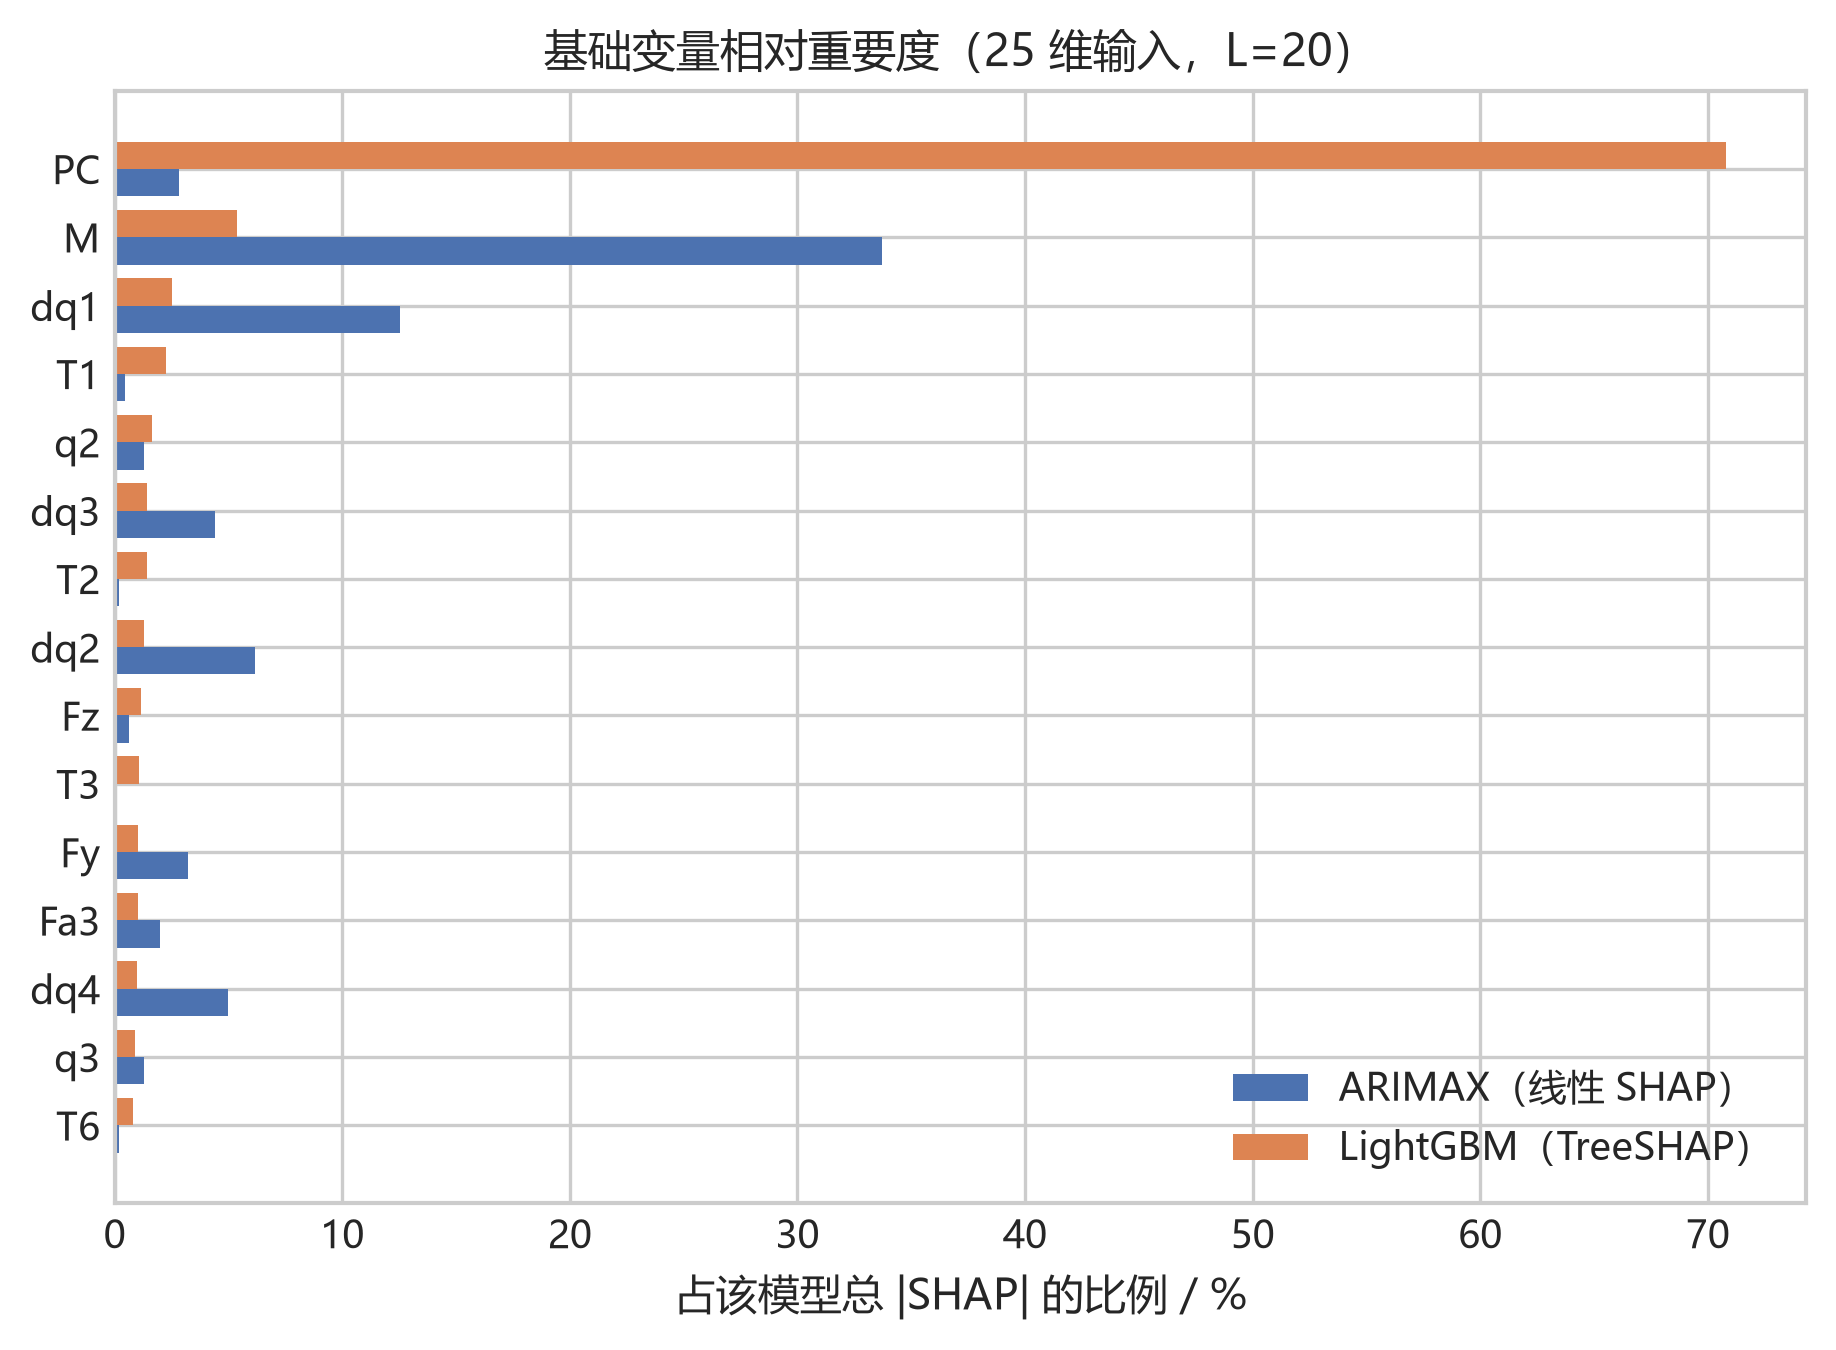

[saved] figures\train_test\09f_shap_share.png  (300 dpi)


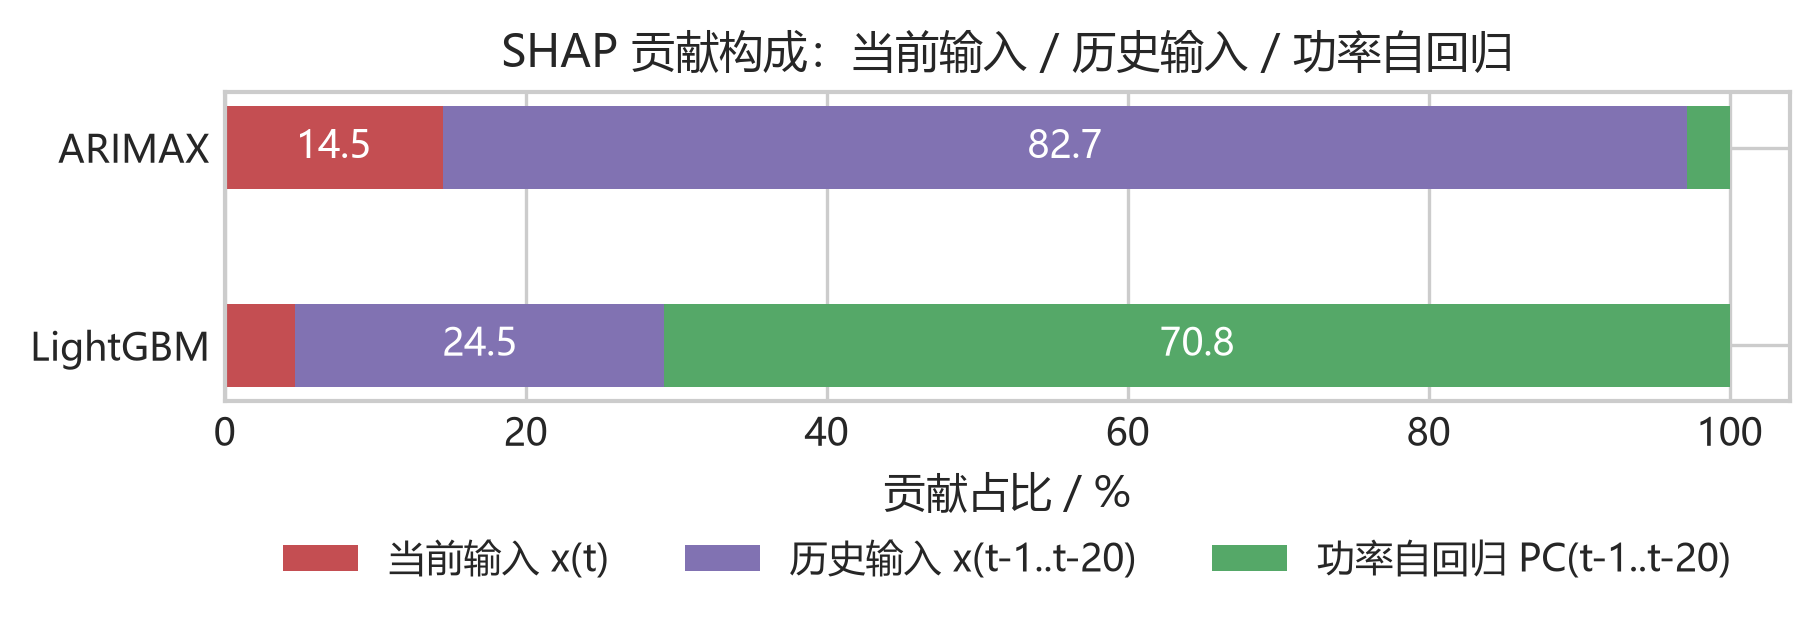

[saved] figures\train_test\09g_shap_beeswarm.png  (300 dpi)


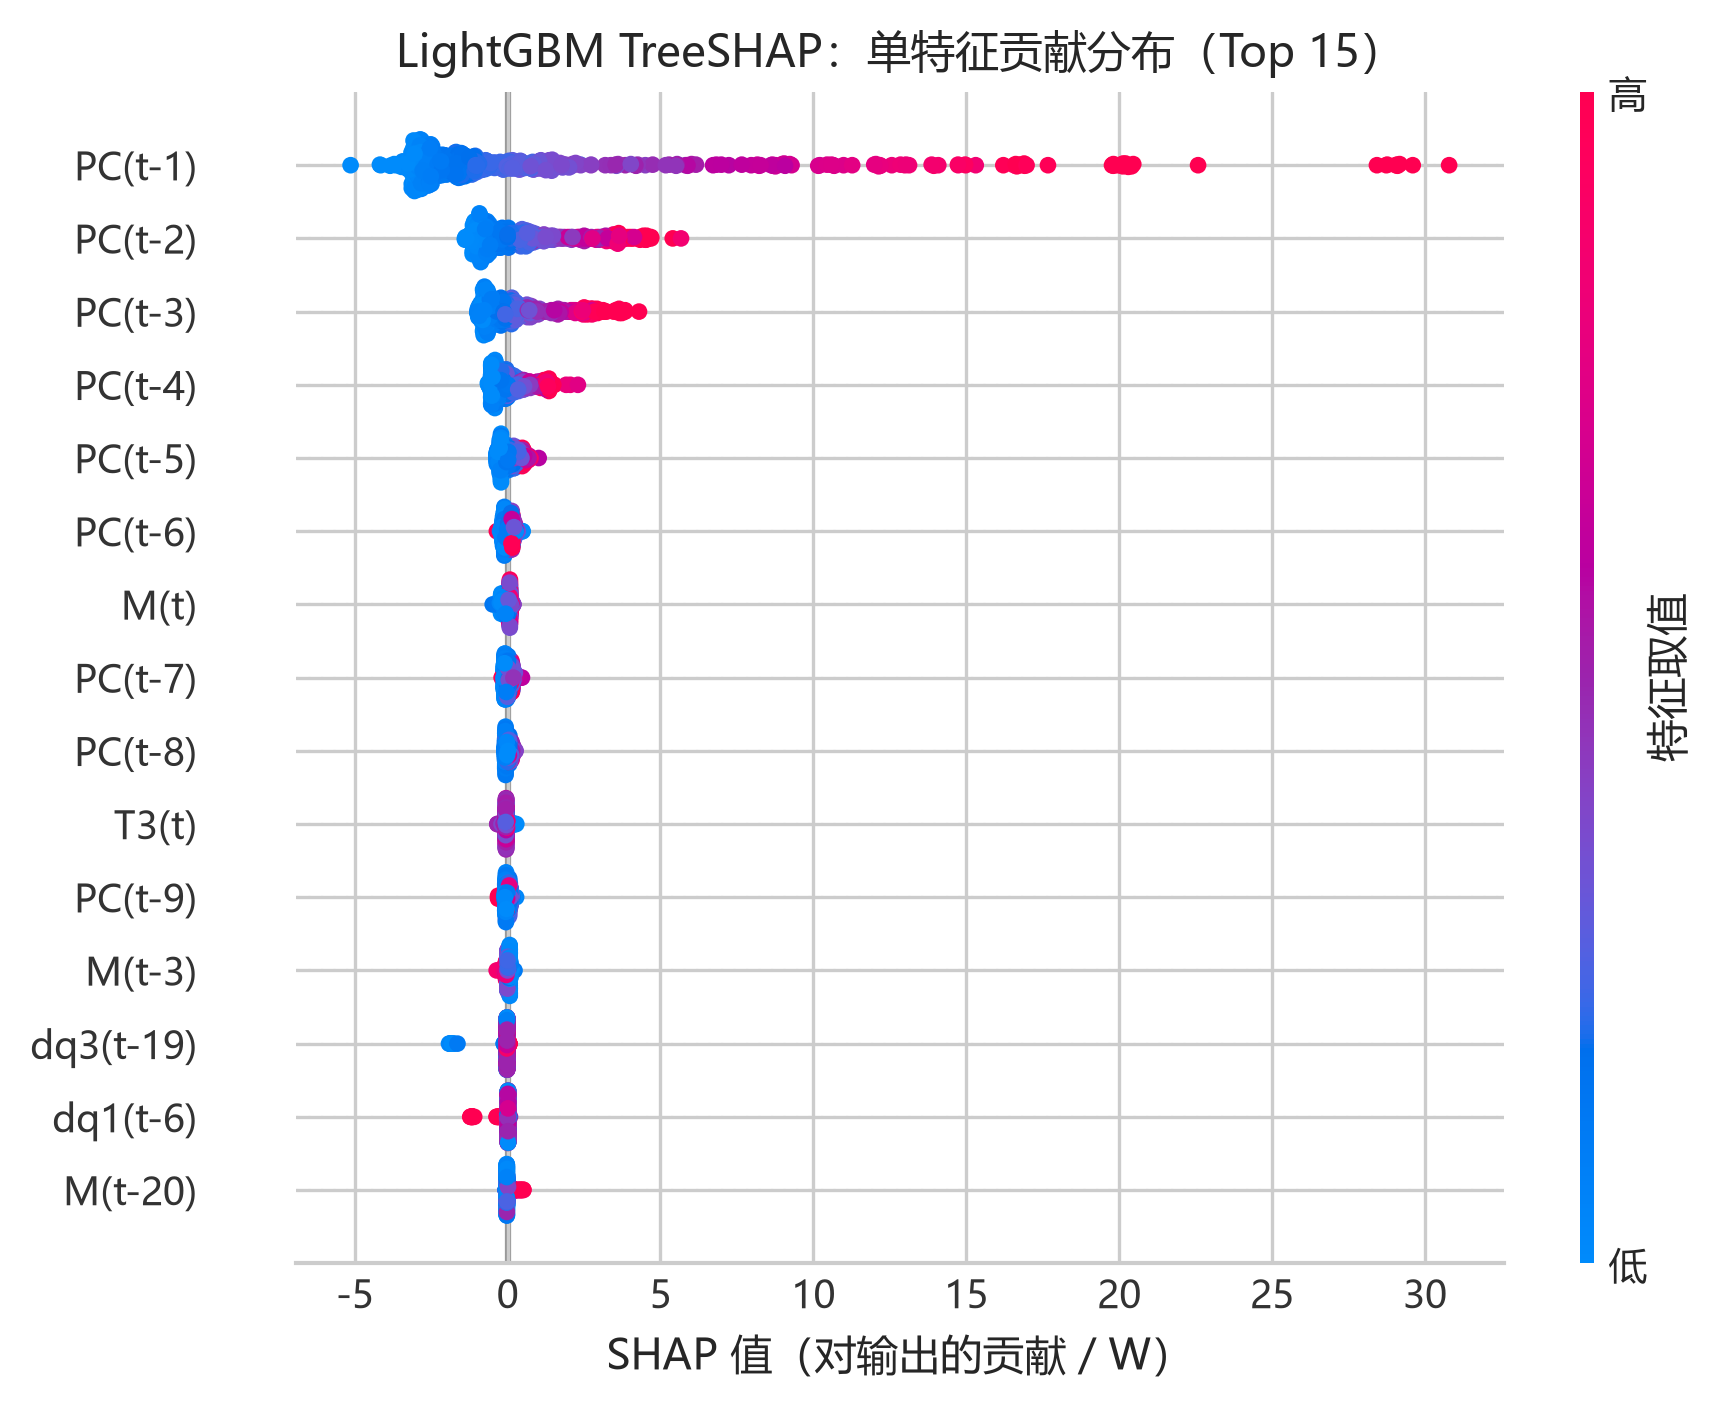

In [12]:
import shap

rng = np.random.default_rng(SEED)
N_SHAP = 600
shap_idx = rng.choice(len(Y_te), size=min(N_SHAP, len(Y_te)), replace=False)
X_shap = F_te[shap_idx]
y_shap = Y_te[shap_idx]

# ---------- 9.4.1 ARIMAX：精确线性 SHAP ----------
base_x = F_tr.mean(0).astype(np.float64)          # 训练集均值作为基线
shap_arx_w = (X_shap - base_x) * w_arx * y_sd      # 换算到 W
imp_arx = np.abs(shap_arx_w).mean(0)

# ---------- 9.4.2 LightGBM：TreeSHAP ----------
explainer_lgb = shap.TreeExplainer(model_lgb)
shap_lgb = np.asarray(explainer_lgb.shap_values(X_shap))
base_value = float(np.ravel(explainer_lgb.expected_value)[0])
imp_lgb = np.abs(shap_lgb).mean(0)

print(f"LightGBM SHAP 矩阵 {shap_lgb.shape} | 基线 E[f(X)] = {base_value:.3f} W")
recon = shap_lgb.sum(1) + base_value
pred_lgb = model_lgb.predict(X_shap, num_iteration=model_lgb.best_iteration)
print(f"SHAP 可加性检查（平均绝对误差）= {np.abs(recon - pred_lgb).mean():.2e} W")


def base_importance(values, names):
    s = pd.Series(np.asarray(values), index=names)
    return s.groupby([n.split("(")[0] for n in s.index]).sum()


imp_arx_base = base_importance(imp_arx, FLAT_NAMES)
imp_lgb_base = base_importance(imp_lgb, FLAT_NAMES)

shap_table = pd.DataFrame({"ARIMAX（线性SHAP）": imp_arx_base,
                           "LightGBM（TreeSHAP）": imp_lgb_base})
shap_table = shap_table.sort_values("LightGBM（TreeSHAP）", ascending=False)
# 线性模型在 20 阶滞后下存在强共线性，绝对 |SHAP| 会被放大（贡献互相抵消），
# 因此跨模型比较统一用「占该模型自身总贡献的百分比」。
shap_pct = shap_table / shap_table.sum(0) * 100

print("\n按基础变量聚合的平均 |SHAP| / W（Top 15）")
display(shap_table.head(15).round(3))
print("相对重要度（占该模型总 |SHAP| 的百分比，Top 15）")
display(shap_pct.head(15).round(2))

share = pd.DataFrame({
    "ARIMAX": split_share(imp_arx, FLAT_NAMES),
    "LightGBM": split_share(imp_lgb, FLAT_NAMES),
})
share = (share / share.sum() * 100).T          # 行 = 模型，列 = 三类语义组
print("SHAP 贡献占比（%）")
display(share.round(2))

# ---------- 09e 两模型的相对重要度对比（单图，纵向拉长） ----------
fig, ax = plt.subplots(figsize=fig_size(0.74))
top = shap_pct.head(15).iloc[::-1]
yy = np.arange(len(top))
ax.barh(yy - 0.2, top["ARIMAX（线性SHAP）"], 0.4, label="ARIMAX（线性 SHAP）", color="#4C72B0")
ax.barh(yy + 0.2, top["LightGBM（TreeSHAP）"], 0.4, label="LightGBM（TreeSHAP）", color="#DD8452")
ax.set_yticks(yy)
ax.set_yticklabels(top.index, fontsize=FS_TICK)
ax.set_xlabel("占该模型总 |SHAP| 的比例 / %", fontsize=FS_LABEL)
ax.set_title(f"基础变量相对重要度（25 维输入，L={LAGS}）", fontsize=FS_TITLE)
ax.legend(fontsize=FS_LEGEND, loc="lower right", framealpha=0.9)
ax.tick_params(labelsize=FS_TICK)
fig.tight_layout()
savefig(fig, "09e_shap_importance")
plt.show()

# ---------- 09f SHAP 贡献构成（每个模型一条，按三类语义组堆叠） ----------
fig, ax = plt.subplots(figsize=fig_size(0.40))
_seg_colors = ["#C44E52", "#8172B2", "#55A868"]
_rows = list(share.index)[::-1]                # LightGBM 在下、ARIMAX 在上
_left = np.zeros(len(_rows))
for k, seg in enumerate(share.columns):
    vals = share[seg].reindex(_rows).values
    ax.barh(_rows, vals, left=_left, height=0.42, color=_seg_colors[k], label=seg)
    for yi, (l, v) in enumerate(zip(_left, vals)):
        if v > 8:
            ax.text(l + v / 2, yi, f"{v:.1f}", ha="center", va="center",
                    fontsize=FS_TICK, color="white")
    _left += vals
ax.set_xlim(0, 104)
ax.set_xlabel("贡献占比 / %", fontsize=FS_LABEL)
ax.set_title("SHAP 贡献构成：当前输入 / 历史输入 / 功率自回归", fontsize=FS_TITLE)
ax.tick_params(labelsize=FS_TICK)
ax.legend(fontsize=FS_LEGEND, ncol=3, loc="upper center",
          bbox_to_anchor=(0.5, -0.34), frameon=False)
fig.tight_layout()
savefig(fig, "09f_shap_share")
plt.show()

# ---------- 09g 单特征贡献分布（LightGBM beeswarm，纵向拉长） ----------
shap.summary_plot(shap_lgb, X_shap, feature_names=FLAT_NAMES, max_display=15,
                  show=False, plot_size=(FIG_W, 4.8))
_ax = plt.gca()
_ax.set_xlabel("SHAP 值（对输出的贡献 / W）", fontsize=FS_LABEL)
_ax.set_title("LightGBM TreeSHAP：单特征贡献分布（Top 15）", fontsize=FS_TITLE)
for _t in _ax.get_yticklabels() + _ax.get_xticklabels():
    _t.set_fontsize(FS_TICK)
fig = plt.gcf()
fig.tight_layout()
_cax = fig.axes[-1]                      # shap 生成的颜色条
_cax.set_ylabel("特征取值", fontsize=FS_LABEL)
_cax.set_yticks([_cax.get_yticks()[0], _cax.get_yticks()[-1]])
_cax.set_yticklabels(["低", "高"], fontsize=FS_TICK)
savefig(fig, "09g_shap_beeswarm")
plt.show()

Transformer 归因完成（GradientSHAP（近似））| 解释样本 100 | 背景样本 100

Transformer 平均 |贡献| / W（Top 12）


PC     17.423
dq1     6.823
dq2     6.793
dq6     3.921
M       3.919
Fa3     2.446
dq4     1.920
dq5     1.779
dq3     1.615
q3      1.252
T1      1.209
Fx      1.165
dtype: float64

三个模型的归因构成（%）


,ARIMAX,LightGBM,Transformer
当前输入 x(t),14.48,4.68,30.26
历史输入 x(t-1..t-20),82.69,24.53,40.22
功率自回归 PC(t-1..t-20),2.82,70.79,29.53


[saved] figures\train_test\09h_tf_importance.png  (300 dpi)


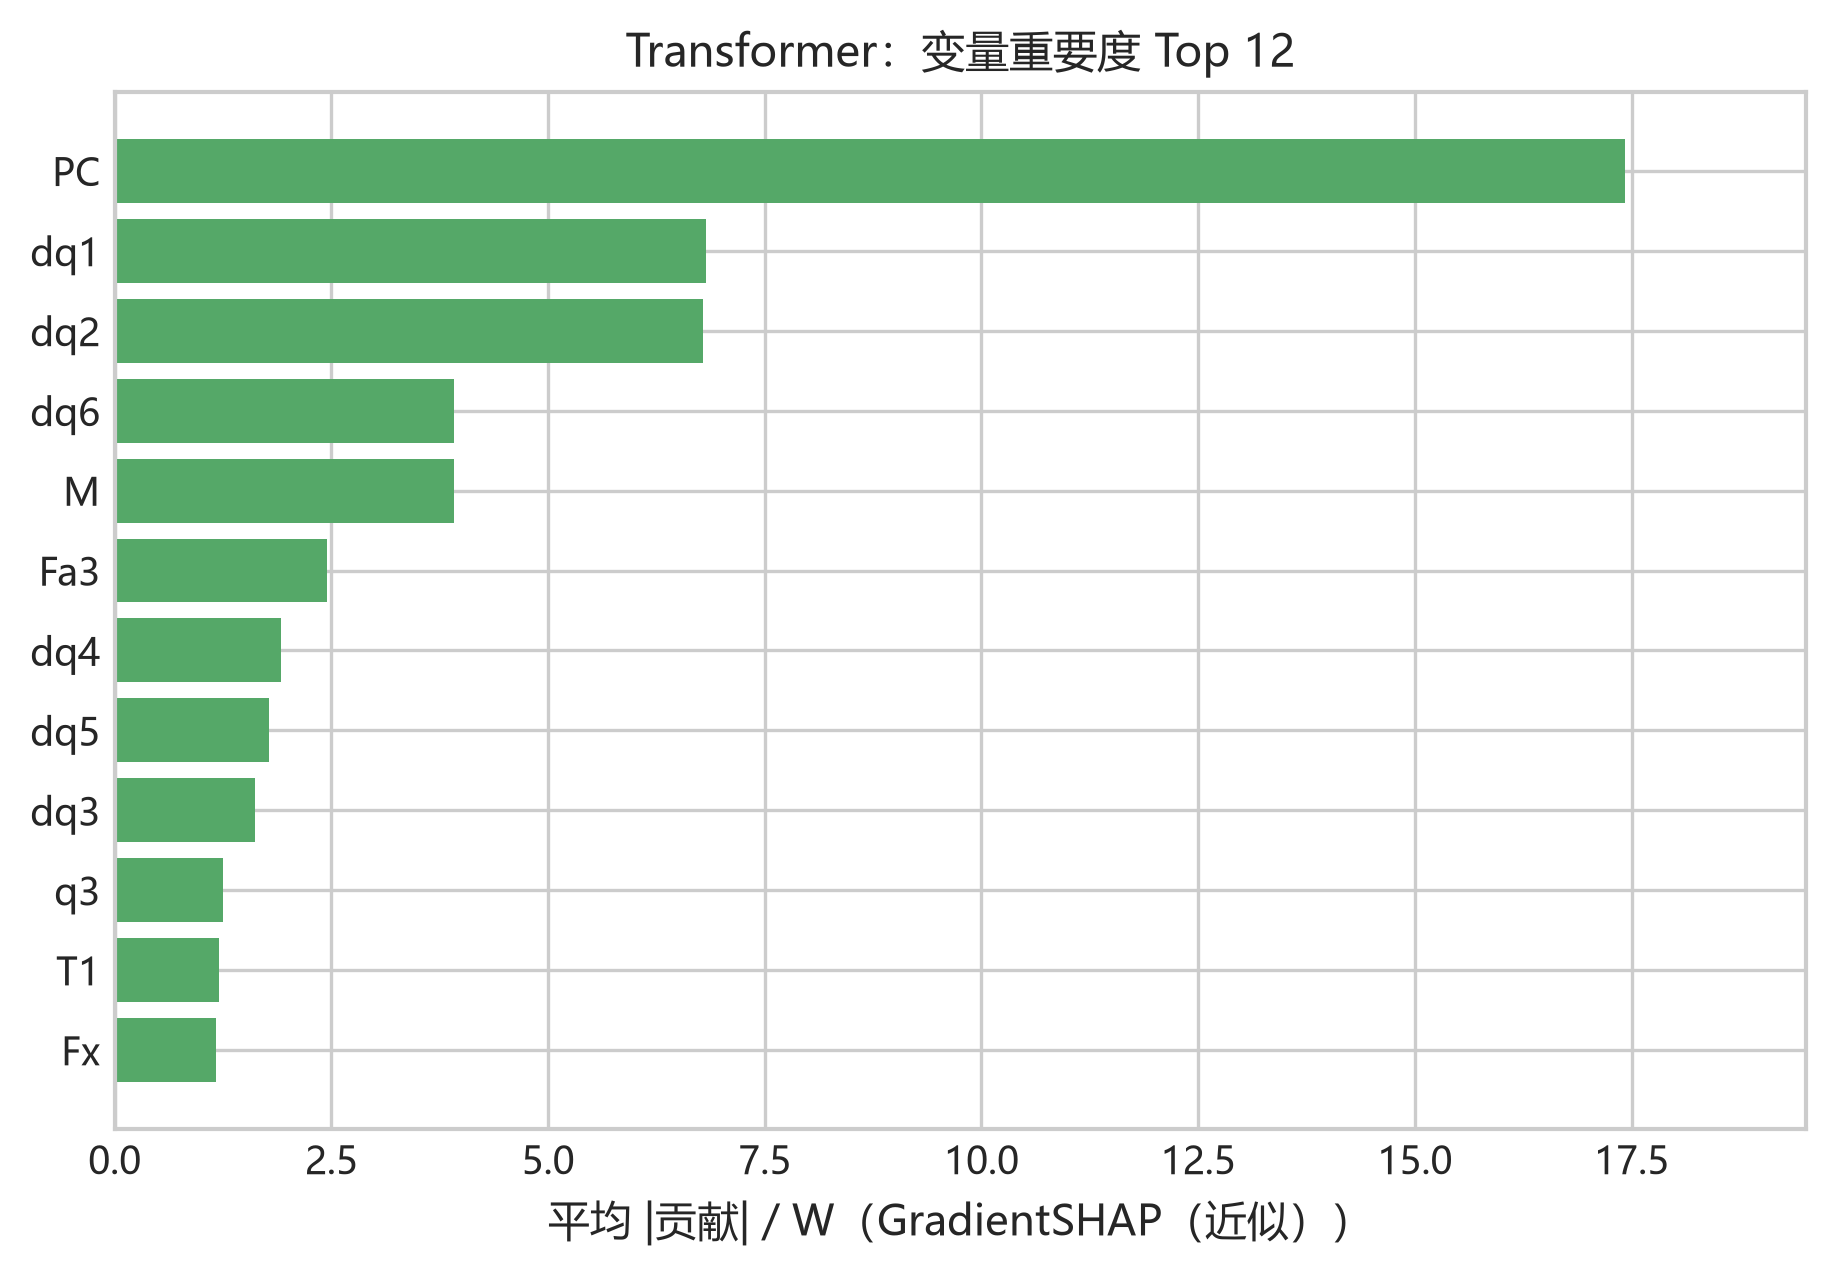

[saved] figures\train_test\09i_three_share.png  (300 dpi)


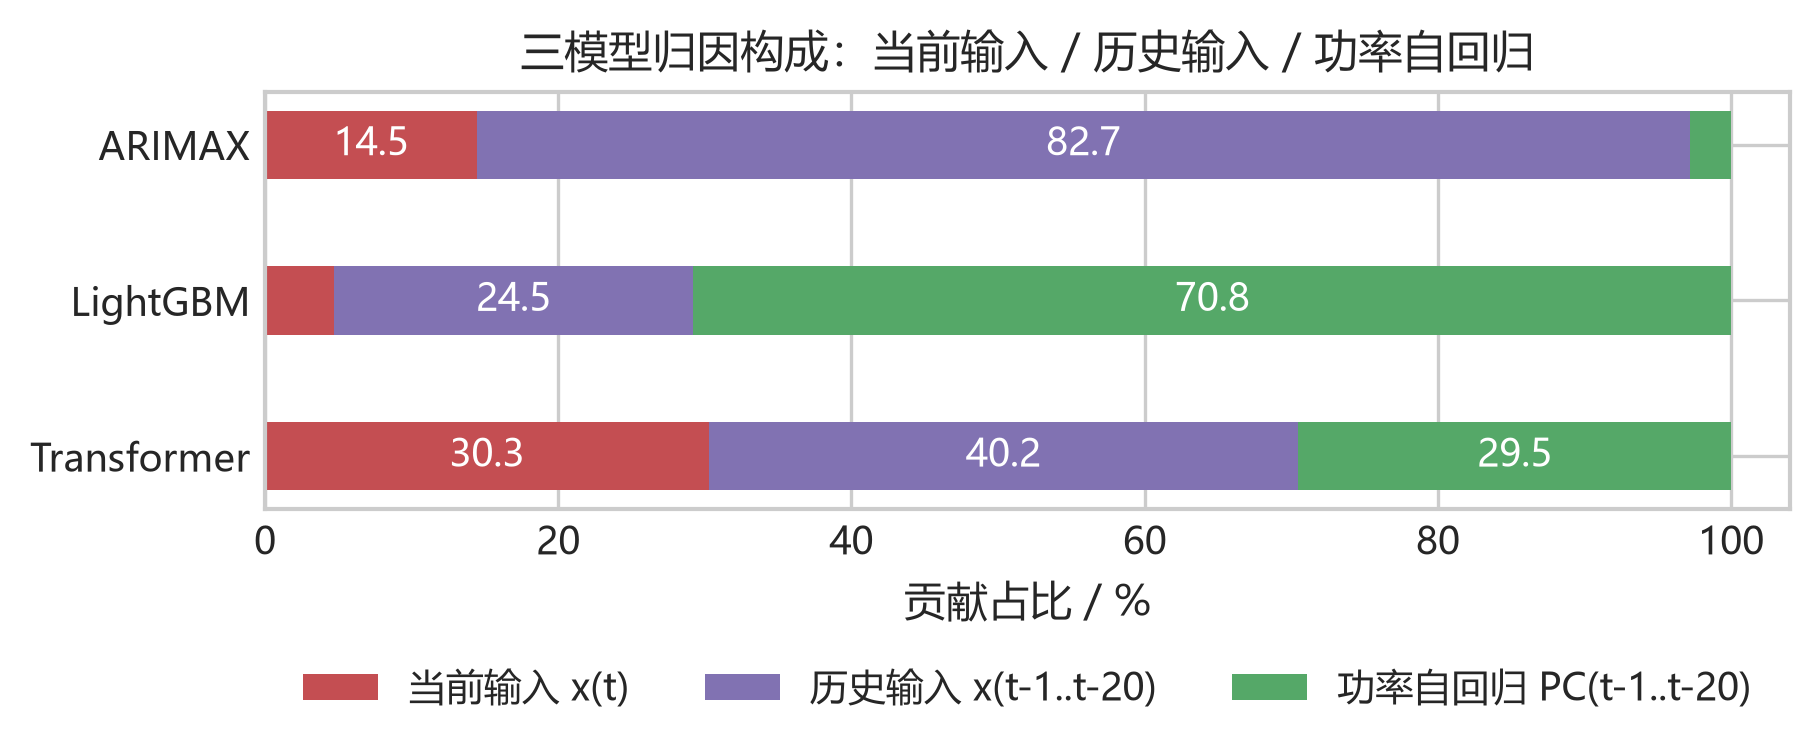

[saved] figures\train_test\09j_tf_lag_heatmap.png  (300 dpi)


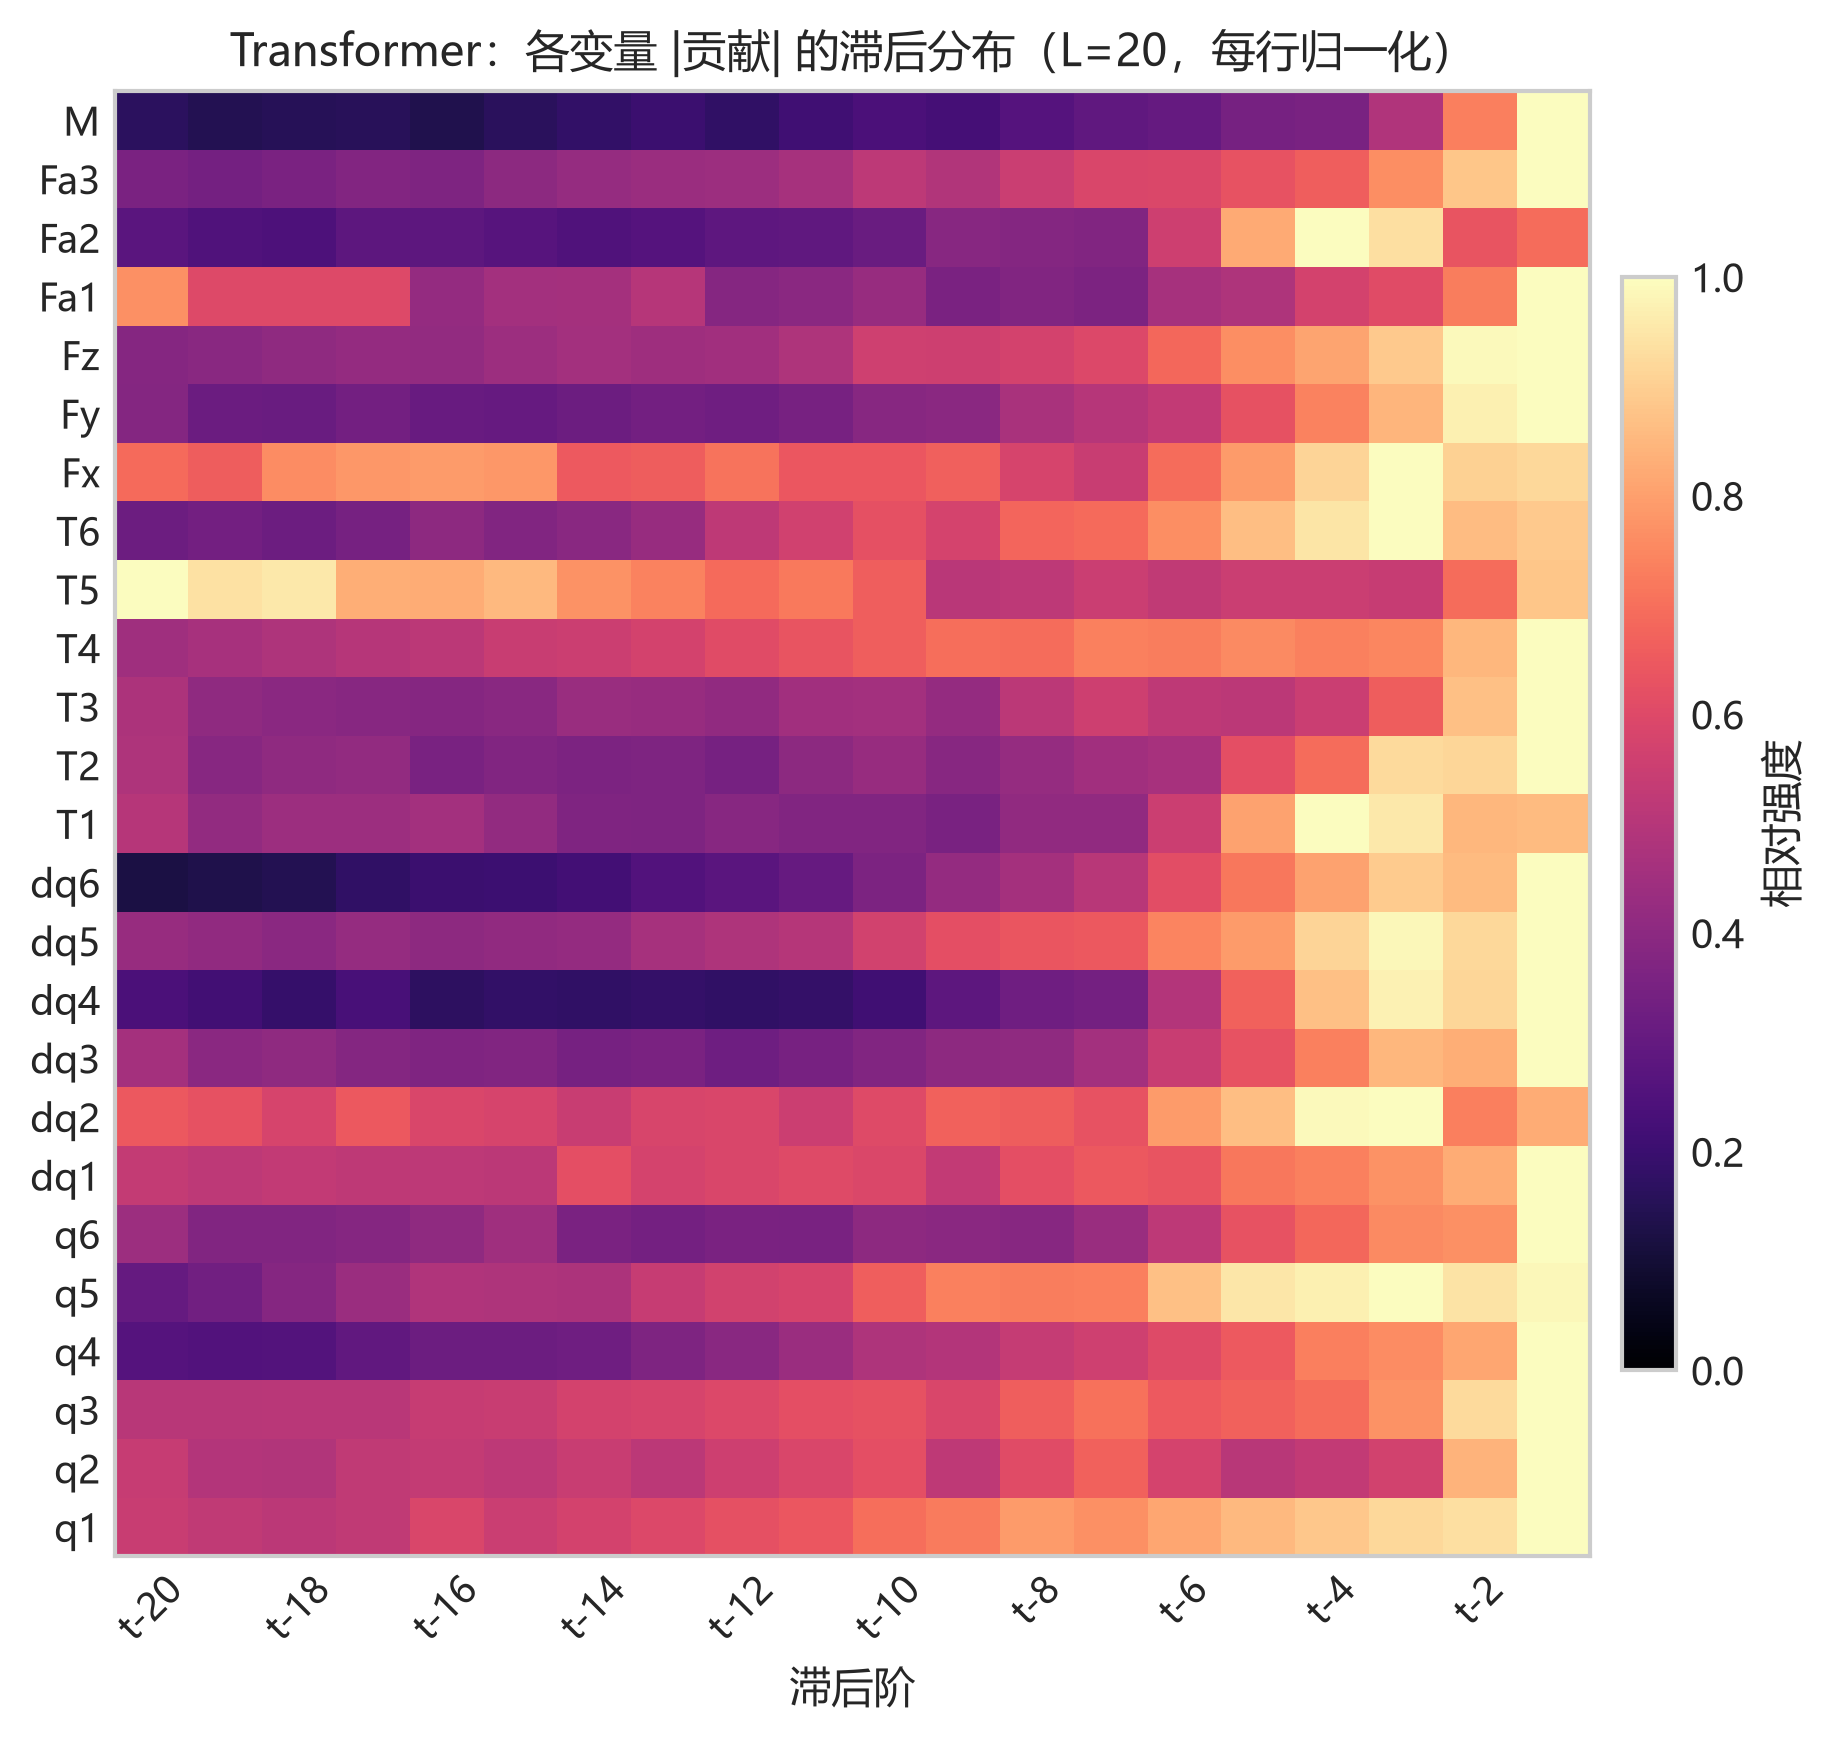

In [13]:
# ---------- 9.4.5 Transformer：GradientExplainer（近似 SHAP） ----------
class TFShapWrapper(nn.Module):
    """shap 需要输出为 (N, 1) 的二维张量，这里包一层。"""

    def __init__(self, model):
        super().__init__()
        self.model = model

    def forward(self, seq, cur):
        return self.model(seq, cur).unsqueeze(-1)


n_bg, n_ex = 100, 100
bg = [torch.from_numpy(S_te[:n_bg]).to(DEVICE), torch.from_numpy(C_te[:n_bg]).to(DEVICE)]
ex = [torch.from_numpy(S_te[n_bg:n_bg + n_ex]).to(DEVICE),
      torch.from_numpy(C_te[n_bg:n_bg + n_ex]).to(DEVICE)]

model_tf.eval()
np.random.seed(SEED)          # 固定 GradientSHAP 的背景采样，保证归因可复现
try:
    explainer_tf = shap.GradientExplainer(TFShapWrapper(model_tf).to(DEVICE), bg)
    sv = explainer_tf.shap_values(ex)
    sv_past = np.abs(np.asarray(sv[0]).squeeze(-1)).mean(0) * y_sd   # (L, 26)
    sv_cur = np.abs(np.asarray(sv[1]).squeeze(-1)).mean(0) * y_sd    # (25,)
    mode_tf = "GradientSHAP（近似）"
except Exception as err:
    print("GradientExplainer 失败，改用梯度×输入归因：", type(err).__name__, err)
    seq = ex[0].clone().requires_grad_(True)
    cur = ex[1].clone().requires_grad_(True)
    out = model_tf(seq, cur).sum()
    g_seq, g_cur = torch.autograd.grad(out, [seq, cur])
    sv_past = (seq * g_seq).abs().mean(0).detach().cpu().numpy() * y_sd
    sv_cur = (cur * g_cur).abs().mean(0).detach().cpu().numpy() * y_sd
    mode_tf = "梯度×输入（非 SHAP，仅供相对比较）"

vals = np.zeros(len(ALL_CHANNELS))
vals[: len(FEATURE_COLS)] = sv_cur + sv_past[:, : len(FEATURE_COLS)].sum(0)
vals[-1] = sv_past[:, -1].sum()
imp_tf = pd.Series(vals, index=ALL_CHANNELS)
print(f"Transformer 归因完成（{mode_tf}）| 解释样本 {n_ex} | 背景样本 {n_bg}")

tf_table = imp_tf.sort_values(ascending=False)
print("\nTransformer 平均 |贡献| / W（Top 12）")
display(tf_table.head(12).round(3))

# 三个模型的归因构成（当前输入 / 历史输入 / 功率自回归）
share_all = pd.DataFrame({
    "ARIMAX": split_share(imp_arx, FLAT_NAMES),
    "LightGBM": split_share(imp_lgb, FLAT_NAMES),
    "Transformer": pd.Series({
        LBL_CUR: sv_cur.sum(),
        LBL_HIS: sv_past[:, : len(FEATURE_COLS)].sum(),
        LBL_AR: sv_past[:, -1].sum(),
    }),
})
share_all = share_all / share_all.sum() * 100
print("三个模型的归因构成（%）")
display(share_all.round(2))

# ---------- 09h Transformer 变量重要度（单图，纵向拉长） ----------
tf_top = tf_table.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=fig_size(0.70))
ax.barh(range(len(tf_top)), tf_top.values, color="#55A868")
ax.set_yticks(range(len(tf_top)))
ax.set_yticklabels(tf_top.index, fontsize=FS_TICK)
ax.set_xlabel(f"平均 |贡献| / W（{mode_tf}）", fontsize=FS_LABEL)
ax.set_title("Transformer：变量重要度 Top 12", fontsize=FS_TITLE)
ax.tick_params(axis="x", labelsize=FS_TICK)
ax.set_xlim(0, tf_top.max() * 1.12)
fig.tight_layout()
savefig(fig, "09h_tf_importance")
plt.show()

# ---------- 09i 三模型归因构成（每个模型一条，按语义组堆叠） ----------
fig, ax = plt.subplots(figsize=fig_size(0.46))
_rows = list(share_all.columns)[::-1]
_left = np.zeros(len(_rows))
for k, seg in enumerate(share_all.index):
    vals_seg = share_all.loc[seg].reindex(_rows).values
    ax.barh(_rows, vals_seg, left=_left, height=0.44, color=["#C44E52", "#8172B2", "#55A868"][k],
            label=seg)
    for yi, (l, v) in enumerate(zip(_left, vals_seg)):
        if v > 8:
            ax.text(l + v / 2, yi, f"{v:.1f}", ha="center", va="center",
                    fontsize=FS_TICK, color="white")
    _left += vals_seg
ax.set_xlim(0, 104)
ax.set_xlabel("贡献占比 / %", fontsize=FS_LABEL)
ax.set_title("三模型归因构成：当前输入 / 历史输入 / 功率自回归", fontsize=FS_TITLE)
ax.tick_params(labelsize=FS_TICK)
ax.legend(fontsize=FS_LEGEND, ncol=3, loc="upper center",
          bbox_to_anchor=(0.5, -0.30), frameon=False)
fig.tight_layout()
savefig(fig, "09i_three_share")
plt.show()

# ---------- 09j 各变量 |贡献| 的滞后分布（25×20 热图，纵向拉长） ----------
heat = sv_past[:, : len(FEATURE_COLS)].T[::-1]       # (25, L)
heat_n = heat / (heat.max(axis=1, keepdims=True) + 1e-9)
fig, ax = plt.subplots(figsize=fig_size(0.95))
im = ax.imshow(heat_n, aspect="auto", cmap="magma", vmin=0, vmax=1); ax.grid(False)
ax.set_xticks(range(0, LAGS, 2))
ax.set_xticklabels([f"t-{LAGS - i}" for i in range(0, LAGS, 2)], rotation=45,
                   fontsize=FS_TICK)
ax.set_yticks(range(len(FEATURE_COLS)))
ax.set_yticklabels(FEATURE_COLS[::-1], fontsize=FS_TICK)
ax.set_xlabel("滞后阶", fontsize=FS_LABEL)
ax.set_title(f"Transformer：各变量 |贡献| 的滞后分布（L={LAGS}，每行归一化）",
             fontsize=FS_TITLE)
ax.tick_params(labelsize=FS_TICK)
cb = fig.colorbar(im, ax=ax, fraction=0.035, pad=0.02)
cb.set_label("相对强度", fontsize=FS_LABEL)
cb.ax.tick_params(labelsize=FS_TICK)
fig.tight_layout()
savefig(fig, "09j_tf_lag_heatmap")
plt.show()

## 10. 多步预测（递归策略，步长 $h=1$–$20$）

前 9 节的所有结果都是**单步预测**（用 $x_t$ 预测 $y_t$）。工程上更有价值的问题是：能否只凭当前状态，提前若干步预知末端功率，用于前瞻性能量调度与关节力矩规划？本章把预测步长扩展到 $h=1,\dots,20$（20–400 ms），采用**递归（recursive）策略**逐步外推。

### 10.1 问题定义

对基准时刻 $t$，递推地产生 20 个预测：

$$
\begin{aligned}
\hat y_t &= f\left(\{x_{t-L},\dots,x_{t-1}\},\ \{y_{t-L},\dots,y_{t-1}\},\ x_t\right)\\
\hat y_{t+1} &= f\left(\{x_{t-L+1},\dots,x_{t}\},\ \{y_{t-L+1},\dots,y_{t-1},\ \hat y_t\},\ x_{t+1}\right)\\
&\ \vdots\\
\hat y_{t+19} &= f\left(\dots,\ \{y_{t-L+19},\dots,\hat y_{t+18}\},\ x_{t+19}\right)
\end{aligned}
$$

即：**只有一个模型 $f$（$h=1$ 的单步模型），每次把上一步的预测值填回历史输出通道，外生输入使用真实的 $x_{t+k}$，滚动 $h-1$ 次**。

两点说明：

1. 未来外生输入 $x_{t+1},\dots,x_{t+19}$ 在实际部署中是可获得的——关节位置/速度/力矩由编码器实时测得，或由轨迹规划器预先给出。因此本章用测试集的真实值提供，把"回填误差累积"与"外生输入未知"这两种不确定性分离开，单独考察前者。
2. 模型完全复用第 4–6 节训练好的三个单步模型，**本章不产生任何额外的训练开销**，这正是递归策略最大的工程优势：模型数与步长无关。

### 10.2 评估样本的构造

为保证 $h=1,\dots,20$ 的结果可直接比较，所有步长**共用同一批基准时刻**：基准时刻 $t$ 需满足 $t+19\le n-1$（这样 20 个标签都存在）。于是跨步长的误差变化只由步长本身引起，与样本集变化无关。每个样本提供：历史窗口（20 步 × 26 通道）、未来 20 个外生输入、以及 20 个待预测标签。

> 本章沿用第 3 节的轨迹划分与标准化统计量，因此 $h=1$ 的结果与第 11.2 节的单步结论完全对应（同一模型、同一批轨迹）。

In [14]:
# ---------- 10.2 多步评估样本构造 ----------
H_MAX = 20         # 预测步长上限：h = 1..20（20~400 ms）


def build_multi_step(df, h_max=H_MAX, lags=LAGS):
    """构造多步评估样本：所有步长共用同一批基准时刻。

    对每个基准时刻 k，历史窗口是「最近 lags 步的 (x, y)」，
    另外返回未来 h_max 个外生输入 x[k:k+h_max] 和 h_max 个标签 y[k:k+h_max]。
    """
    seqs, xwins, ys, tids, poss = [], [], [], [], []
    for tid, g in df.groupby(GROUP, sort=True):
        g = g.sort_values("t1", kind="mergesort")
        X = g[FEATURE_COLS].to_numpy(np.float32)
        y = g[TARGET].to_numpy(np.float32)
        n = len(g)
        if n - lags - h_max + 1 <= 0:
            continue
        XY = np.concatenate([X, y[:, None]], axis=1)          # (n, 26)
        for k in range(lags, n - h_max + 1):
            seqs.append(XY[k - lags:k])                        # 历史 (L, 26)
            xwins.append(X[k:k + h_max])                       # 当前及未来外生输入
            ys.append(y[k:k + h_max])                          # 待预测标签
            tids.append(tid)
            poss.append(k)
    return (np.stack(seqs).astype(np.float32), np.stack(xwins).astype(np.float32),
            np.stack(ys).astype(np.float32), np.asarray(tids), np.asarray(poss))


mSeq_te, mX_te, mY_te, mtid_te, mpos_te = build_multi_step(test_df)

# 复用第 3 节的标准化统计量；模型直接沿用第 4–6 节，无需重新训练
mS_te = scale_seq(mSeq_te)
mXw_te = scale_cur(mX_te)

print(f"测试集多步样本 {len(mS_te):,} 个"
      f"（{np.unique(mtid_te).size} 条轨迹，每条 {len(mS_te) // np.unique(mtid_te).size} 个基准时刻）")
print(f"历史窗口 {mS_te.shape} | 未来外生输入 {mXw_te.shape} | 标签矩阵 {mY_te.shape}")
print(f"对照：单步样本 {len(S_te):,} 个，多步样本因要求 {H_MAX} 个未来标签而少 {len(S_te) - len(mS_te)} 个")
print("\n各步长标签的均值 / 标准差（W，节选 h=1,5,10,15,20）：")
show_h = [1, 5, 10, 15, 20]
display(pd.DataFrame({f"h={h}": [mY_te[:, h - 1].mean(), mY_te[:, h - 1].std()]
                      for h in show_h}, index=["均值", "标准差"]).round(3))

测试集多步样本 5,532 个（12 条轨迹，每条 461 个基准时刻）
历史窗口 (5532, 20, 26) | 未来外生输入 (5532, 20, 25) | 标签矩阵 (5532, 20)
对照：单步样本 5,760 个，多步样本因要求 20 个未来标签而少 228 个

各步长标签的均值 / 标准差（W，节选 h=1,5,10,15,20）：


,h=1,h=5,h=10,h=15,h=20
均值,45.933998,45.938,45.938,45.918999,45.889999
标准差,10.461000,10.469,10.468,10.459000,10.446000


### 10.3 递归滚动实现

三个模型共用同一套滚动逻辑（`rollout`），只是"如何用模型算一步"不同：

| 模型 | 单步前向 | 说明 |
|---|---|---|
| ARIMAX | $x_\text{flat}^\top w + b$ | 历史展平为 545 维后做一次矩阵乘法 |
| LightGBM | `Booster.predict` | 同样的 545 维输入 |
| Transformer | `(seq, cur) → ŷ` | 直接接受序列形式，回填时把新时刻 token 追加到窗口尾部 |

滚动时注意两点：① 回填的是**标准化后**的预测值（与训练时的目标尺度一致）；② 窗口每步右移一格（`S[:, 1:]` 追加新 token），保持固定的 20 步视野。

为量化"误差累积"，同时计算一个 **oracle 对照**：滚动流程完全相同，但回填的是**真实标签** $y_{t+k}$ 而非预测值。此时每一步实质上都是标准单步预测，因此 oracle 曲线衡量的是"若历史功率完全准确，模型本可以达到的精度"。二者的差距即完全由回填误差引起。

In [15]:
# ---------- 10.3 递归滚动：直接复用第 4–6 节的单步模型 ----------
def arx_fn(w, b):
    def f(S, cur):
        F = np.concatenate([S.reshape(len(S), -1), cur], axis=1).astype(np.float64)
        return inv_y(F @ w + b)
    return f


def lgb_fn(m):
    def f(S, cur):
        F = np.concatenate([S.reshape(len(S), -1), cur], axis=1).astype(np.float32)
        return m.predict(F, num_iteration=m.best_iteration)
    return f


def tf_fn(m):
    def f(S, cur):
        return predict_transformer(m, S.astype(np.float32), cur.astype(np.float32))
    return f


def rollout(predict_fn, S0, Xw, Ytrue=None, h_max=H_MAX):
    """滚动预测 h=1..h_max。

    Ytrue=None  → 递归：回填模型自己的预测值（真实部署情形）
    Ytrue=mY    → oracle：回填真实标签（分离"回填误差"与"信息不足"）
    外生输入一律使用真实的 x_{t+k}。
    """
    S = S0.astype(np.float32).copy()
    outs = []
    for h in range(h_max):
        cur = Xw[:, h]
        p = predict_fn(S, cur).astype(np.float64)
        outs.append(p)
        if h < h_max - 1:
            fill = p if Ytrue is None else Ytrue[:, h]
            tok = np.concatenate([cur, scale_y(fill).astype(np.float32)[:, None]], axis=1)
            S = np.concatenate([S[:, 1:], tok[:, None, :]], axis=1).astype(np.float32)
    return np.stack(outs, axis=1)


MS_FN = {"ARIMAX": arx_fn(w_arx, b_arx),
         "LightGBM": lgb_fn(model_lgb),
         "Transformer": tf_fn(model_tf)}
MS_MODELS = list(MS_FN)

t0 = time.perf_counter()
RECUR = {n: rollout(f, mS_te, mXw_te) for n, f in MS_FN.items()}
ORACLE = {n: rollout(f, mS_te, mXw_te, Ytrue=mY_te) for n, f in MS_FN.items()}
print(f"滚动完成：3 个模型 × {H_MAX} 步 × 2 种回流方式，耗时 {time.perf_counter() - t0:.2f} s")
print("预测矩阵形状：", {n: v.shape for n, v in RECUR.items()})
print("注：h=1 时两种方式完全等价（尚未发生回填）")

滚动完成：3 个模型 × 20 步 × 2 种回流方式，耗时 4.45 s
预测矩阵形状： {'ARIMAX': (5532, 20), 'LightGBM': (5532, 20), 'Transformer': (5532, 20)}
注：h=1 时两种方式完全等价（尚未发生回填）


### 10.4 多步精度

三个模型在 $h=1,\dots,20$ 上的测试集精度，以及相对 $h=1$ 的误差增长倍数。由于模型与样本都相同，$h=1$ 一行即第 11.2 节的单步结果（仅样本少了每条轨迹末尾 19 个点）。

> 观察重点：**最优模型会随步长切换**（$h\le10$ LightGBM → $h=11$–$15$ Transformer → $h\ge16$ ARIMAX），原因是各模型对历史功率的依赖程度不同，回填误差被放大的速度也不同。

递归多步 RMSE / W（h=1–5）


模型,ARIMAX,LightGBM,Transformer
步长 h,,,
1,3.088,2.998,4.030
2,3.623,3.570,4.396
3,4.194,4.083,4.770
4,4.728,4.591,5.129
5,5.239,5.077,5.473


递归多步 R²（h=1–5）


模型,ARIMAX,LightGBM,Transformer
步长 h,,,
1,0.9129,0.9179,0.8516
2,0.8802,0.8836,0.8236
3,0.8395,0.8478,0.7923
4,0.7961,0.8077,0.7600
5,0.7496,0.7648,0.7266


递归多步 RMSE / W（h=6–10）


模型,ARIMAX,LightGBM,Transformer
步长 h,,,
6,5.725,5.547,5.809
7,6.172,5.938,6.133
8,6.572,6.319,6.437
9,6.911,6.656,6.719
10,7.204,6.973,6.987


... (9 outputs left out)

模型,ARIMAX,LightGBM,Transformer
步长 h,,,
16,0.3862,0.3647,0.3827
17,0.3709,0.3365,0.3596
18,0.3582,0.3092,0.3381
19,0.3460,0.2817,0.3170
20,0.3335,0.2573,0.2976


相对 h=1 的 RMSE 增长倍数


,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
ARIMAX,1.0,1.173,1.358,1.531,1.696,1.854,1.999,2.128,2.238,2.333,2.413,2.478,2.533,2.580,2.619,2.652,2.685,2.711,2.736,2.762
LightGBM,1.0,1.191,1.362,1.531,1.693,1.850,1.981,2.108,2.220,2.326,2.423,2.501,2.577,2.649,2.719,2.779,2.840,2.897,2.954,3.003
Transformer,1.0,1.091,1.184,1.273,1.358,1.441,1.522,1.597,1.667,1.734,1.796,1.853,1.906,1.955,1.999,2.038,2.076,2.110,2.143,2.173


[saved] figures\train_test\10a_rmse_growth.png  (300 dpi)


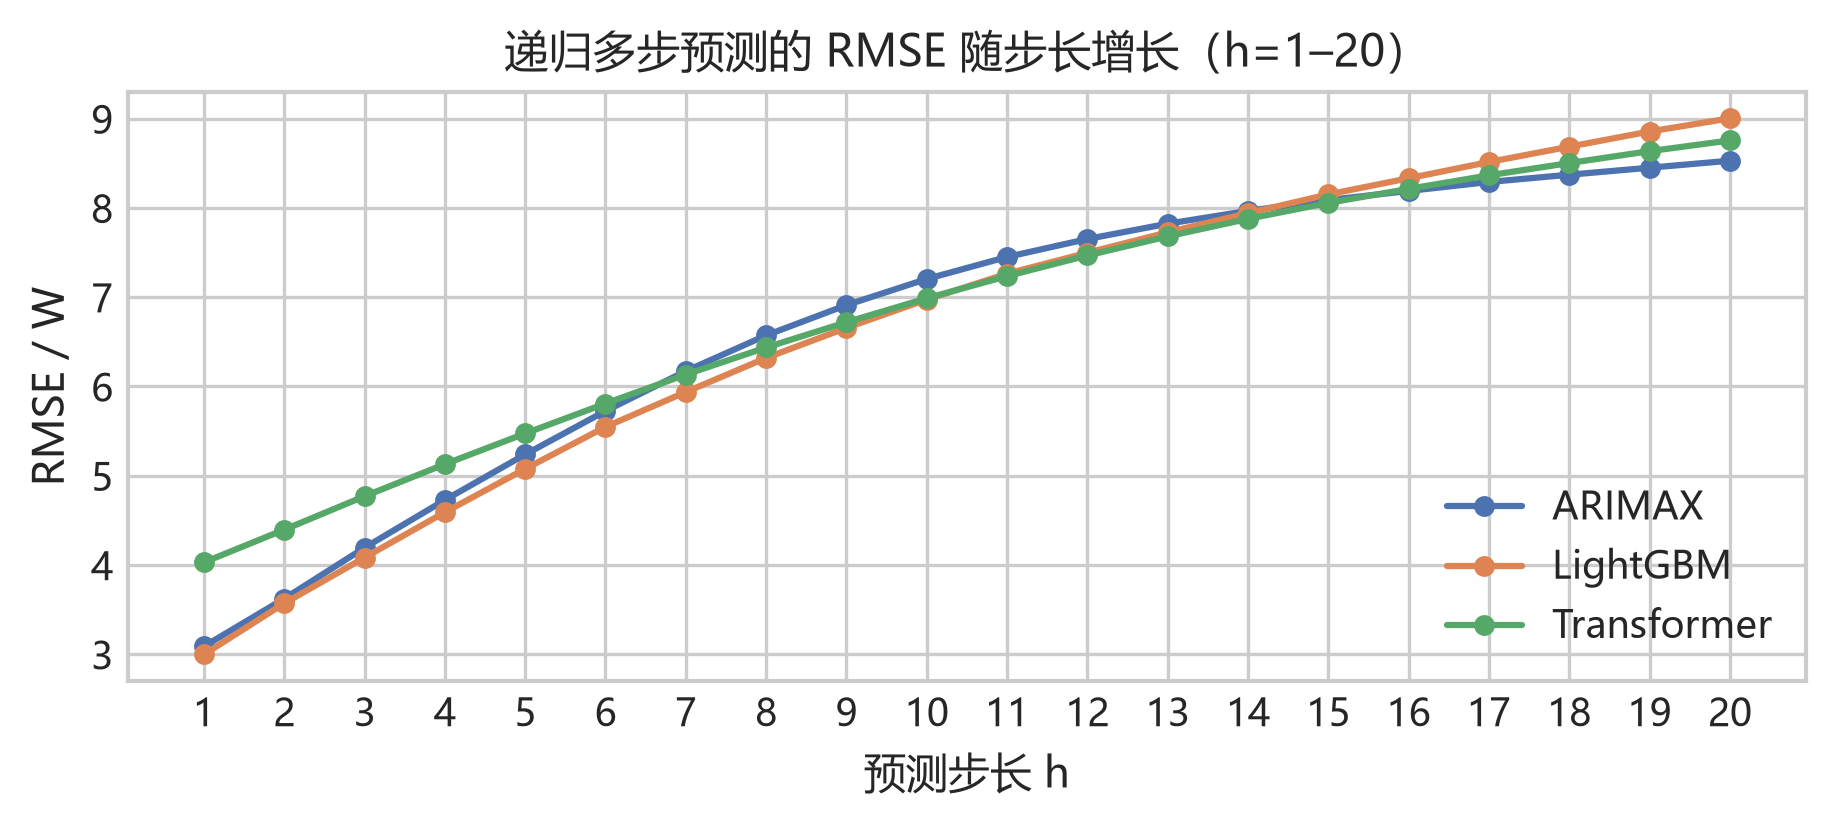

[saved] figures\train_test\10b_recursive_vs_oracle.png  (300 dpi)


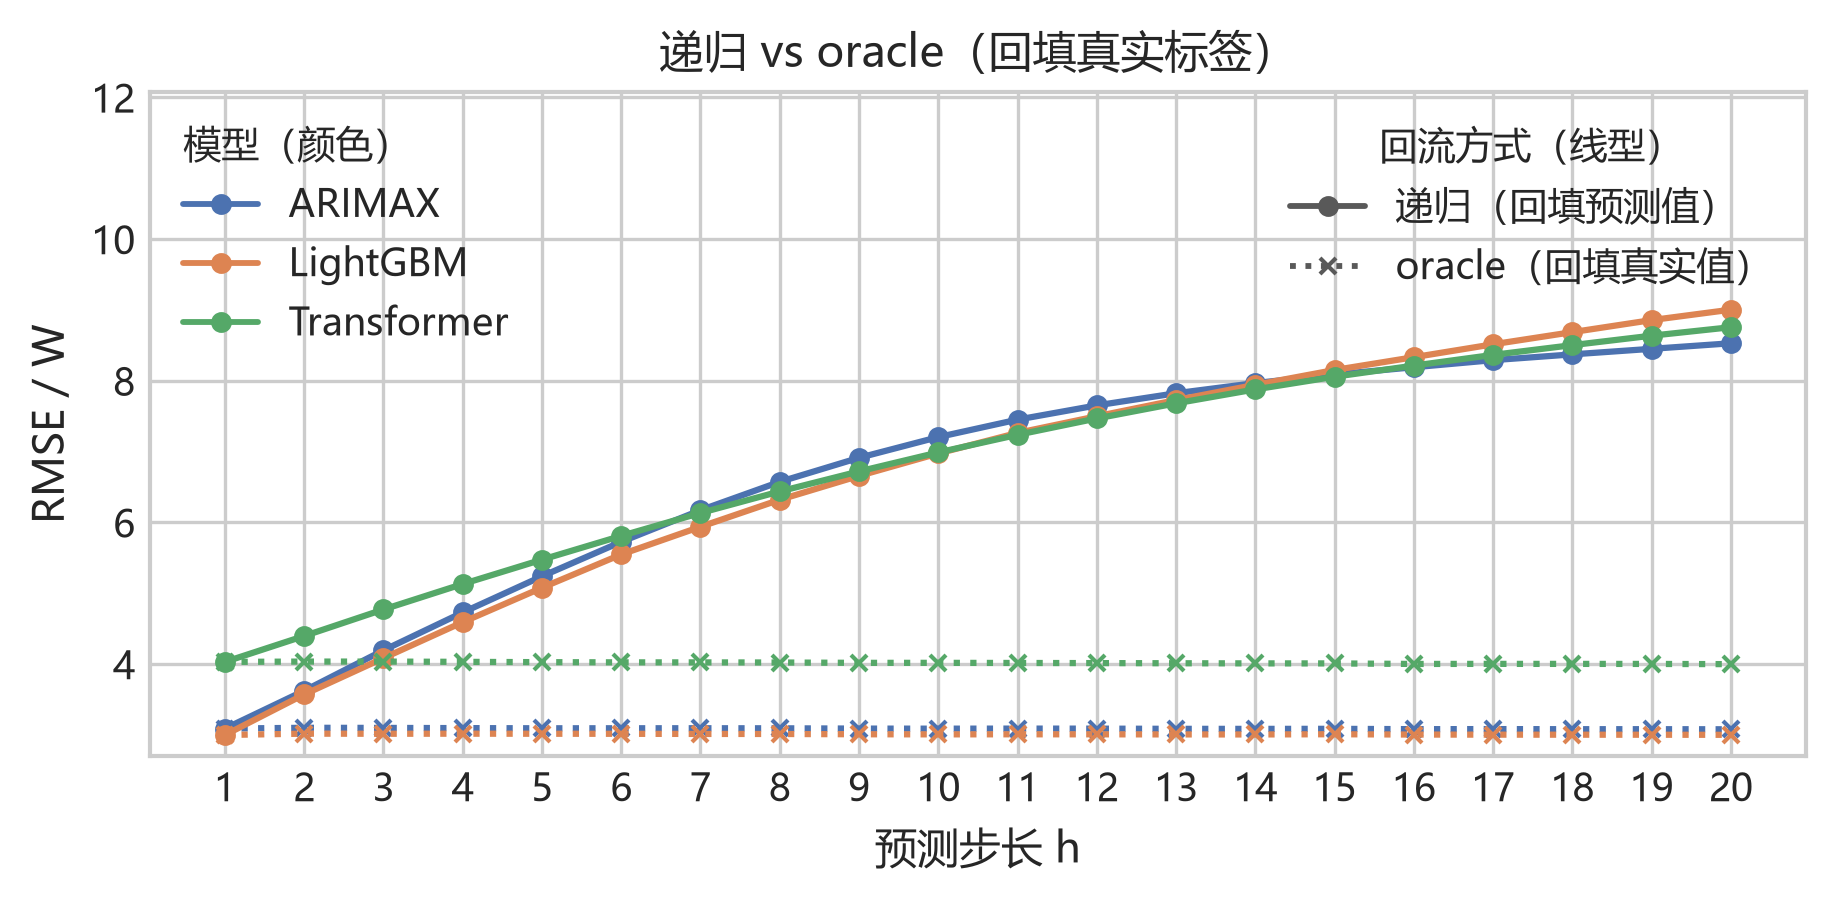

[saved] figures\train_test\10c_h20_gap.png  (300 dpi)


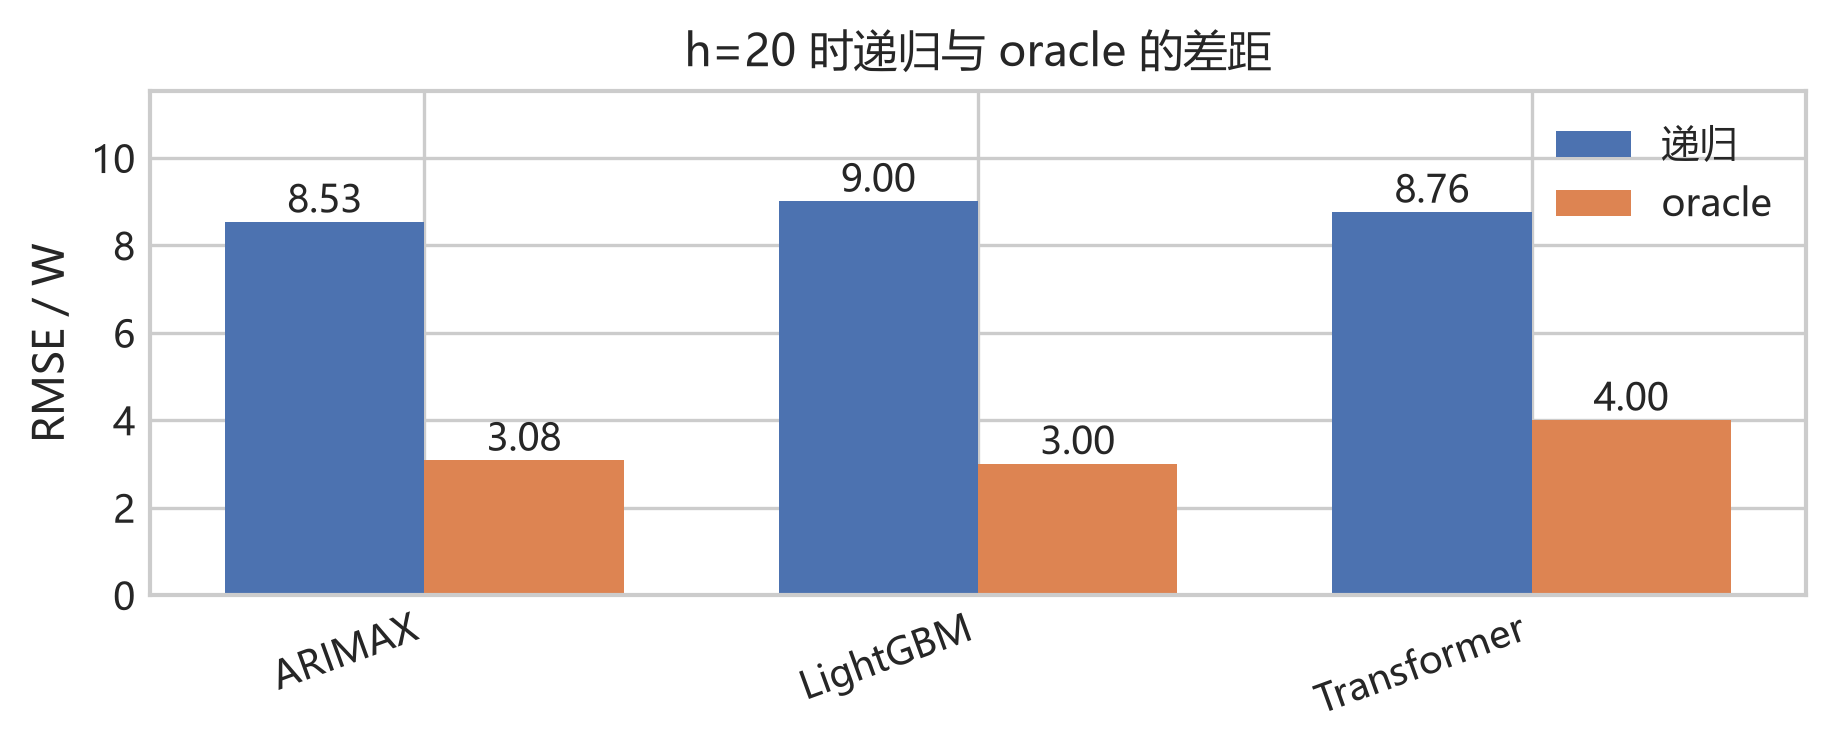

In [16]:
# ---------- 10.4 多步精度 ----------
from matplotlib.lines import Line2D

rows = []
for name in MS_MODELS:
    for h in range(1, H_MAX + 1):
        for mode, store in (("递归", RECUR), ("oracle", ORACLE)):
            rows.append({"模型": name, "回流": mode, "步长 h": h,
                         **regression_metrics(mY_te[:, h - 1], store[name][:, h - 1])})
ms_table = pd.DataFrame(rows)


def gv(name, mode, h, col="RMSE / W"):
    r = ms_table[(ms_table["模型"] == name) & (ms_table["回流"] == mode) & (ms_table["步长 h"] == h)]
    return float(r[col].iloc[0])


rec = ms_table[ms_table["回流"] == "递归"]
# 表格较长，按 5 步一组展示
for lo in range(1, H_MAX + 1, 5):
    hi = min(lo + 4, H_MAX)
    print(f"递归多步 RMSE / W（h={lo}–{hi}）")
    display(rec.pivot_table(index="步长 h", columns="模型", values="RMSE / W").loc[lo:hi].round(3))
    print(f"递归多步 R²（h={lo}–{hi}）")
    display(rec.pivot_table(index="步长 h", columns="模型", values="R²").loc[lo:hi].round(4))

print("相对 h=1 的 RMSE 增长倍数")
display(pd.DataFrame({n: [gv(n, "递归", h) / gv(n, "递归", 1) for h in range(1, H_MAX + 1)]
                      for n in MS_MODELS}, index=range(1, H_MAX + 1)).round(3).T)

hs = list(range(1, H_MAX + 1))

# ---------- 10a RMSE 随步长增长（单图） ----------
fig, ax = plt.subplots(figsize=fig_size(0.46))
for name in MS_MODELS:
    ax.plot(hs, [gv(name, "递归", h) for h in hs], "o-", ms=4, color=COLORS[name], label=name)
ax.set_xlabel("预测步长 h", fontsize=FS_LABEL)
ax.set_ylabel("RMSE / W", fontsize=FS_LABEL)
ax.set_title(f"递归多步预测的 RMSE 随步长增长（h=1–{H_MAX}）", fontsize=FS_TITLE)
ax.set_xticks(hs)
ax.tick_params(labelsize=FS_TICK)
ax.legend(fontsize=FS_LEGEND, loc="lower right")
fig.tight_layout()
savefig(fig, "10a_rmse_growth")
plt.show()

# ---------- 10b 递归 vs oracle（单图，图例含"模型颜色 + 回流线型"两部分） ----------
fig, ax = plt.subplots(figsize=fig_size(0.50))
for name in MS_MODELS:
    ax.plot(hs, [gv(name, "递归", h) for h in hs], "o-", ms=4, color=COLORS[name])
    ax.plot(hs, [gv(name, "oracle", h) for h in hs], ":", color=COLORS[name], marker="x", ms=4)
ax.set_xlabel("预测步长 h", fontsize=FS_LABEL)
ax.set_ylabel("RMSE / W", fontsize=FS_LABEL)
ax.set_title("递归 vs oracle（回填真实标签）", fontsize=FS_TITLE)
ax.set_xticks(hs)
ax.tick_params(labelsize=FS_TICK)

_hb = ([Line2D([], [], color=COLORS[n], ls="-", marker="o", ms=4, lw=1.4, label=n)
        for n in MS_MODELS]
       + [Line2D([], [], color="0.35", ls="-", marker="o", ms=4, lw=1.4, label="递归（回填预测值）"),
          Line2D([], [], color="0.35", ls=":", marker="x", ms=4, lw=1.4, label="oracle（回填真实值）")])
_leg = ax.legend(handles=_hb[:3], fontsize=FS_LEGEND, ncol=1, loc="upper left",
                 framealpha=0.9, title="模型（颜色）", title_fontsize=FS_LEGEND)
_leg._legend_box.align = "left"
ax.add_artist(_leg)
ax.legend(handles=_hb[3:], fontsize=FS_LEGEND, ncol=1, loc="upper right",
          framealpha=0.9, title="回流方式（线型）", title_fontsize=FS_LEGEND)
_lo, _hi = ax.get_ylim()
ax.set_ylim(_lo, _hi + 0.42 * (_hi - _lo))      # 顶部留白：容纳两个并列图例
fig.tight_layout()
savefig(fig, "10b_recursive_vs_oracle")
plt.show()

# ---------- 10c h=H_MAX 时递归与 oracle 的差距（单图） ----------
fig, ax = plt.subplots(figsize=fig_size(0.42))
x = np.arange(len(MS_MODELS))
w = 0.36
dN = [gv(n, "递归", H_MAX) for n in MS_MODELS]
oN = [gv(n, "oracle", H_MAX) for n in MS_MODELS]
ax.bar(x - w / 2, dN, w, label="递归", color="#4C72B0")
ax.bar(x + w / 2, oN, w, label="oracle", color="#DD8452")
ax.set_xticks(x)
ax.set_xticklabels(MS_MODELS, fontsize=FS_TICK, rotation=20, ha="right")
ax.set_ylabel("RMSE / W", fontsize=FS_LABEL)
ax.set_ylim(0, max(max(dN), max(oN)) * 1.28)
ax.set_title(f"h={H_MAX} 时递归与 oracle 的差距", fontsize=FS_TITLE)
ax.tick_params(labelsize=FS_TICK)
for i in range(len(MS_MODELS)):
    ax.text(i - w / 2, dN[i], f"{dN[i]:.2f}", ha="center", va="bottom", fontsize=FS_TICK)
    ax.text(i + w / 2, oN[i], f"{oN[i]:.2f}", ha="center", va="bottom", fontsize=FS_TICK)
ax.legend(fontsize=FS_LEGEND, loc="upper right", framealpha=0.9)
fig.tight_layout()
savefig(fig, "10c_h20_gap")
plt.show()

### 10.5 误差累积的定量分解

递归多步的误差可以拆成两部分：

$$
\mathrm{MSE}_\text{rec}(h) \;=\; \mathrm{MSE}_\text{oracle}(h) \;+\; \Delta(h)
$$

其中 $\mathrm{MSE}_\text{rec}(h)$ 是实际的递归误差，$\mathrm{MSE}_\text{oracle}(h)$ 是"历史功率用真值"时的误差，$\Delta(h)$ 即回填误差累积带来的额外部分。

- $\mathrm{MSE}_\text{oracle}(h)$：仅凭外生输入 + 真实历史能达到的精度，即模型在该任务上的**可达上限**；
- $\Delta(h)$：前 $h-1$ 步的预测值被写入历史通道后引入的额外误差。

定义「累积贡献占比」$=1-\mathrm{MSE}_\text{oracle}/\mathrm{MSE}_\text{rec}$，衡量第 $h$ 步的误差有多大比例可归因于回填；同时给出逐步放大系数 $\mathrm{RMSE}(h)/\mathrm{RMSE}(h-1)$，用于判断误差是否会在滚动中发散。

误差分解（累积贡献 = 1 - MSE_oracle / MSE_递归），节选 h=1,5,10,15,20


模型,ARIMAX,LightGBM,Transformer
步长 h,,,
1,0.0,0.0,0.0
5,65.2,64.7,45.9
10,81.6,81.4,67.0
15,85.5,86.4,75.2
20,87.0,88.9,79.1


逐步放大系数 RMSE(h) / RMSE(h-1)


步长 h,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
模型,,,,,,,,,,,,,,,,,,,
ARIMAX,1.173,1.158,1.127,1.108,1.093,1.078,1.065,1.052,1.042,1.034,1.027,1.022,1.018,1.015,1.013,1.012,1.010,1.009,1.009
LightGBM,1.191,1.144,1.124,1.106,1.093,1.070,1.064,1.053,1.048,1.042,1.032,1.031,1.028,1.026,1.022,1.022,1.020,1.020,1.017
Transformer,1.091,1.085,1.075,1.067,1.061,1.056,1.050,1.044,1.040,1.036,1.032,1.029,1.026,1.023,1.019,1.018,1.016,1.016,1.014


oracle RMSE / W（历史功率为真值时的可达精度）


步长 h,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
模型,,,,,,,,,,,,,,,,,,,,
ARIMAX,3.088,3.099,3.098,3.095,3.092,3.093,3.093,3.092,3.088,3.087,3.088,3.087,3.085,3.084,3.085,3.080,3.081,3.079,3.080,3.078
LightGBM,2.998,3.017,3.015,3.016,3.015,3.015,3.013,3.012,3.008,3.007,3.008,3.007,3.006,3.005,3.008,3.004,3.003,3.002,3.002,3.000
Transformer,4.030,4.034,4.034,4.030,4.026,4.023,4.023,4.021,4.016,4.016,4.015,4.013,4.011,4.009,4.008,4.001,4.002,4.002,4.001,3.998


ARIMAX 的自回归系数（标准化尺度）：
  Σφ = 0.928 | Σ|φ| = 1.014 | 最大 |φ| = 0.423
  滞后 1–5 阶系数：[ 0.006  0.029  0.003 -0.001  0.009]
参考：Σ|φ| 越接近 1，模型越倾向于把历史功率线性外推（近单位根），污染会被持续放大
[saved] figures\train_test\10d_mse_decomp.png  (300 dpi)


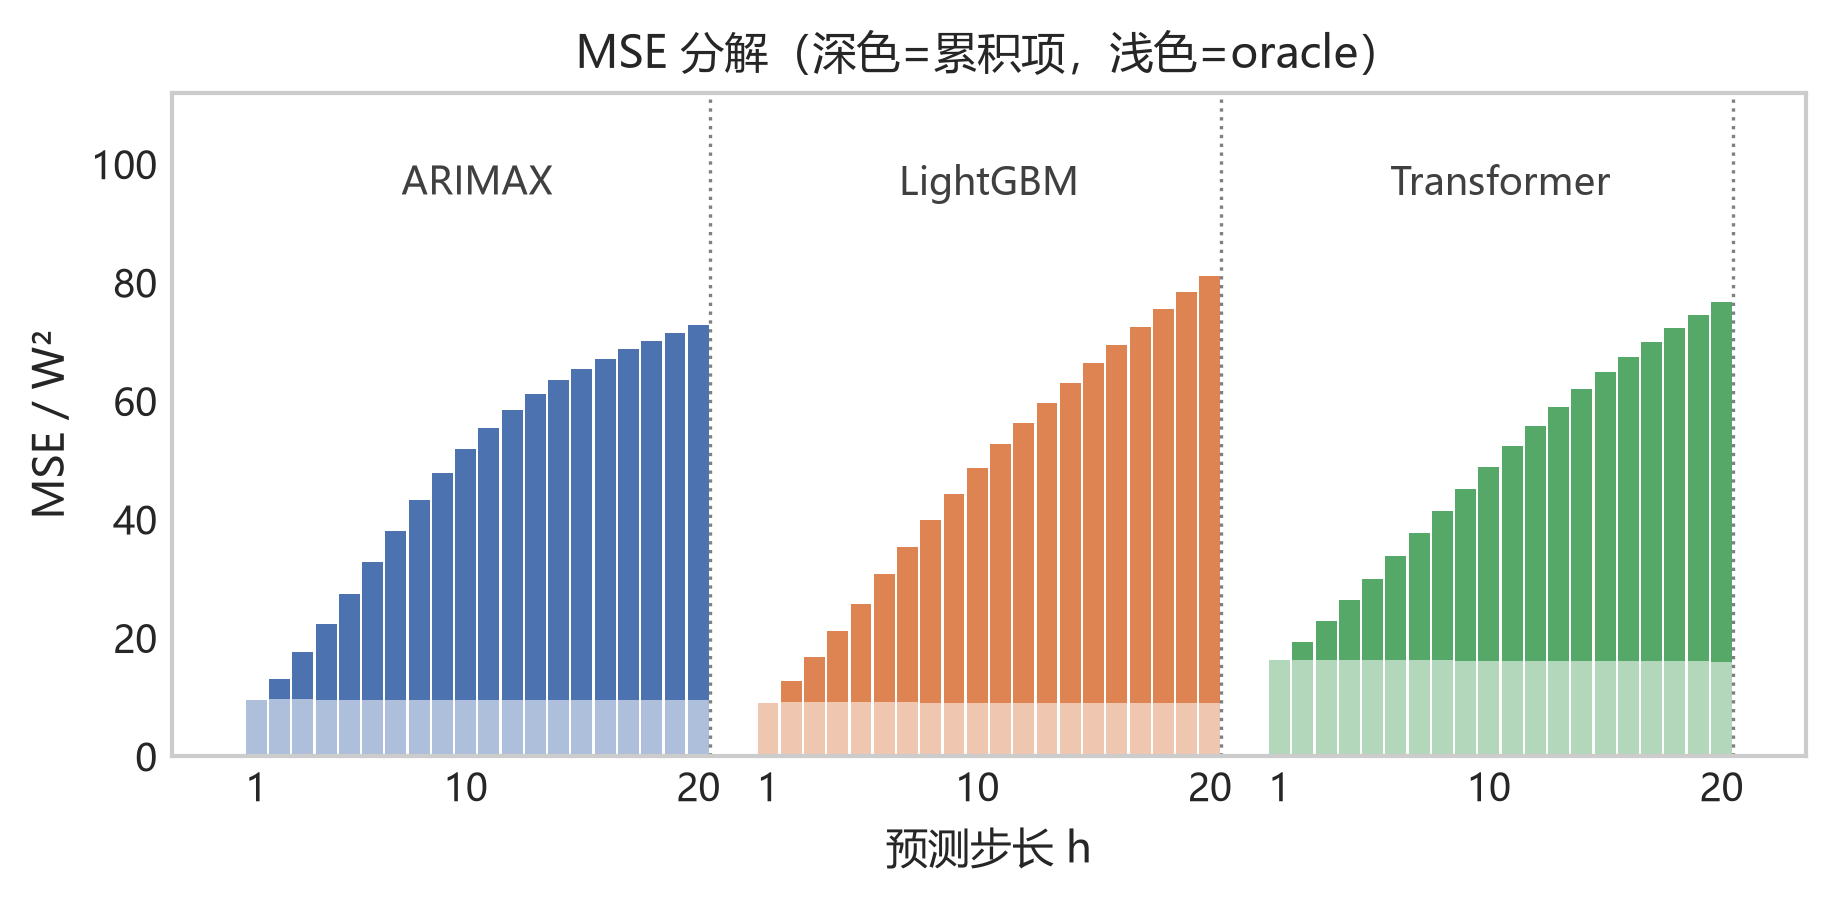

[saved] figures\train_test\10e_backfill_share.png  (300 dpi)


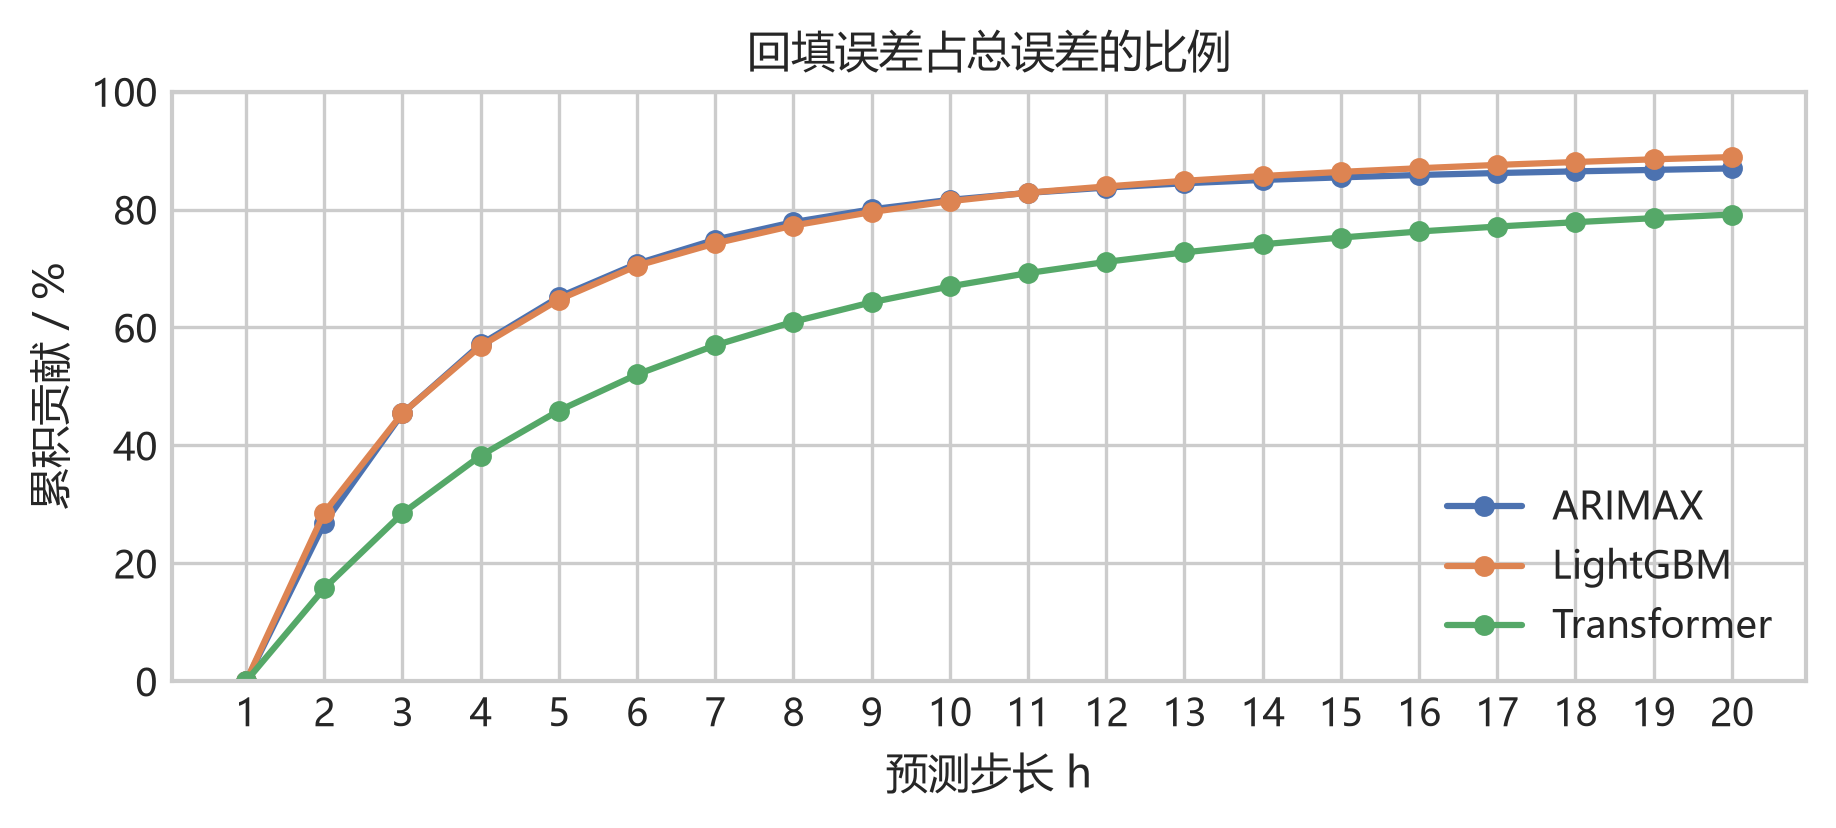

[saved] figures\train_test\10f_amplify.png  (300 dpi)


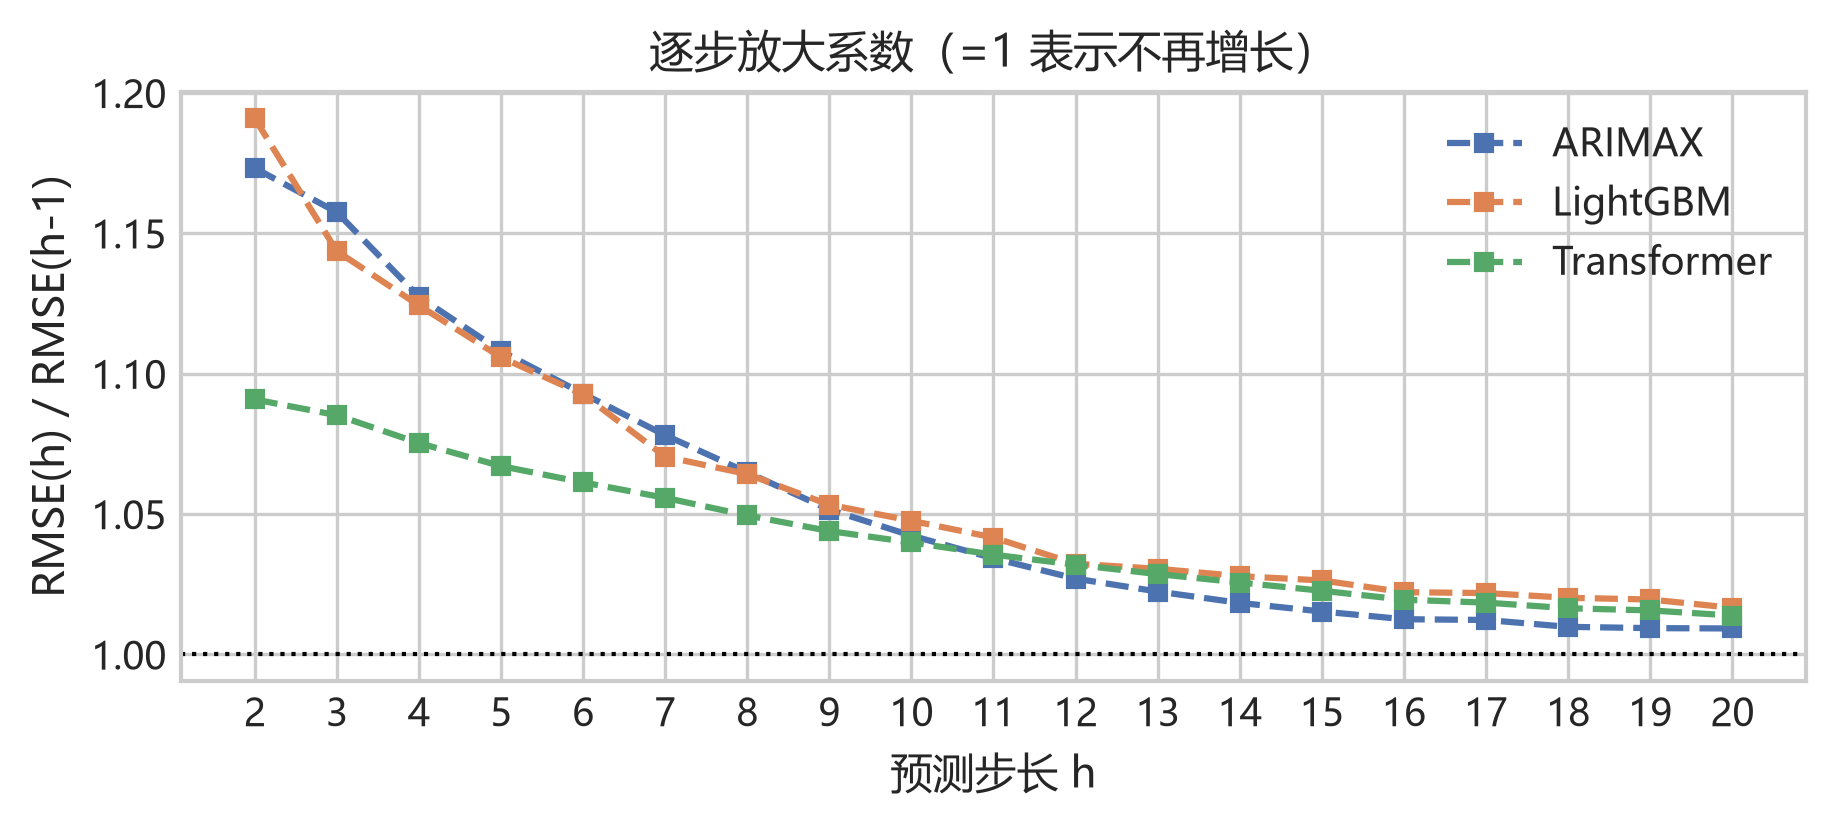

h=20 汇总：


,oracle RMSE,递归 RMSE,累积项 RMSE,累积贡献 / %,放大系数
模型,,,,,
ARIMAX,3.078,8.528,7.953,86.972,1.009
LightGBM,3.000,9.003,8.488,88.894,1.017
Transformer,3.998,8.755,7.789,79.149,1.014


In [17]:
# ---------- 10.5 误差累积的定量分解 ----------
from matplotlib.lines import Line2D

rows = []
for name in MS_MODELS:
    prev = None
    for h in range(1, H_MAX + 1):
        r_h, o_h = gv(name, "递归", h), gv(name, "oracle", h)
        rows.append({
            "模型": name, "步长 h": h,
            "oracle RMSE": o_h, "递归 RMSE": r_h,
            "累积项 RMSE": float(np.sqrt(max(r_h ** 2 - o_h ** 2, 0.0))),
            "累积贡献 / %": 100 * (1 - (o_h / r_h) ** 2),
            "放大系数": np.nan if prev is None else r_h / prev,
        })
        prev = r_h
acc = pd.DataFrame(rows)

print("误差分解（累积贡献 = 1 - MSE_oracle / MSE_递归），节选 h=1,5,10,15,20")
sel = [1, 5, 10, 15, 20]
display(acc[acc["步长 h"].isin(sel)].pivot_table(index="步长 h", columns="模型", values="累积贡献 / %").round(1))
print("逐步放大系数 RMSE(h) / RMSE(h-1)")
display(acc.pivot_table(index="步长 h", columns="模型", values="放大系数").round(3).T)
print("oracle RMSE / W（历史功率为真值时的可达精度）")
display(acc.pivot_table(index="步长 h", columns="模型", values="oracle RMSE").round(3).T)

# ---------- 回填误差的来源：各模型对历史功率的“记忆强度” ----------
ar_idx = [i for i, n in enumerate(FLAT_NAMES) if n.startswith("PC(")]
phi = w_arx[ar_idx]
print("ARIMAX 的自回归系数（标准化尺度）：")
print(f"  Σφ = {phi.sum():.3f} | Σ|φ| = {np.abs(phi).sum():.3f} | 最大 |φ| = {np.abs(phi).max():.3f}")
print(f"  滞后 1–5 阶系数：{np.round(phi[:5], 3)}")
print("参考：Σ|φ| 越接近 1，模型越倾向于把历史功率线性外推（近单位根），污染会被持续放大")

hs = list(range(1, H_MAX + 1))
show_labels = {1, 10, 20}

# ---------- 10d MSE 分解（单图，纵向拉长） ----------
fig, ax = plt.subplots(figsize=fig_size(0.50))
XL, XLAB = [], []
for i, name in enumerate(MS_MODELS):
    for h in range(1, H_MAX + 1):
        XL.append(i * (H_MAX + 2) + h)
        XLAB.append(f"{h}" if h in show_labels else "")
        mse_o = gv(name, "oracle", h) ** 2
        mse_r = gv(name, "递归", h) ** 2
        ax.bar(XL[-1], mse_o, color=COLORS[name], alpha=0.45, width=0.9)
        ax.bar(XL[-1], mse_r - mse_o, bottom=mse_o, color=COLORS[name], alpha=1.0, width=0.9)
    ax.axvline(i * (H_MAX + 2) + H_MAX + 0.5, color="gray", ls=":", lw=0.8)
    ax.text(i * (H_MAX + 2) + (H_MAX + 1) / 2, 100, name, ha="center", va="top",
            fontsize=FS_TICK, color="0.25")
ax.set_xticks(XL)
ax.set_xticklabels(XLAB, fontsize=FS_TICK)
ax.set_xlabel("预测步长 h", fontsize=FS_LABEL)
ax.set_ylabel("MSE / W²", fontsize=FS_LABEL)
ax.set_ylim(0, 112)              # 顶部留白放模型名与图例
ax.tick_params(labelsize=FS_TICK)
# 组名已直接标注在柱簇上方，无需图例（见上一行）
ax.grid(False)   # 组名已直接标注在柱簇上方，无需图例
ax.set_title("MSE 分解（深色=累积项，浅色=oracle）", fontsize=FS_TITLE)
fig.tight_layout()
savefig(fig, "10d_mse_decomp")
plt.show()

# ---------- 10e 回填误差占总误差的比例（单图） ----------
fig, ax = plt.subplots(figsize=fig_size(0.46))
for name in MS_MODELS:
    sub = acc[acc["模型"] == name]
    ax.plot(sub["步长 h"], sub["累积贡献 / %"], "o-", ms=4, color=COLORS[name], label=name)
ax.set_xticks(hs)
ax.set_xlabel("预测步长 h", fontsize=FS_LABEL)
ax.set_ylabel("累积贡献 / %", fontsize=FS_LABEL)
ax.set_ylim(0, 100)
ax.tick_params(labelsize=FS_TICK)
ax.set_title("回填误差占总误差的比例", fontsize=FS_TITLE)
ax.legend(fontsize=FS_LEGEND, loc="lower right", framealpha=0.9)
fig.tight_layout()
savefig(fig, "10e_backfill_share")
plt.show()

# ---------- 10f 逐步放大系数（单图） ----------
fig, ax = plt.subplots(figsize=fig_size(0.46))
for name in MS_MODELS:
    sub = acc[(acc["模型"] == name) & acc["放大系数"].notna()]
    ax.plot(sub["步长 h"], sub["放大系数"], "s--", ms=4, color=COLORS[name], label=name)
ax.axhline(1.0, color="k", ls=":", lw=1)
ax.set_xticks(hs[1:])
ax.set_xlabel("预测步长 h", fontsize=FS_LABEL)
ax.set_ylabel("RMSE(h) / RMSE(h-1)", fontsize=FS_LABEL)
ax.tick_params(labelsize=FS_TICK)
ax.set_title("逐步放大系数（=1 表示不再增长）", fontsize=FS_TITLE)
ax.legend(fontsize=FS_LEGEND, loc="upper right", framealpha=0.9)
fig.tight_layout()
savefig(fig, "10f_amplify")
plt.show()

# 各模型在最大步长的汇总
print(f"h={H_MAX} 汇总：")
display(acc[acc["步长 h"] == H_MAX].set_index("模型")[
    ["oracle RMSE", "递归 RMSE", "累积项 RMSE", "累积贡献 / %", "放大系数"]].round(3))

### 10.6 小结

**① 递归多步不需要任何额外训练。** 三个模型直接复用第 4–6 节的单步权重，纯推理完成 5,532 个样本 × 20 步的滚动（含 oracle 对照）仅需 4.5 s。模型数与步长无关，这是递归策略最大的工程价值。

**② 最优模型随步长三次切换，排名完全倒置。**

| 步长区间 | 最优模型 | 该区间末端的 RMSE（ARIMAX / LightGBM / Transformer） |
|---|---|---|
| $h\le10$（≤200 ms） | LightGBM | 7.204 / **6.973** / 6.987 |
| $h=11$–$15$（220–300 ms） | Transformer | 8.088 / 8.151 / **8.056** |
| $h\ge16$（≥320 ms） | ARIMAX | **8.528** / 9.003 / 8.755（$h=20$） |

单步时最强的 LightGBM 到 400 ms 反而最差（$R^2$ 从 0.918 掉到 0.257），单步时居中的 ARIMAX 反而最好（0.913→0.334）。**单步精度的优势在长步长下会被"以错传错"反噬**。

**③ 增长倍数与自回归依赖度同向，$h=1\to20$ 分别为 ARIMAX 2.76×、LightGBM 3.00×、Transformer 2.17×。** 这与第 9 节的 SHAP 结论一致：LightGBM 有 70.8% 的贡献来自 $\mathrm{PC}$ 自回归项，ARIMAX 仅 2.8%；ARIMAX 的 20 个自回归系数之和为 0.928（$\sum|\phi|=1.014$，近单位根结构），但单阶系数都很小（最大 0.42、滞后 1 阶仅 0.006）：它把历史功率当"持久信号"整体前移、而非依赖某一阶，因此污染一旦注入就会沿时间轴传播，而不是被快速遗忘。

**④ 退化几乎全部来自回填误差。** oracle 对照（回填真实标签）下三个模型的 RMSE 在 $h=1..20$ 上完全恒定（ARIMAX 3.078–3.099、LightGBM 3.000–3.017、Transformer 3.998–4.034）——只要历史功率准确，预测第 20 步与预测第 1 步一样准，因为外生输入 $x_{t+19}$ 是实时已知的。回填误差占总 MSE 的比例在 $h=20$ 时达到 **87.0% / 88.9% / 79.1%**，并且趋于饱和（$h=15\to20$ 三者分别只增加 1.5 / 2.5 / 3.9 个百分点）。

**⑤ 逐步放大系数收敛到 1.009–1.017，误差不会发散，但绝对量级已接近"无预测能力"的边界。** $h=20$ 时 RMSE 8.5–9.0 W，而 `PC` 自身的标准差为 10.46 W——虽然 $R^2$ 仍有 0.26–0.33，但相对误差（NRMSE）已达 18–20%，对于需要提前 400 ms 做功率调度的场景，实用价值有限。

**⑥ 工程建议。** $h\le10$（200 ms）时可以放心用 LightGBM 递归滚动（6.97 W，$R^2=0.56$）；$h>10$ 后模型间的优劣虽会反转，但差距只有 0.2–5.3%（远小于抑制漂移可换回的 5 W 以上），**真正的杠杆是"抑制漂移"而不是换模型**——定期用实测功率重置历史窗口（oracle 曲线给出完全重置时的上界 3.0 W），或对回填值做偏差校正（残差均值 0.4–0.7 W 的系统性正偏）。若无法重置，建议把预测步长限制在 200 ms 以内。

## 11. UR3e：结果对比与结论

本章汇总全部实验：单步预测（第 3–9 节）与递归多步预测（第 10 节，$h=1$–$20$）。统一配置为窗口 $L=20$（400 ms）、25 维输入、按轨迹划分、RMSE 为损失。

### 11.1 数据划分

| 子集 | 轨迹数 | 单步滑窗数 | 用途 |
|---|---|---|---|
| 训练集 | 92 | 82,560 | 拟合参数 |
| 验证集 | 24 | 20,520 | 早停 / 超参选择 |
| 测试集 | 12 | 5,760（多步实验用 5,532） | 最终评估（全程不参与任何决策） |

验证集轨迹编号（`random_state=42`，按轨迹分组划分）：`[1, 5, 11, 12, 13, 19, 27, 37, 41, 43, 46, 48, 54, 57, 68, 71, 84, 86, 89, 94, 95, 101, 110, 111]`。所有模型共用同一划分，标准化统计量只用训练集计算，不存在信息泄漏。多步实验要求每个基准时刻都有 20 个未来标签，故每条轨迹末尾少取 19 个点（12 条轨迹共少 228 个样本）。

### 11.2 单步预测精度

| 模型 | 验证 RMSE / W | 测试 RMSE / W | MAE / W | $R^2$ | NRMSE | P95 误差 / W | 逐轨迹 RMSE (均值 ± 标准差) |
|---|---|---|---|---|---|---|---|
| ARIMAX | 3.280 | **3.076** | 2.334 | 0.9116 | 6.70% | 6.19 | 2.94 ± 0.96 |
| LightGBM | 3.152 | **2.981** | 2.223 | 0.9170 | 6.49% | 5.86 | 2.81 ± 1.03 |
| Transformer | 2.860 | 4.001 | 2.942 | 0.8504 | 8.71% | 8.36 | 3.65 ± 1.72 |

关键观察：

1. **LightGBM 与 ARIMAX 精度接近**：测试集 RMSE 分别为 2.98 W 与 3.08 W，仅相差 3.1%，$R^2$ 均在 0.91 以上。残差直方图接近正态、均值仅 0.42–0.70 W 的正偏差，说明两者都学到了主要映射关系，剩余误差以零均值噪声为主。
2. **梯度提升树的非线性收益有限**：相较线性模型，LightGBM 把 RMSE 降低约 0.09 W（3%），说明在本任务的特征空间里，主映射近似线性——这与功率的物理构成 $P \approx \tau^\top\dot q + \beta\dot q$（力矩×速度的线性组合）一致。
3. **Transformer 验证集最优、测试集最差**：验证 RMSE 2.86 W 甚至优于另外两个模型，但测试集退化到 4.00 W（比 LightGBM 高 34%）。这是典型的**跨轨迹泛化不足**：注意力机制能拟合训练轨迹的局部动态，一旦测试轨迹的运动模式不同便明显偏移。逐轨迹标准差（1.72 W）也是三者中最大，说明其误差在轨迹间极不均衡。
4. **误差集中在高功率轨迹**：三条测试轨迹（编号 1、2、3，均值约 59 W）的 RMSE 显著高于低功率轨迹（轨迹 7/8/9 均值 39–40 W，RMSE 仅 1.9–2.2 W），与「功率越大、动力学非线性越强」的规律相符。高功率段的偏差方向三家不同：LightGBM 在峰值处系统性低估，Transformer 则出现过冲与过深下探（幅度被放大，残差标准差 3.92 W，明显大于 ARIMAX 3.00 W / LightGBM 2.95 W），这正是它测试 RMSE 最高的直接原因（见 8.1 拟合曲线与 8.2 散点）。

### 11.3 训练与推理效率

| 模型 | 训练耗时 | 训练设备 | 模型规模 | 单样本延迟 | 5,760 样本批量推理 | 吞吐 |
|---|---|---|---|---|---|---|
| ARIMAX | 2.3 s（含 5 折 $\alpha$ 搜索） | CPU | 545 个系数 | **0.009 ms** | **5.7 ms** | 1.0×10⁶ 样本/s |
| LightGBM | 14.9 s | CPU | 173 棵树 / 1.0 MB | 0.069 ms | 13.5 ms | 4.3×10⁵ 样本/s |
| Transformer | 95.8 s | CUDA（RTX 4060） | 73,921 参数 / 0.3 MB | 0.985 ms | 44.6 ms | 1.3×10⁵ 样本/s |

- ARIMAX 因闭式求解且复用 Gram 矩阵，训练与推理都最快，**参数量即模型本身**，可直接写入控制器；
- LightGBM 训练慢约 6.4 倍（逐树贪心分裂），单样本推理慢约 7.7 倍于 ARIMAX，但仍在 50 Hz 实时性要求（20 ms/样本）内留有约 290 倍余量；
- Transformer 训练需 GPU，耗时约为 LightGBM 的 6.4 倍、ARIMAX 的 41 倍；单样本延迟 0.99 ms 虽仍在实时范围内，但批量吞吐最低（约为 ARIMAX 的 1/8）。注意此处延迟包含 Python/回调开销，实际部署需 TorchScript 或 ONNX 优化。

> 计时对机器负载很敏感：同一配置多次运行，Transformer 训练在 95–190 s、LightGBM 在 10–33 s 之间变化，单样本延迟也会有 2–3 倍波动，**比值与量级比绝对值更可靠**。
>
> 多步（递归）实验**不产生额外训练开销**：三个模型直接复用上述单步权重，5,532 个样本 × 20 步的滚动推理（含 oracle 对照）总共只需 4.5 s。

**综合结论**：若以「20 ms 控制周期内完成计算」为标准，三者都满足；差异主要落在部署成本与可维护性上。

### 11.4 可解释性

SHAP 归因把每个模型的预测分解到三类语义组（占该模型自身总 |SHAP| 的百分比）：

| 模型 | 当前输入 $x_t$ | 历史输入 $x_{t-1..t-20}$ | 功率自回归 $\mathrm{PC}_{t-1..t-20}$ |
|---|---|---|---|
| ARIMAX（线性 SHAP） | 14.5% | **82.7%** | 2.8% |
| LightGBM（TreeSHAP） | 4.7% | 24.5% | **70.8%** |
| Transformer（GradientSHAP） | **30.3%** | 40.2% | 29.5% |

三种模型呈现出**三种截然不同的"信息使用策略"**：

- **ARIMAX 是"物理驱动"的**：$M$ 独占 33.7%，$d\dot q_1$ / $d\dot q_2$ / $d\dot q_3$ / $d\dot q_4$ 合计约 28%，而自回归项仅 2.8%。它几乎不看历史功率，而是用「质量/惯量 × 关节速度」直接解释当前功率——这与 $P=\tau\cdot\dot q$ 的物理关系高度吻合，**回归系数符号也可直接对照力学含义**。
- **LightGBM 是"自回归驱动"的**：功率自回归项（$\mathrm{PC}_{t-1..t-20}$ 合计）占 70.8%，增益重要度口径下更是 91.9%，其中 $\mathrm{PC}(t-1)$ 是单个最重要的输入，本质上学到的是"功率的短期惯性"。它把末端力/力矩（$F_z$、$F_y$、$F_{a3}$，各约 1%）当作非线性修正项。
- **Transformer 介于两者之间且最"均衡"**：三组分别约 30% / 40% / 30%，说明注意力机制同时利用了历史功率与物理状态。其梯度归因显示 $d\dot q_1$、$d\dot q_2$、$M$、$d\dot q_6$ 均为重要的物理量，与 ARIMAX 的物理结论一致；但它对 $\mathrm{PC}$ 的依赖（17.4 W）远高于线性模型，这既是它验证集表现好的原因，也是跨轨迹泛化差的根源。

**注意力结构**（9.3 节）进一步印证了"局部性"假设：当前 token 对 $t-1$ 的注意力最高（0.110），随滞后单调衰减至 $t-20$ 的 0.027，对当前时刻自身输入的注意力为 0.044。注意力呈平滑递减而非尖峰，说明模型在做**多尺度加权平均**而非依赖单一时刻——这与 ARIMAX 的分布式滞后系数结构在定性上一致。

**可解释性排序**：ARIMAX（系数解析、可写进机理文档）> LightGBM（SHAP 精确、但 545 维特征的重要性较分散）> Transformer（GradientSHAP 为采样近似，注意力权重不等于因果贡献）。

### 11.5 递归多步预测（$h=1$–$20$）的结论

测试集 RMSE（W），括号内为 $R^2$；**粗体**为该步长下的最优模型：

| $h$ | 跨度 | ARIMAX | LightGBM | Transformer |
|---|---|---|---|---|
| 1 | 20 ms | 3.088（0.913） | **2.998（0.918）** | 4.030（0.852） |
| 2 | 40 ms | 3.623（0.880） | **3.570（0.884）** | 4.396（0.824） |
| 3 | 60 ms | 4.194（0.840） | **4.083（0.848）** | 4.770（0.792） |
| 4 | 80 ms | 4.728（0.796） | **4.591（0.808）** | 5.129（0.760） |
| 5 | 100 ms | 5.239（0.750） | **5.077（0.765）** | 5.473（0.727） |
| 6 | 120 ms | 5.725（0.701） | **5.547（0.719）** | 5.809（0.692） |
| 7 | 140 ms | 6.172（0.653） | **5.938（0.679）** | 6.133（0.657） |
| 8 | 160 ms | 6.572（0.606） | **6.319（0.636）** | 6.437（0.622） |
| 9 | 180 ms | 6.911（0.564） | **6.656（0.596）** | 6.719（0.588） |
| 10 | 200 ms | 7.204（0.527） | **6.973（0.556）** | 6.987（0.555） |
| 11 | 220 ms | 7.450（0.493） | 7.263（0.519） | **7.236（0.522）** |
| 12 | 240 ms | 7.651（0.466） | 7.498（0.487） | **7.467（0.491）** |
| 13 | 260 ms | 7.823（0.441） | 7.726（0.455） | **7.680（0.461）** |
| 14 | 280 ms | 7.966（0.420） | 7.942（0.423） | **7.877（0.433）** |
| 15 | 300 ms | 8.088（0.402） | 8.151（0.393） | **8.056（0.407）** |
| 16 | 320 ms | **8.190（0.386）** | 8.332（0.365） | 8.213（0.383） |
| 17 | 340 ms | **8.290（0.371）** | 8.514（0.337） | 8.365（0.360） |
| 18 | 360 ms | **8.372（0.358）** | 8.686（0.309） | 8.502（0.338） |
| 19 | 380 ms | **8.450（0.346）** | 8.856（0.282） | 8.635（0.317） |
| 20 | 400 ms | **8.528（0.334）** | 9.003（0.257） | 8.755（0.298） |

回填误差在总 MSE 中的占比（%）：

| $h$ | 1 | 5 | 10 | 15 | 20 |
|---|---|---|---|---|---|
| ARIMAX | 0 | 65.2 | 81.6 | 85.5 | 87.0 |
| LightGBM | 0 | 64.7 | 81.4 | 86.4 | 88.9 |
| Transformer | 0 | 45.9 | 67.0 | 75.2 | 79.1 |

1. **递归多步零训练成本**：模型直接复用单步权重，模型数与步长无关；$3\times20\times2$ 组滚动推理仅需 4.5 s。
2. **最优模型随步长三次切换、排名完全倒置**：$h\le10$（≤200 ms）LightGBM 最优；$h=11$–$15$（220–300 ms）Transformer 最优；$h\ge16$（≥320 ms）ARIMAX 最优。$h=20$ 时三者依次为 8.53 / 9.00 / 8.76 W，而 $h=1$ 时为 3.09 / 3.00 / 4.03 W。**单步越准（越依赖功率自回归），长步长退化越严重**。
3. **退化速度与自回归依赖度同向**：$h=1\to20$ 的增长倍数为 ARIMAX 2.76×、LightGBM 3.00×、Transformer 2.17×。LightGBM 的 SHAP 有 70.8% 落在 $\mathrm{PC}$ 自回归项（增益口径 91.9%），ARIMAX 仅 2.8%；ARIMAX 的 20 个自回归系数之和 0.928、$\sum|\phi|=1.014$（近单位根），把历史功率当作"持久信号"外推——注意其单阶系数都很小（最大 0.42，滞后 1 阶仅 0.006），因此在 SHAP 中对**预测方差**的贡献只有 2.8%；但它把历史功率的**水平**整体前移，污染仍会被搬运，只是速度比 LightGBM 慢。
4. **回填是误差的唯一来源**：oracle 对照（历史功率用真值）下，三个模型的 RMSE 在 20 个步长上完全恒定（3.08 / 3.00 / 4.00 W）；回填占比从 $h=5$ 的 65%/46% 升到 $h=20$ 的 87%/89%/79%，并趋于饱和。
5. **实用边界**：$h\le10$（200 ms）时 LightGBM 的 $R^2$ 仍有 0.56，可以作为前瞻调度依据；$h=20$（400 ms）时 RMSE 已接近 `PC` 的标准差（10.46 W）、NRMSE 达 18–20%，只剩趋势信息，建议配合窗口重置或偏差校正使用。

### 11.6 选型建议

| 场景 | 推荐模型 | 理由 |
|---|---|---|
| 控制器的在线功耗估算（单步） | **ARIMAX** | 推理 0.009 ms、内存仅几 KB、系数可审计，精度仅比最优差 3% |
| 离线数据分析 / 能效优化 | **LightGBM** | 精度最高（2.98 W），训练快且无需特征缩放，SHAP 可直接定位耗能变量 |
| ≤200 ms 前瞻（递归，$h\le10$） | **LightGBM（递归滚动）** | 全区间最优，$h=10$ 时 6.97 W、$R^2=0.56$；只需维护一个模型 |
| 220–300 ms 前瞻（递归，$h=11$–$15$） | **Transformer（递归滚动）** | $h=15$ 时 8.06 W，略优于 ARIMAX（8.09）与 LightGBM（8.15） |
| ≥320 ms 前瞻（递归，$h\ge16$） | **ARIMAX（递归滚动）** | $h=20$ 时 8.53 W，比 LightGBM 低 5.3%；且推理 0.009 ms、可审计 |
| 算力受限 / 需要可审计的滚动预测 | **ARIMAX（递归滚动）** | 全步长区间都在前三且系数可解释，$h=20$ 时反而最优 |

总体而言：**单步任务 LightGBM 精度最优、ARIMAX 工程最优**（差距 3% 以内）；**递归多步任务没有"通吃"的模型**——步长越长，单步优势越不可靠，$h\ge16$ 后应转向以稳定性为先的 ARIMAX。

### 11.7 局限与后续工作

1. **数据规模限制**：仅 116 条轨迹（约 5.7 万步），深度模型的容量优势无法体现。Transformer 的验证–测试反转让早停策略失效风险增大，后续可引入按轨迹的交叉验证或更强的正则（如 dropout 提高到 0.3）。
2. **多步评估的条件**：递归实验假设 $t$ 之后的外生输入 $x_{t+1..t+19}$ 完全准确（由编码器或规划器提供）。真实系统中这些量也存在测量噪声，若一并考虑，退化会快于本章结果。此外多步样本每条轨迹少 19 个基准点，$h=1$ 的数值（3.088/2.998/4.030）与 11.2 节的单步结果（3.076/2.981/4.001）有 <0.03 W 的差异，属样本集差异。
3. **标签噪声**：`PC` 的平滑残差约 1.7 W（5 点 SG），这部分不可约误差已占单步 RMSE 的一半以上；对标签做平滑虽能显著降低指标，但会掩盖真实的高频波动，本文因此保持原始标签。
4. **窗口长度**：400 ms（$L=20$）在精度与计算量之间取得平衡；继续加长窗口会引入更多共线性而未带来精度收益。注意这与**预测**步长是两件事：本章把预测步长推到 400 ms 后，误差已接近随机水平。
5. **可扩展方向**：① 滚动预测中定期用实测量重置历史窗口（本文的 oracle 曲线给出性能上界 3.0 W），或对回填值做偏差校正（残差均值 0.4–0.7 W）；② 采用"输出多步 + 递归校正"的混合结构（如 Seq2Seq 一次输出多步再做一致性平滑），以缓解长步长下累积项占比过高的问题；③ 加入轨迹级上下文（运动类型标签）以缓解 Transformer 的跨轨迹泛化问题；④ 尝试物理信息神经网络（PINN），把 $P=\tau\cdot\dot q$ 作为硬约束嵌入损失函数。

## 12. 跨机型验证：UR10e

前 11 节的所有结论都来自 **UR3e**（额定负载 3 kg、50 Hz）。一个自然的问题是：这些结论是**任务的共性**，还是 **UR3e 的个性**？

本章把同一套流程原封不动地搬到 **UR10e**（额定负载 10 kg、100 Hz）上重做单步预测与可解释性分析，用于检验结论的跨平台可迁移性。

| 项目 | UR3e（第 2–11 节） | UR10e（本章） |
|---|---|---|
| 训练 / 测试轨迹 | 116 / 12 | 96 / 12 |
| 采样频率 | 50 Hz（$\Delta t$ = 20 ms） | 100 Hz（$\Delta t$ = 10 ms） |
| 窗口 $L=20$ 覆盖时长 | 400 ms | 200 ms |
| 输入维度 | 25（同一组物理量） | 25 |
| 划分比例与随机种子 | 按轨迹 8:2，seed = 42 | 完全相同 |
| 模型与超参搜索 | ARIMAX / LightGBM / Transformer | 完全相同 |

**协议一致性说明**

1. **滑窗与划分**：直接复用第 2–3 节的 `build_windows`，`LAGS=20`、特征列、按轨迹切窗的逻辑完全不变；划分仍用 `GroupShuffleSplit(test_size=0.2, random_state=42)`，保证两个数据集"验证集占 20% 轨迹"的口径一致。
2. **标准化**：UR10e 用**自己的**训练集统计量（均值/标准差），不借用 UR3e 的任何信息。
3. **模型**：ARIMAX 的 $\alpha$ 搜索网格、LightGBM 的全部超参、Transformer 的结构与训练配方（AdamW + 余弦退火 + 早停）都保持不变。
4. **本章只做单步预测**，与第 3–9 节同口径，便于逐项对照；递归多步（第 10 节）的结论已在 UR3e 上充分讨论，不再在 UR10e 上重复。

> 变量命名：本章所有中间量都以 `u10_` 前缀命名，**不会覆盖第 2–11 节的 UR3e 变量**，因此第 12.6 节可以直接用内存中的 UR3e 结果做对照。

In [18]:
# ---------- 12.1 UR10e 的数据、滑窗与划分（流程与第 2–3 节完全一致） ----------
u10_train = pd.read_csv(DATA_DIR / "UR10e_train.csv")
u10_test = pd.read_csv(DATA_DIR / "UR10e_test.csv")

u10_stat = pd.DataFrame(
    {
        "训练集": [
            len(u10_train), u10_train[GROUP].nunique(),
            u10_train[GROUP].value_counts().median(),
            u10_train[TARGET].mean(), u10_train[TARGET].std(),
            u10_train[TARGET].min(), u10_train[TARGET].max(),
        ],
        "测试集": [
            len(u10_test), u10_test[GROUP].nunique(),
            u10_test[GROUP].value_counts().median(),
            u10_test[TARGET].mean(), u10_test[TARGET].std(),
            u10_test[TARGET].min(), u10_test[TARGET].max(),
        ],
    },
    index=["样本数", "轨迹数", "轨迹长度中位数", "PC 均值/W", "PC 标准差/W", "PC 最小/W", "PC 最大/W"],
)
display(u10_stat.round(3))

u10_dt = float(u10_train.groupby(GROUP)["t1"].diff().median())
print(f"采样周期 {u10_dt*1000:.1f} ms（{1/u10_dt:.0f} Hz）→ 窗口 L={LAGS} 覆盖 {LAGS*u10_dt*1000:.0f} ms")
print("缺失值:", int(u10_train.isna().sum().sum()), "/", int(u10_test.isna().sum().sum()))

# 直接复用同一个 build_windows（列名、LAGS、特征定义完全相同）
u10_Seq_tr, u10_Cur_tr, u10_y_tr, u10_tid_tr, _, _ = build_windows(u10_train)
u10_Seq_te, u10_Cur_te, u10_y_te, u10_tid_te, u10_pos_te, u10_t_te = build_windows(u10_test)

# 同样的按轨迹划分（同一 seed、同一比例）
u10_gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
u10_tr_idx, u10_va_idx = next(u10_gss.split(u10_Seq_tr, u10_y_tr, groups=u10_tid_tr))
u10_train_ids = np.unique(u10_tid_tr[u10_tr_idx])
u10_valid_ids = np.unique(u10_tid_tr[u10_va_idx])

print(f"训练 {u10_train_ids.size} 条轨迹 / {len(u10_tr_idx)} 个窗口")
print(f"验证 {u10_valid_ids.size} 条轨迹 / {len(u10_va_idx)} 个窗口")
print(f"测试 {np.unique(u10_tid_te).size} 条轨迹 / {len(u10_y_te)} 个窗口")
print("【UR10e 验证集轨迹编号】", sorted(int(t) for t in u10_valid_ids))

# 标准化（仅用 UR10e 训练集统计量，与 UR3e 完全独立）
u10_ch_mean = u10_Seq_tr[u10_tr_idx].reshape(-1, len(ALL_CHANNELS)).mean(0).astype(np.float32)
u10_ch_std = u10_Seq_tr[u10_tr_idx].reshape(-1, len(ALL_CHANNELS)).std(0).astype(np.float32) + 1e-8
u10_y_mu, u10_y_sd = float(u10_y_tr[u10_tr_idx].mean()), float(u10_y_tr[u10_tr_idx].std())

u10_scale_seq = lambda A: (A - u10_ch_mean) / u10_ch_std
u10_scale_cur = lambda A: (A - u10_ch_mean[: len(FEATURE_COLS)]) / u10_ch_std[: len(FEATURE_COLS)]
u10_scale_y = lambda y: (y - u10_y_mu) / u10_y_sd
u10_inv_y = lambda z: z * u10_y_sd + u10_y_mu

u10_S_tr = u10_scale_seq(u10_Seq_tr[u10_tr_idx])
u10_S_va = u10_scale_seq(u10_Seq_tr[u10_va_idx])
u10_S_te = u10_scale_seq(u10_Seq_te)
u10_C_tr, u10_C_va, u10_C_te = (u10_scale_cur(u10_Cur_tr[u10_tr_idx]),
                                u10_scale_cur(u10_Cur_tr[u10_va_idx]),
                                u10_scale_cur(u10_Cur_te))
u10_Y_tr, u10_Y_va, u10_Y_te = u10_y_tr[u10_tr_idx], u10_y_tr[u10_va_idx], u10_y_te

u10_F_tr = flatten(u10_S_tr, u10_C_tr)
u10_F_va = flatten(u10_S_va, u10_C_va)
u10_F_te = flatten(u10_S_te, u10_C_te)
print(f"展平维度 {u10_F_tr.shape[1]}；训练/验证/测试 {u10_F_tr.shape} / {u10_F_va.shape} / {u10_F_te.shape}")
print(f"目标统计量（UR10e 训练集）：均值 {u10_y_mu:.2f} W，标准差 {u10_y_sd:.2f} W")

,训练集,测试集
样本数,48000.000,6000.000
轨迹数,96.000,12.000
轨迹长度中位数,500.000,500.000
PC 均值/W,55.806,55.064
PC 标准差/W,33.034,19.756
PC 最小/W,-54.825,3.595
PC 最大/W,904.138,166.920


采样周期 10.0 ms（100 Hz）→ 窗口 L=20 覆盖 200 ms
缺失值: 0 / 0
训练 76 条轨迹 / 36480 个窗口
验证 20 条轨迹 / 9600 个窗口
测试 12 条轨迹 / 5760 个窗口
【UR10e 验证集轨迹编号】 [1, 5, 11, 13, 19, 23, 27, 31, 32, 34, 43, 54, 65, 70, 74, 78, 80, 81, 86, 95]
展平维度 545；训练/验证/测试 (36480, 545) / (9600, 545) / (5760, 545)
目标统计量（UR10e 训练集）：均值 56.35 W，标准差 34.68 W


### 12.2 UR10e 的单步精度

三个模型都重新训练（不迁移 UR3e 的权重），但**超参数搜索范围、早停策略、损失函数与评估指标完全不变**，这样两个数据集的差异只来自数据本身。

*（注意：为与 UR3e 保持口径一致，计时与指标均在原始功率量纲下计算。）*

In [19]:
# ---------- 12.2 三个模型的训练与单步评估（超参与第 4–6 节完全一致） ----------
# (a) ARIMAX：同样的 5 折分组 CV 选 alpha（复用 Gram 矩阵）
u10_t0 = time.perf_counter()
u10_fold = {a: [] for a in alpha_grid}
for kitr, kiva in GroupKFold(n_splits=5).split(u10_F_tr, u10_Y_tr, groups=u10_tid_tr[u10_tr_idx]):
    Xk = np.asarray(u10_F_tr[kitr], np.float64)
    yk = u10_scale_y(u10_Y_tr[kitr])
    xm, ym = Xk.mean(0), yk.mean()
    Xk -= xm
    G, bb = Xk.T @ Xk, Xk.T @ (yk - ym)
    del Xk
    Xv, Yv = u10_F_tr[kiva].astype(np.float64), u10_Y_tr[kiva]
    for a in alpha_grid:
        A = G.copy()
        A.flat[:: A.shape[0] + 1] += a
        w_ = np.linalg.solve(A, bb)
        u10_fold[a].append(math.sqrt(mean_squared_error(Yv, u10_inv_y(Xv @ w_ + (ym - xm @ w_)))))
    del Xv, G, bb

u10_cv = pd.DataFrame({"alpha": alpha_grid,
                       "CV-RMSE / W": [float(np.mean(u10_fold[a])) for a in alpha_grid]})
u10_cv = u10_cv.sort_values("CV-RMSE / W").reset_index(drop=True)
display(u10_cv.round(4))
u10_alpha = float(u10_cv.loc[0, "alpha"])
u10_w, u10_b = ridge_fit(u10_F_tr, u10_scale_y(u10_Y_tr), u10_alpha)
u10_t_arx = time.perf_counter() - u10_t0
u10_pred_va_arx = u10_inv_y(u10_F_va @ u10_w + u10_b)
u10_pred_te_arx = u10_inv_y(u10_F_te @ u10_w + u10_b)
print(f"[ARIMAX] alpha={u10_alpha:g} | 训练 {u10_t_arx:.2f} s | "
      f"验证 {math.sqrt(mean_squared_error(u10_Y_va, u10_pred_va_arx)):.3f} W | "
      f"测试 {math.sqrt(mean_squared_error(u10_Y_te, u10_pred_te_arx)):.3f} W")

# (b) LightGBM：同一套参数与早停策略
u10_dtr = lgb.Dataset(u10_F_tr, label=u10_Y_tr, feature_name=FLAT_NAMES)
u10_dva = lgb.Dataset(u10_F_va, label=u10_Y_va, reference=u10_dtr)
u10_t0 = time.perf_counter()
u10_model_lgb = lgb.train(lgb_params, u10_dtr, num_boost_round=3000, valid_sets=[u10_dva],
                          valid_names=["valid"], callbacks=[lgb.early_stopping(100, verbose=False)])
u10_t_lgb = time.perf_counter() - u10_t0
u10_pred_va_lgb = u10_model_lgb.predict(u10_F_va, num_iteration=u10_model_lgb.best_iteration)
u10_pred_te_lgb = u10_model_lgb.predict(u10_F_te, num_iteration=u10_model_lgb.best_iteration)
print(f"[LightGBM] 轮数={u10_model_lgb.best_iteration} | 训练 {u10_t_lgb:.2f} s | "
      f"验证 {math.sqrt(mean_squared_error(u10_Y_va, u10_pred_va_lgb)):.3f} W | "
      f"测试 {math.sqrt(mean_squared_error(u10_Y_te, u10_pred_te_lgb)):.3f} W")

# (c) Transformer：结构与训练配方相同
#     共用的 eval/predict 函数内部读取全局 y_mu/y_sd，这里临时切到 UR10e 的目标尺度
_u3e_stats = (y_mu, y_sd)
y_mu, y_sd = u10_y_mu, u10_y_sd

torch.manual_seed(SEED)      # 固定初始化，避免结果随运行次序漂移
u10_model_tf = PowerTransformer().to(DEVICE)
u10_train_ds = TensorDataset(torch.from_numpy(u10_S_tr), torch.from_numpy(u10_C_tr),
                             torch.from_numpy(u10_scale_y(u10_Y_tr).astype(np.float32)))
u10_val_ds = TensorDataset(torch.from_numpy(u10_S_va), torch.from_numpy(u10_C_va),
                           torch.from_numpy(u10_scale_y(u10_Y_va).astype(np.float32)))
if DEVICE.type == "cuda":
    torch.cuda.synchronize()
u10_t0 = time.perf_counter()
u10_hist, u10_best_val = train_transformer(u10_model_tf, u10_train_ds, u10_val_ds)
if DEVICE.type == "cuda":
    torch.cuda.synchronize()
u10_t_tf = time.perf_counter() - u10_t0
u10_pred_va_tf = predict_transformer(u10_model_tf, u10_S_va, u10_C_va)
u10_pred_te_tf = predict_transformer(u10_model_tf, u10_S_te, u10_C_te)

y_mu, y_sd = _u3e_stats      # 恢复 UR3e 的目标尺度，后续章节继续可用
print(f"[Transformer] 训练 {u10_t_tf:.2f} s | 验证 {u10_best_val:.3f} W | "
      f"测试 {math.sqrt(mean_squared_error(u10_Y_te, u10_pred_te_tf)):.3f} W")

# (d) 精度汇总
u10_PRED = {"ARIMAX": u10_pred_te_arx, "LightGBM": u10_pred_te_lgb, "Transformer": u10_pred_te_tf}
u10_acc = pd.DataFrame({m: regression_metrics(u10_Y_te, p) for m, p in u10_PRED.items()}).T
u10_acc.index.name = "模型"
print("UR10e 测试集精度")
display(u10_acc.round(4))

u10_rows = []
for tid, idx in pd.Series(np.arange(len(u10_Y_te))).groupby(u10_tid_te):
    ii = idx.to_numpy()
    row = {"trajectory_id": int(tid), "样本数": len(ii), "PC 均值/W": u10_Y_te[ii].mean()}
    for m in u10_PRED:
        row[m] = math.sqrt(mean_squared_error(u10_Y_te[ii], u10_PRED[m][ii]))
    u10_rows.append(row)
u10_traj = pd.DataFrame(u10_rows)
print("UR10e 逐轨迹 RMSE（W）")
display(u10_traj.round(3))
print(u10_traj[list(u10_PRED)].agg(["mean", "std", "min", "max"]).round(3))

,alpha,CV-RMSE / W
0,1.0,5.9617
1,0.1,5.9660
2,100.0,5.9724
3,10.0,5.9825
4,300.0,6.0125
5,1000.0,6.3257


[ARIMAX] alpha=1 | 训练 0.99 s | 验证 3.718 W | 测试 3.850 W
[LightGBM] 轮数=482 | 训练 19.17 s | 验证 3.279 W | 测试 3.199 W
epoch   1 | train MSE  0.5389 | val RMSE   9.061 W | best   9.061 W
epoch   2 | train MSE  0.1871 | val RMSE   7.890 W | best   7.890 W
epoch   3 | train MSE  0.1056 | val RMSE   7.279 W | best   7.279 W
epoch   4 | train MSE  0.0920 | val RMSE   7.736 W | best   7.279 W
epoch   5 | train MSE  0.0796 | val RMSE   6.918 W | best   6.918 W
epoch   6 | train MSE  0.0712 | val RMSE   6.660 W | best   6.660 W
epoch   8 | train MSE  0.0663 | val RMSE   6.967 W | best   6.660 W
epoch  10 | train MSE  0.0624 | val RMSE   6.783 W | best   6.411 W
epoch  12 | train MSE  0.0579 | val RMSE   6.204 W | best   6.204 W
epoch  14 | train MSE  0.0555 | val RMSE   6.696 W | best   6.204 W
epoch  16 | train MSE  0.0527 | val RMSE   6.418 W | best   6.193 W
epoch  18 | train MSE  0.0474 | val RMSE   6.527 W | best   6.193 W
epoch  20 | train MSE  0.0474 | val RMSE   6.381 W | best   6.193 W
epoc

,RMSE / W,MAE / W,R²,NRMSE / %,P95 |误差| / W,Max |误差| / W
模型,,,,,,
ARIMAX,3.8504,2.7488,0.9617,6.9928,7.1192,47.9823
LightGBM,3.1988,2.2501,0.9736,5.8094,5.8638,31.7972
Transformer,4.5364,3.2751,0.9468,8.2387,9.0678,34.4631


UR10e 逐轨迹 RMSE（W）


,trajectory_id,样本数,PC 均值/W,ARIMAX,LightGBM,Transformer
0,1,480,57.882999,4.395,3.221,5.405
1,2,480,50.391998,2.729,2.196,3.122
2,3,480,47.833000,2.335,1.993,2.729
3,4,480,68.463997,5.541,5.127,8.860
4,5,480,75.348999,6.415,5.258,6.535
5,6,480,52.626999,3.303,2.933,3.333
6,7,480,45.443001,2.507,2.193,2.524
7,8,480,45.243000,2.624,2.186,2.510
8,9,480,46.207001,2.639,2.252,2.906
9,10,480,62.854000,5.000,3.816,4.826


      ARIMAX  LightGBM  Transformer
mean   3.621     3.003        4.135
std    1.367     1.150        1.948
min    2.335     1.993        2.510
max    6.415     5.258        8.860


### 12.3 UR10e 的计算效率

计时方法与第 7 节完全相同：单样本延迟取 200 次调用的中位数（batch=1），批量推理为整个测试集的耗时（重复 3 次取中位数）。注意 UR10e 是 100 Hz 采样，控制周期只有 10 ms，比 UR3e 更苛刻——从下表看，三个模型的单样本延迟分别为 0.009 / 0.124 / 0.934 ms，相对 10 ms 控制周期仍留有 10 倍以上余量，实时性不是瓶颈。

In [20]:
# ---------- 12.3 计算效率（计时口径与第 7 节一致） ----------
u10_single = {
    "ARIMAX": bench(lambda: u10_inv_y(u10_F_te[:1] @ u10_w + u10_b)),
    "LightGBM": bench(lambda: u10_model_lgb.predict(u10_F_te[:1],
                                                    num_iteration=u10_model_lgb.best_iteration)),
}
u10_seq1 = torch.from_numpy(u10_S_te[:1]).to(DEVICE)
u10_cur1 = torch.from_numpy(u10_C_te[:1]).to(DEVICE)


@torch.no_grad()
def u10_tf_single():
    return float(u10_model_tf(u10_seq1, u10_cur1).item())


u10_single["Transformer"] = bench(u10_tf_single)

# 批量计时需临时切到 UR10e 的目标尺度（predict_transformer 内部用全局 y_mu/y_sd）
_u3e_stats = (y_mu, y_sd)
y_mu, y_sd = u10_y_mu, u10_y_sd
u10_batch = {
    "ARIMAX": bench_batch(lambda: u10_inv_y(u10_F_te @ u10_w + u10_b)),
    "LightGBM": bench_batch(lambda: u10_model_lgb.predict(u10_F_te,
                                                          num_iteration=u10_model_lgb.best_iteration)),
    "Transformer": bench_batch(lambda: predict_transformer(u10_model_tf, u10_S_te, u10_C_te)),
}
y_mu, y_sd = _u3e_stats

u10_eff = pd.DataFrame(
    {
        "训练耗时 / s": [u10_t_arx, u10_t_lgb, u10_t_tf],
        "训练设备": ["CPU", "CPU", str(DEVICE).upper()],
        "模型规模": [
            f"{u10_w.size} 个系数",
            f"{u10_model_lgb.best_iteration} 棵树 / {len(u10_model_lgb.model_to_string()) / 1024:.0f} KB",
            f"{sum(p.numel() for p in u10_model_tf.parameters()):,} 参数",
        ],
        "单样本延迟 / ms": [u10_single[m] for m in ["ARIMAX", "LightGBM", "Transformer"]],
        f"测试集 {len(u10_Y_te)} 样本推理 / ms": [u10_batch[m] for m in ["ARIMAX", "LightGBM", "Transformer"]],
        "吞吐 / (样本·s⁻¹)": [len(u10_Y_te) / (u10_batch[m] / 1000)
                          for m in ["ARIMAX", "LightGBM", "Transformer"]],
    },
    index=["ARIMAX", "LightGBM", "Transformer"],
)
u10_eff.index.name = "模型"
display(u10_eff.round(3))

,训练耗时 / s,训练设备,模型规模,单样本延迟 / ms,测试集 5760 样本推理 / ms,吞吐 / (样本·s⁻¹)
模型,,,,,,
ARIMAX,0.987,CPU,545 个系数,0.009,6.702,859393.644
LightGBM,19.170,CPU,482 棵树 / 2744 KB,0.124,49.058,117410.846
Transformer,49.245,CUDA,"73,921 参数",0.934,48.783,118073.435


### 12.4 UR10e 的预测效果

三张图与第 8 节一一对应：功率波动最大的测试轨迹的逐点拟合、三模型的预测-实测散点、以及逐轨迹 RMSE 对比。重点看两件事：**高功率段的偏差**与**逐轨迹误差的离散程度**。

[saved] figures\train_test\12a_u10_traj_pred.png  (300 dpi)


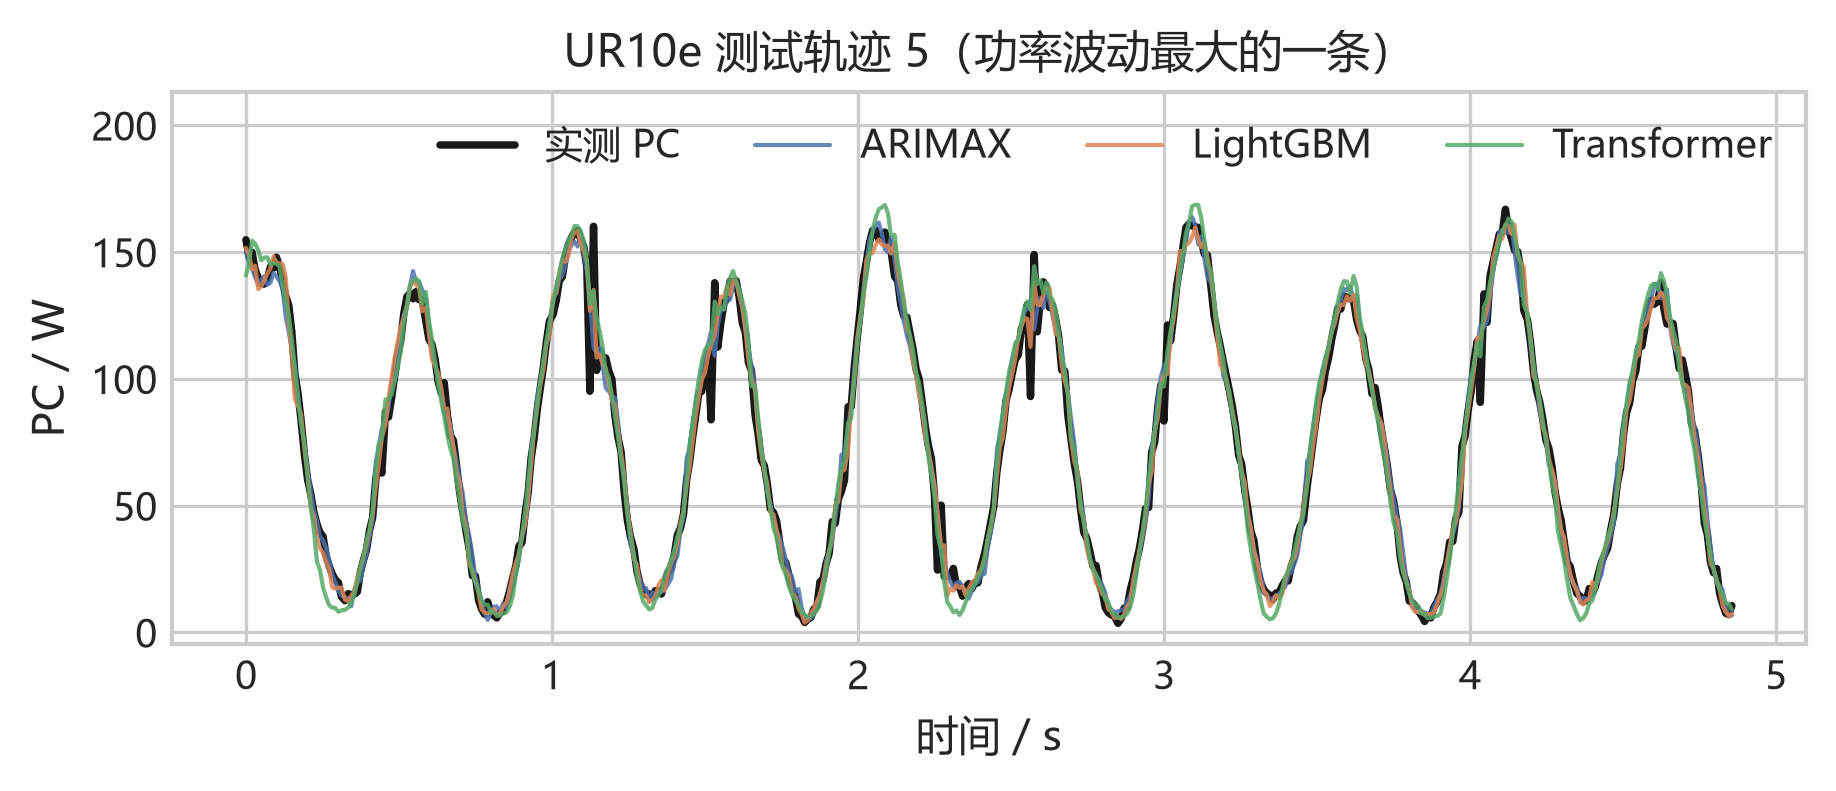

[saved] figures\train_test\12b_u10_scatter.png  (300 dpi)


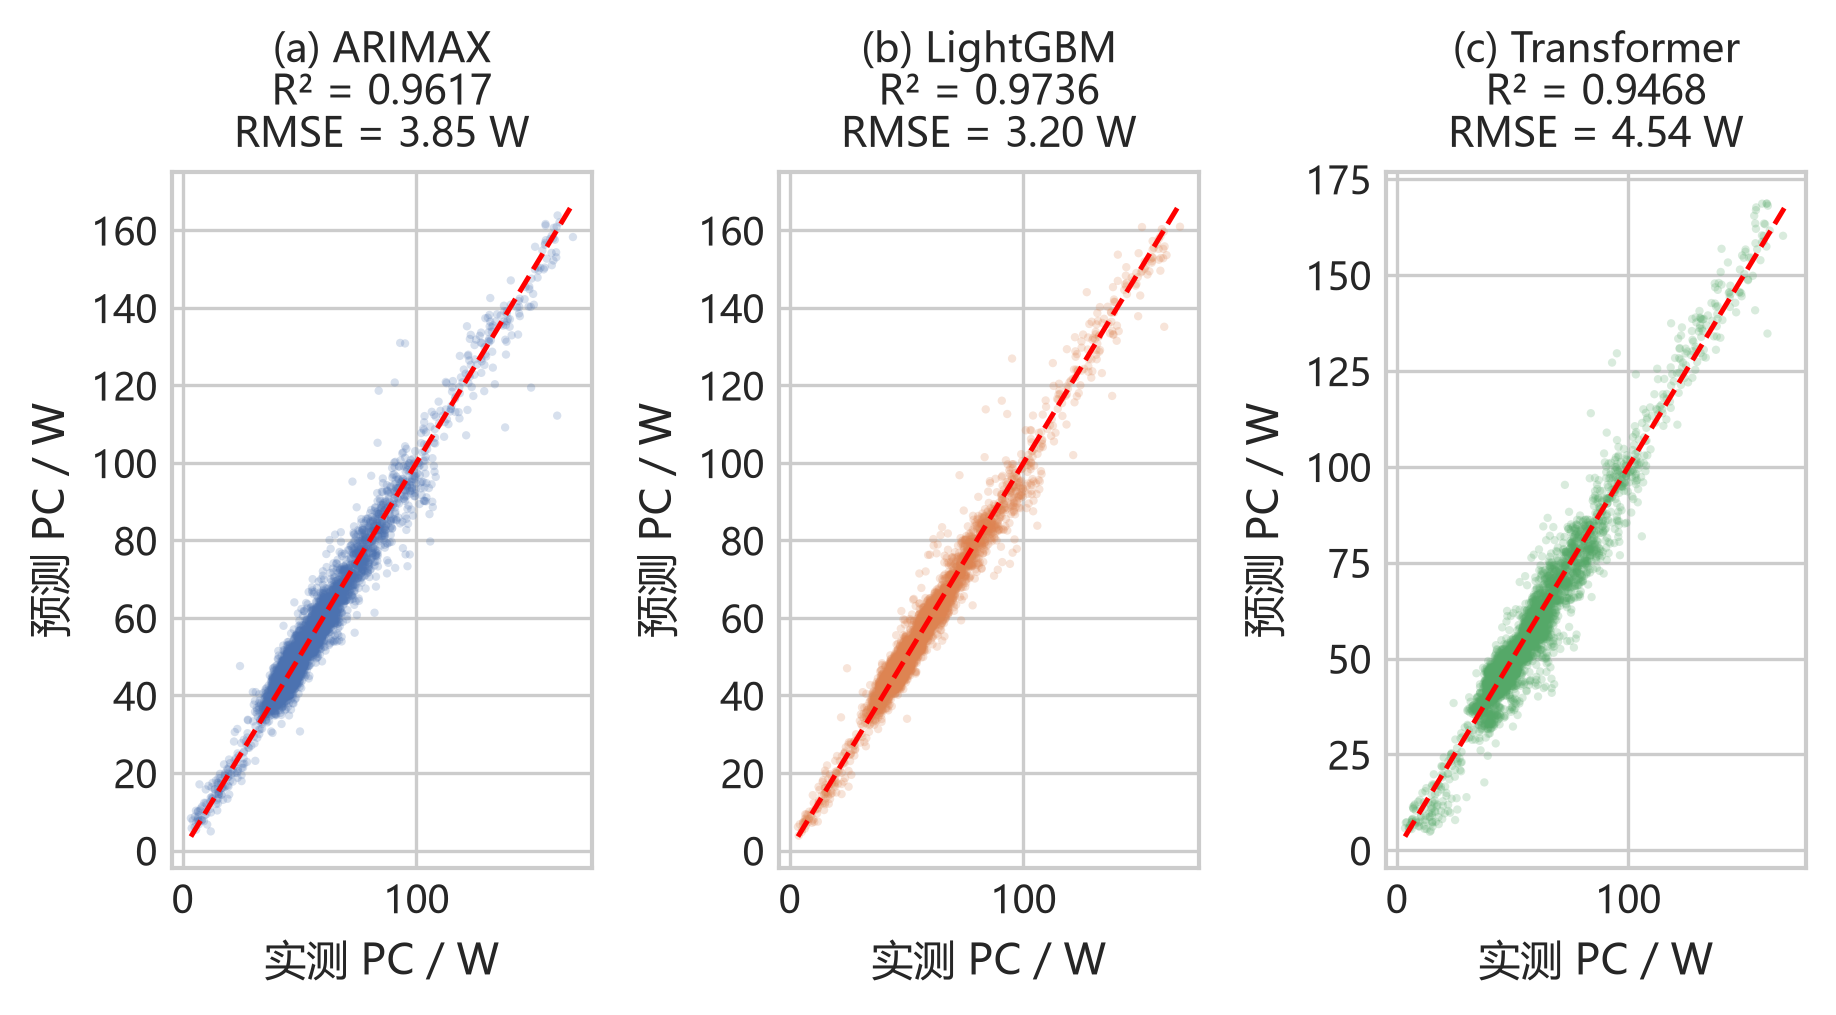

[saved] figures\train_test\12c_u10_traj_rmse.png  (300 dpi)


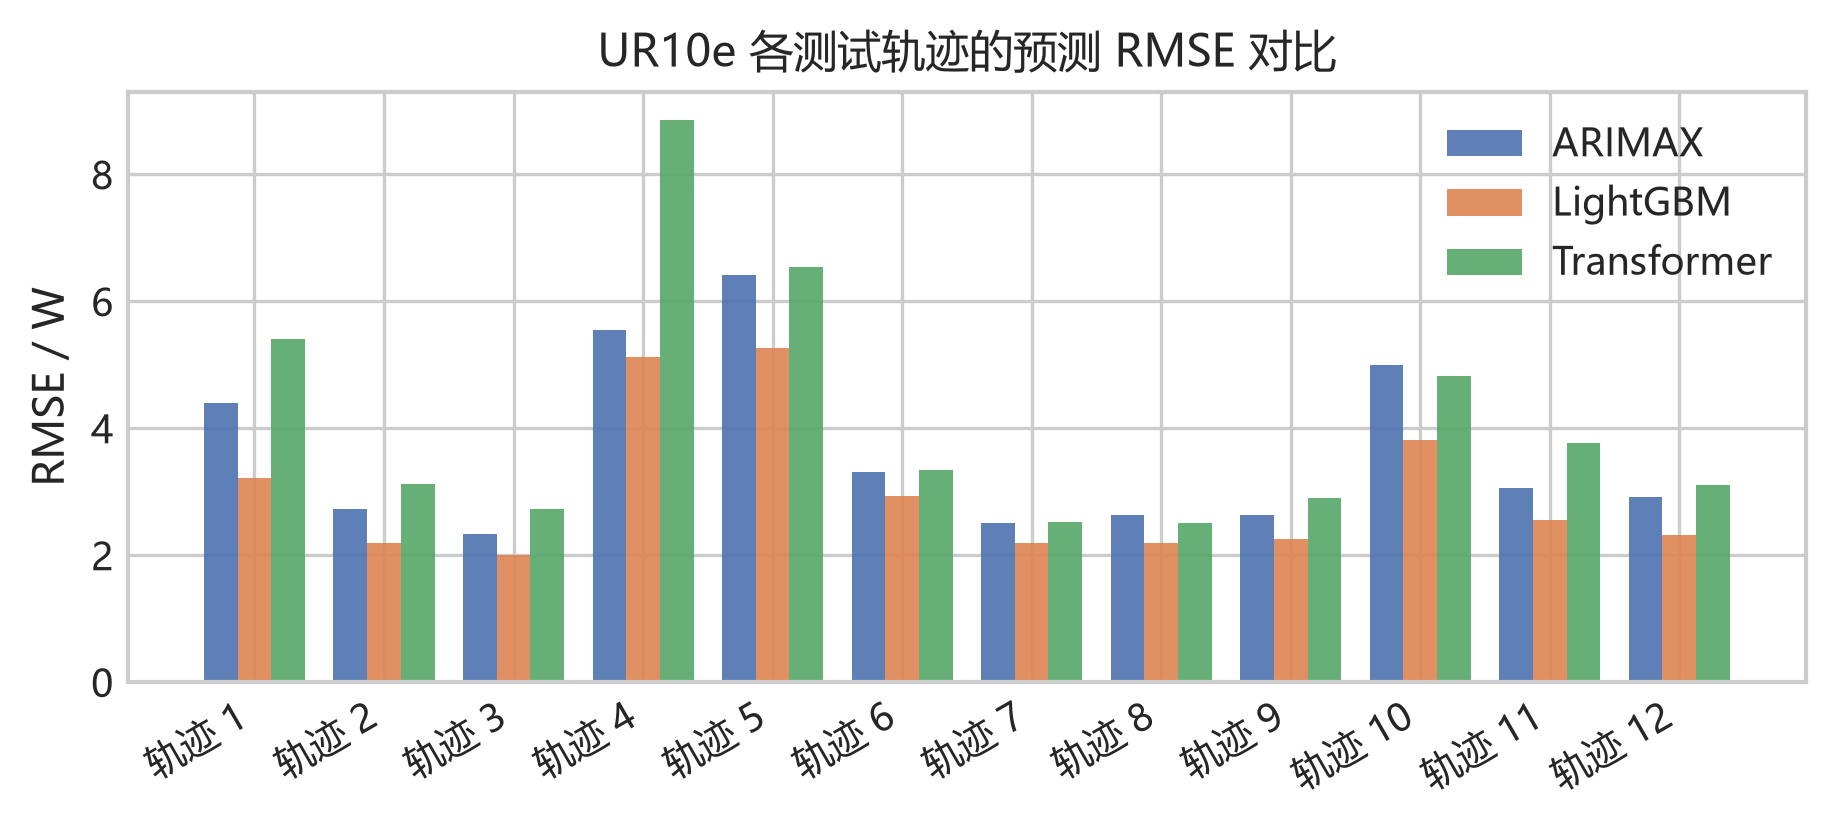

In [21]:
# ---------- 12.4 可视化：典型轨迹、散点与逐轨迹 RMSE ----------
u10_sel = (
    pd.DataFrame({"tid": u10_tid_te, "y": u10_Y_te})
    .groupby("tid")["y"].agg(["std", "count"])
    .query("count >= 300")
    .sort_values("std", ascending=False)
    .head(1)
    .index.tolist()
)

# ---------- 12a UR10e 典型测试轨迹 ----------
fig, ax = plt.subplots(figsize=fig_size(0.44))
tid = u10_sel[0]
m = u10_tid_te == tid
ax.plot(u10_t_te[m] - u10_t_te[m][0], u10_Y_te[m], "k-", lw=1.8, alpha=0.9, label="实测 PC")
for name, p in u10_PRED.items():
    ax.plot(u10_t_te[m] - u10_t_te[m][0], p[m], lw=1.0, alpha=0.85, color=COLORS[name], label=name)
ax.set_title(f"UR10e 测试轨迹 {int(tid)}（功率波动最大的一条）", fontsize=FS_TITLE)
ax.set_xlabel("时间 / s", fontsize=FS_LABEL)
ax.set_ylabel("PC / W", fontsize=FS_LABEL)
ax.tick_params(labelsize=FS_TICK)
ax.legend(ncol=4, fontsize=FS_LEGEND, loc="upper right", framealpha=0.9)
_lo, _hi = ax.get_ylim()
ax.set_ylim(_lo, _hi + 0.20 * (_hi - _lo))
fig.tight_layout()
savefig(fig, "12a_u10_traj_pred")
plt.show()

# ---------- 12b UR10e 三模型预测-实测散点（同类图罗列，保留 1×3） ----------
fig, axes = plt.subplots(1, 3, figsize=fig_size(0.56))
for ax, tag, (name, p) in zip(axes, "abc", u10_PRED.items()):
    ax.scatter(u10_Y_te, p, s=4, alpha=0.22, color=COLORS[name], edgecolors="none")
    lo = min(u10_Y_te.min(), p.min())
    hi = max(u10_Y_te.max(), p.max())
    ax.plot([lo, hi], [lo, hi], "r--", lw=1.2)
    tag_title(ax, tag, f"{name}\nR² = {r2_score(u10_Y_te, p):.4f}\n"
                       f"RMSE = {math.sqrt(mean_squared_error(u10_Y_te, p)):.2f} W", fontsize=9.5)
    ax.set_xlabel("实测 PC / W", fontsize=FS_LABEL)
    ax.set_ylabel("预测 PC / W", fontsize=FS_LABEL)
    ax.tick_params(labelsize=FS_TICK)
fig.tight_layout()
savefig(fig, "12b_u10_scatter")
plt.show()

# ---------- 12c UR10e 逐轨迹 RMSE ----------
fig, ax = plt.subplots(figsize=fig_size(0.46))
x = np.arange(len(u10_traj))
width = 0.26
for k, name in enumerate(u10_PRED):
    ax.bar(x + (k - 1) * width, u10_traj[name], width, label=name, color=COLORS[name], alpha=0.9)
ax.set_xticks(x)
ax.set_xticklabels([f"轨迹 {t}" for t in u10_traj["trajectory_id"]], rotation=30, ha="right",
                   fontsize=FS_TICK)
ax.set_ylabel("RMSE / W", fontsize=FS_LABEL)
ax.set_title("UR10e 各测试轨迹的预测 RMSE 对比", fontsize=FS_TITLE)
ax.tick_params(labelsize=FS_TICK)
ax.legend(fontsize=FS_LEGEND)
fig.tight_layout()
savefig(fig, "12c_u10_traj_rmse")
plt.show()

### 12.5 UR10e 的可解释性

沿用第 9 节的四套工具：ARIMAX 标准化系数、LightGBM 增益重要度、Transformer 注意力、以及三模型统一的 SHAP 归因（线性 SHAP / TreeSHAP / GradientSHAP）。为便于与 UR3e 对照，所有归因同样聚合到**当前输入 / 历史输入 / 功率自回归**三个语义组，并统一换算成"占该模型自身总 |SHAP| 的百分比"。

[saved] figures\train_test\12d_u10_arimax_coef.png  (300 dpi)


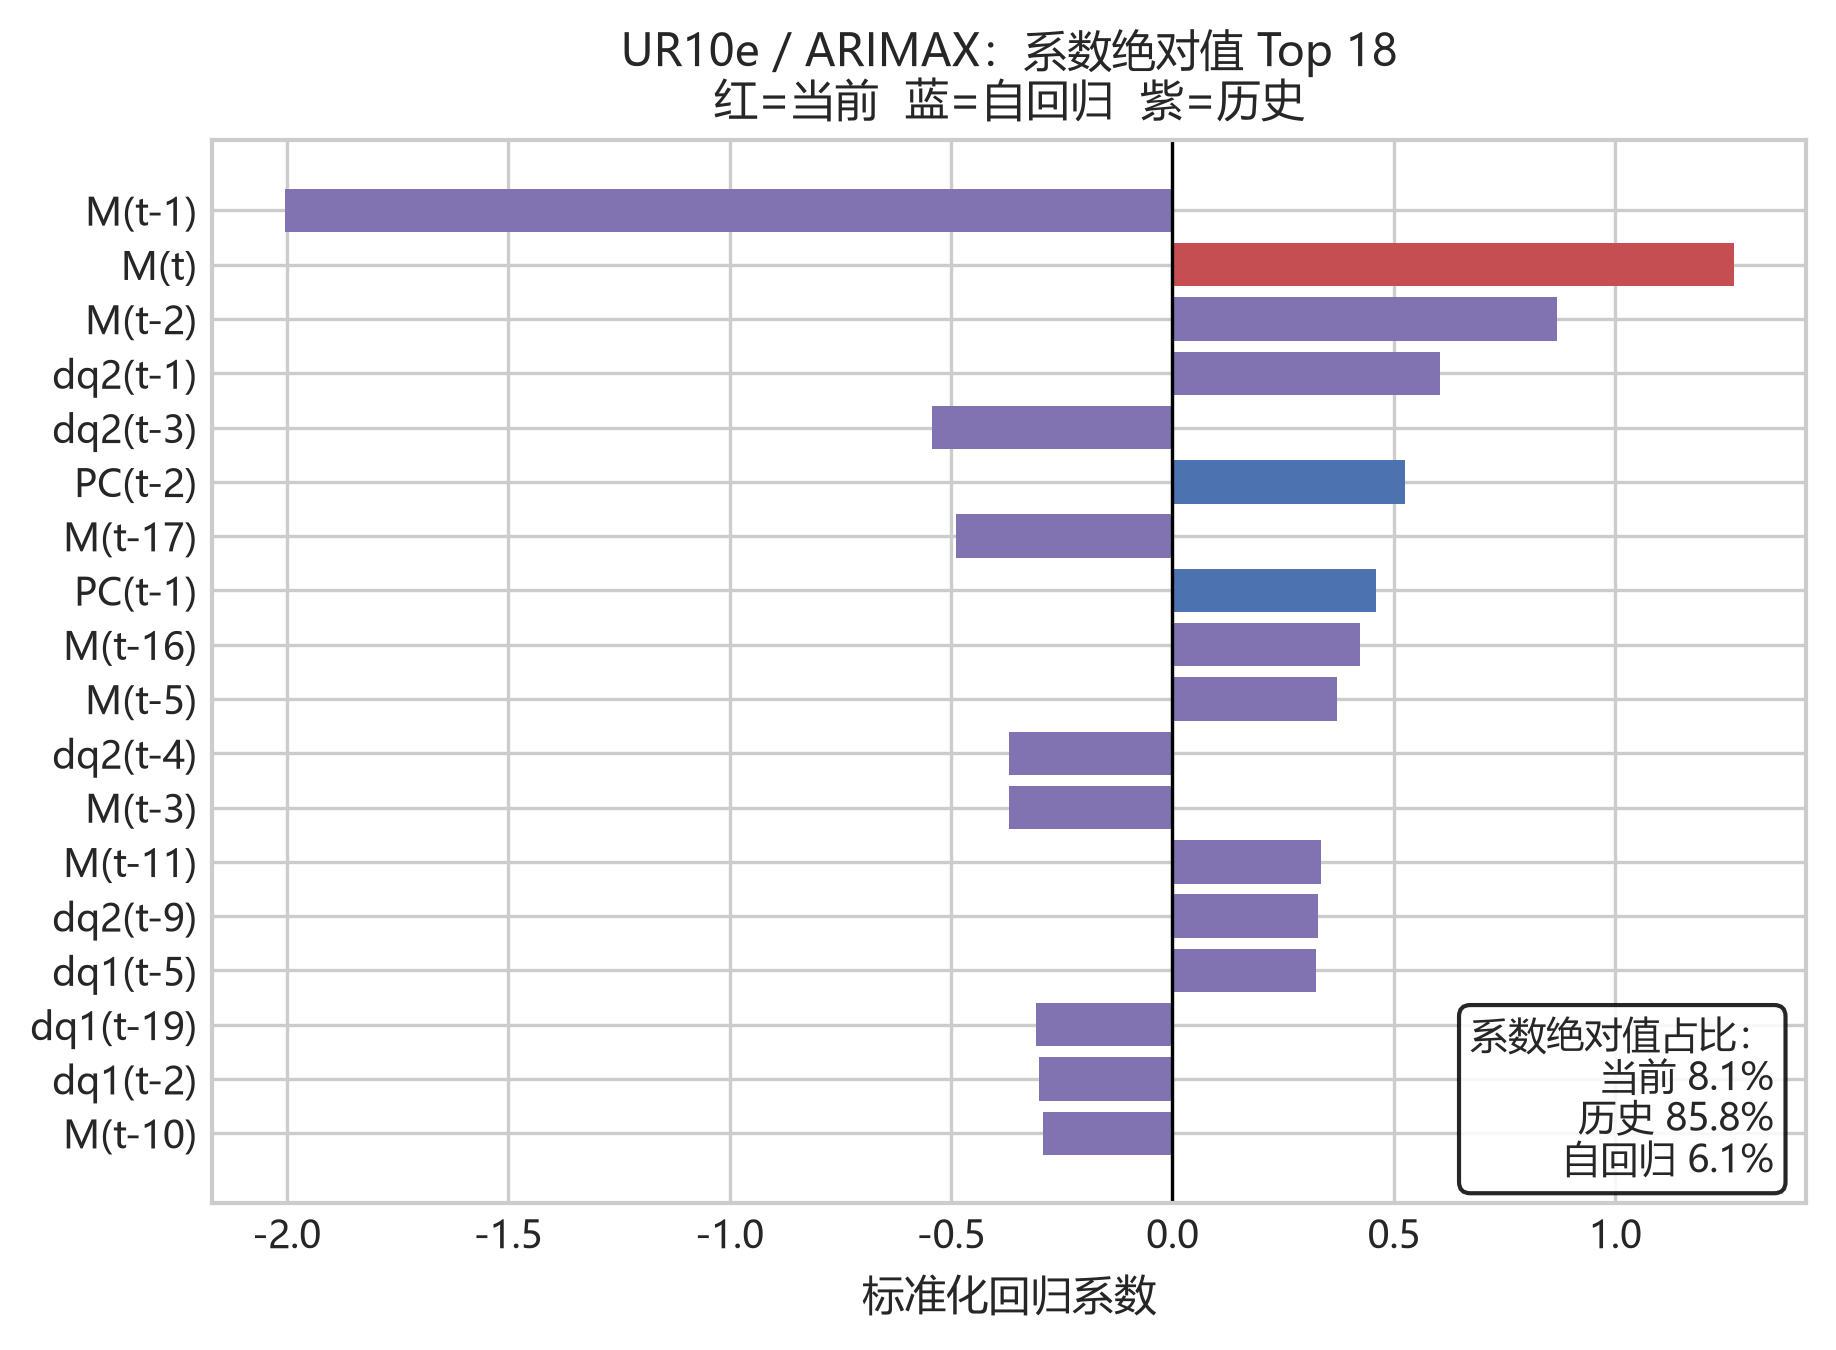

[saved] figures\train_test\12e_u10_lgb_gain.png  (300 dpi)


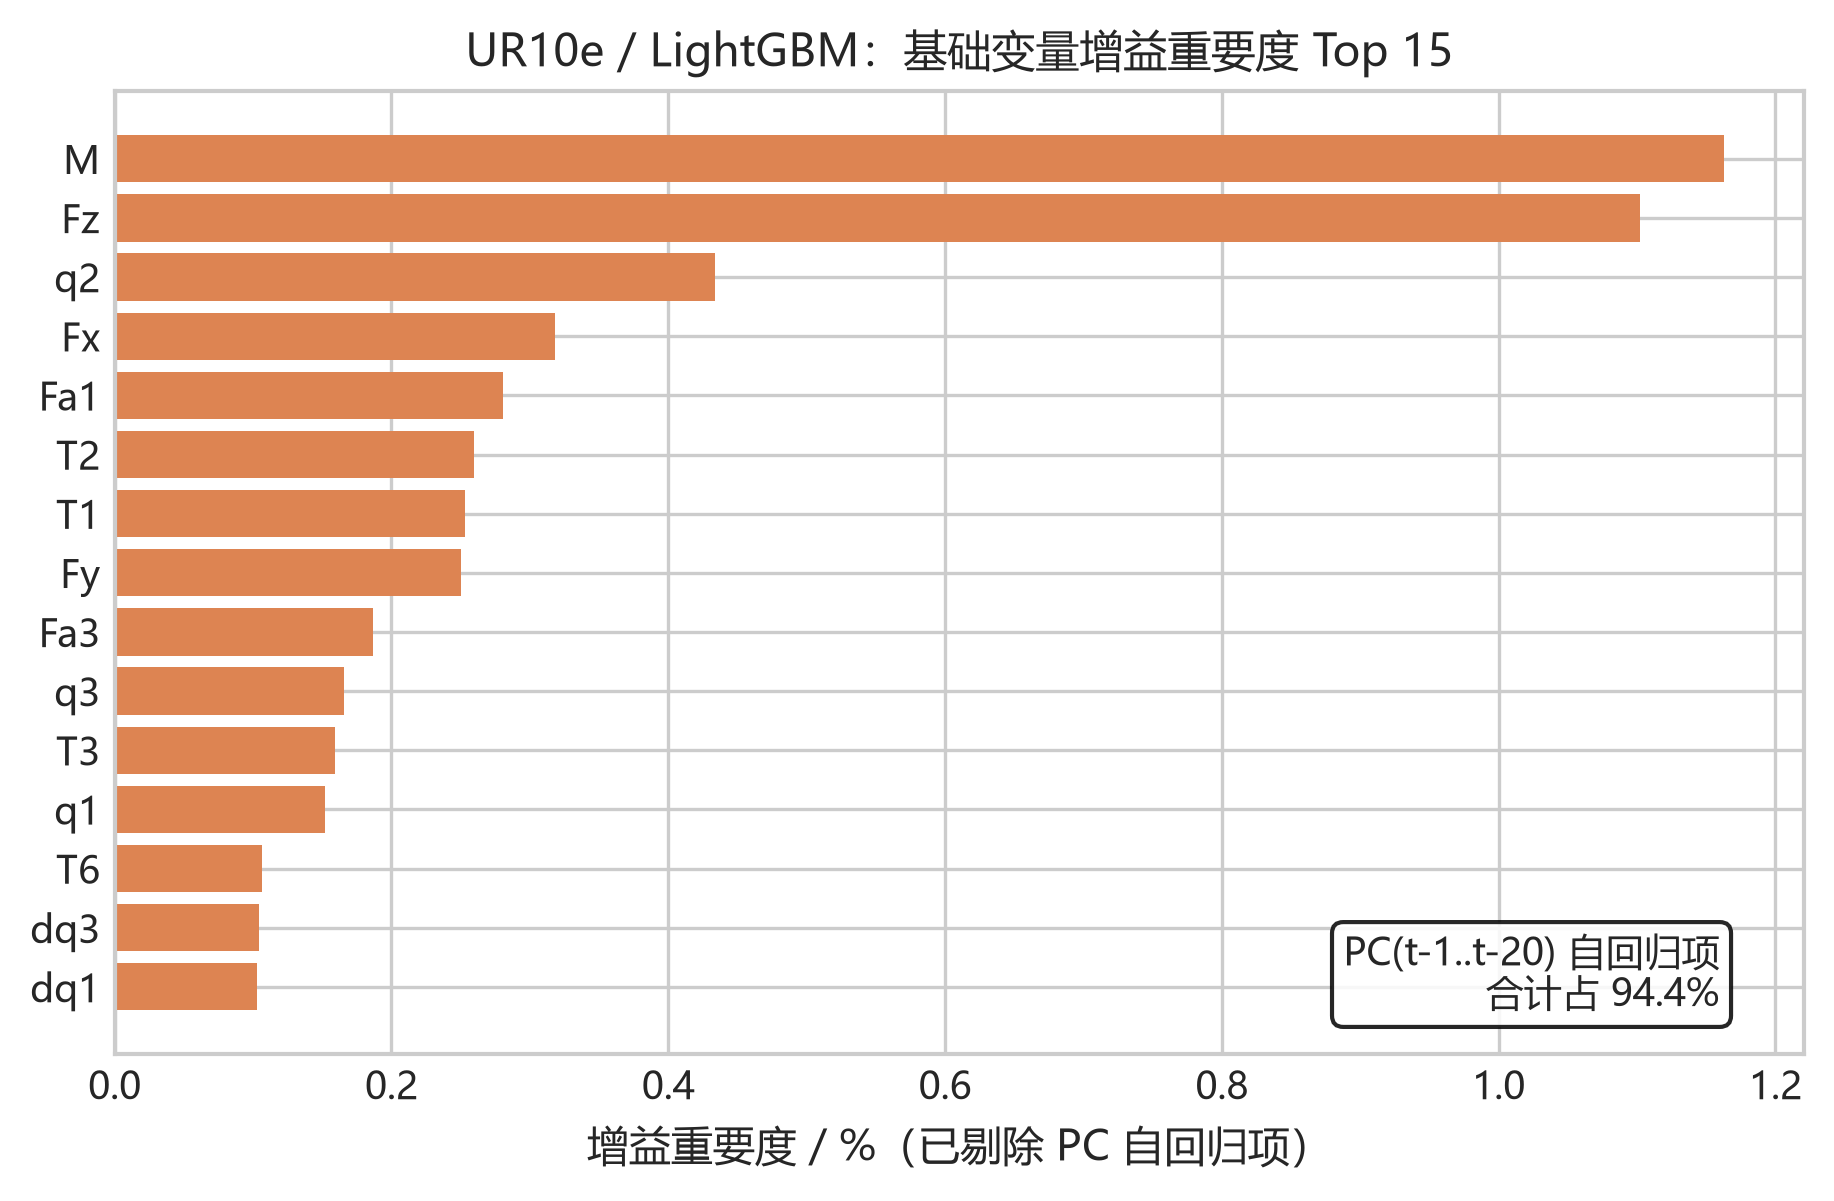

UR10e / Transformer：最后一层当前 token 的注意力
     t-20: 0.0373
     t-19: 0.0360
     t-18: 0.0361
     t-17: 0.0350
     t-16: 0.0364
     t-15: 0.0382
     t-14: 0.0356
     t-13: 0.0378
     t-12: 0.0384
     t-11: 0.0456
     t-10: 0.0468
      t-9: 0.0491
      t-8: 0.0498
      t-7: 0.0537
      t-6: 0.0579
      t-5: 0.0584
      t-4: 0.0613
      t-3: 0.0662
      t-2: 0.0679
      t-1: 0.0676
    t(当前): 0.0449
注意力峰值位置: t-2
UR10e / TreeSHAP 可加性检查 = 1.24e-10 W
UR10e：三个模型的 SHAP 归因构成（%）


,当前输入 x(t),历史输入 x(t-1..t-20),功率自回归 PC(t-1..t-20)
ARIMAX,8.70,86.98,4.32
LightGBM,3.78,26.23,70.00
Transformer,16.72,66.90,16.38


[saved] figures\train_test\12f_u10_shap_share.png  (300 dpi)


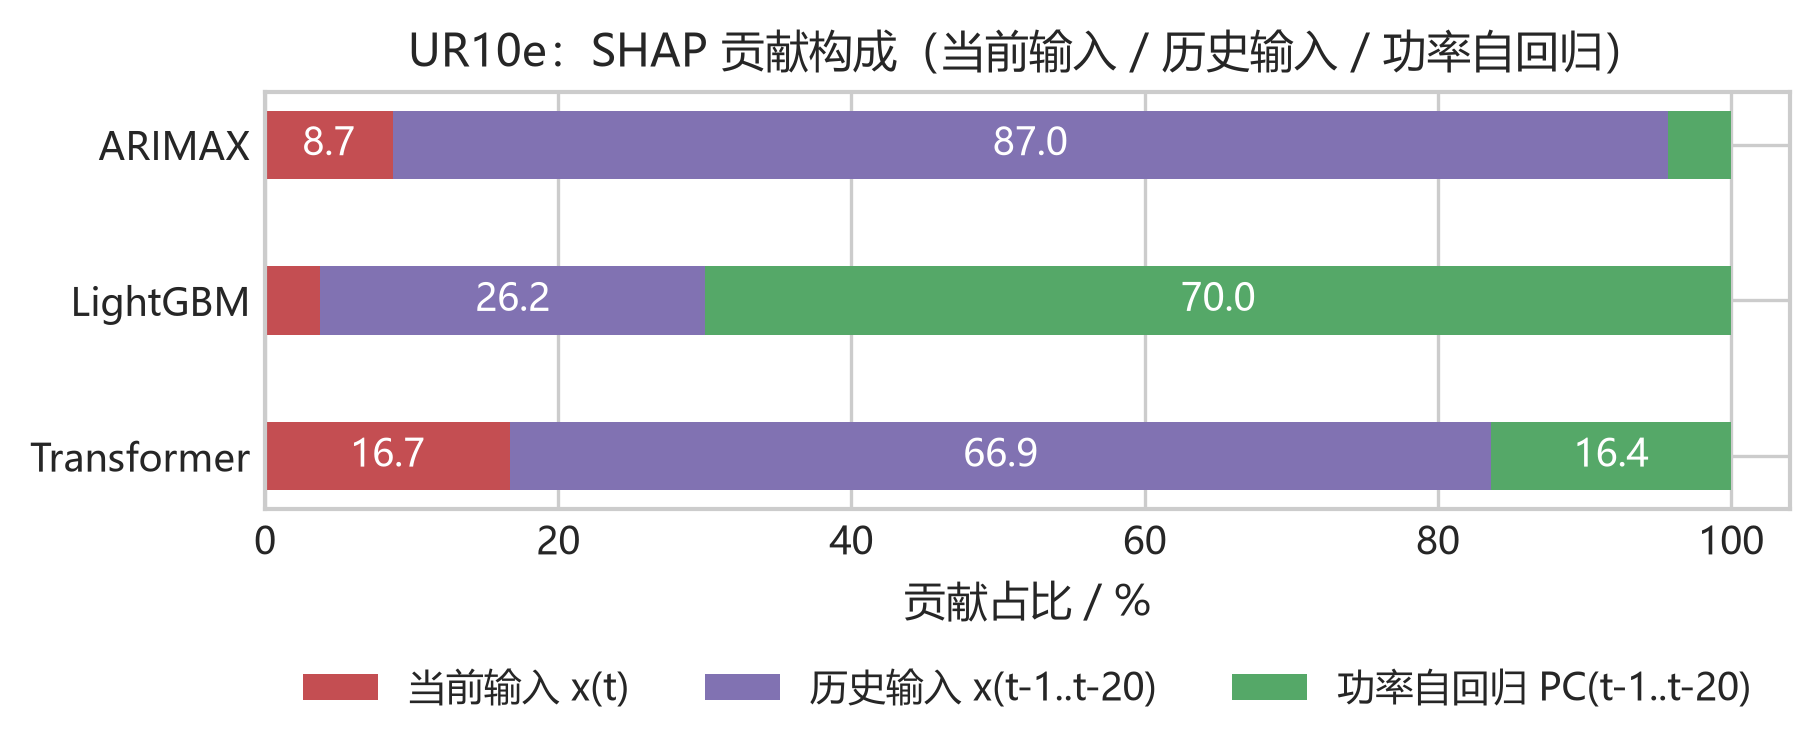

In [22]:
# ---------- 12.5 可解释性：系数 / 增益 / 注意力 / SHAP 三模型对照 ----------
u10_coef = pd.Series(u10_w, index=FLAT_NAMES)
u10_top = u10_coef.reindex(u10_coef.abs().sort_values(ascending=False).head(18).index)[::-1]
u10_gain = pd.Series(
    u10_model_lgb.feature_importance(importance_type="gain", iteration=u10_model_lgb.best_iteration),
    index=FLAT_NAMES, dtype=float)
u10_gain = u10_gain / u10_gain.sum() * 100
u10_gain_base = u10_gain.groupby([n.split("(")[0] for n in u10_gain.index]).sum().sort_values(ascending=False)

# ---------- 12d UR10e / ARIMAX 标准化系数（单图，纵向拉长） ----------
fig, ax = plt.subplots(figsize=fig_size(0.74))
ax.barh(range(len(u10_top)), u10_top.values,
        color=["#C44E52" if n.endswith("(t)") else ("#4C72B0" if n.startswith("PC(") else "#8172B2")
               for n in u10_top.index])
ax.set_yticks(range(len(u10_top)))
ax.set_yticklabels(u10_top.index, fontsize=FS_TICK)
ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("标准化回归系数", fontsize=FS_LABEL)
ax.tick_params(axis="x", labelsize=FS_TICK)
ax.set_title("UR10e / ARIMAX：系数绝对值 Top 18\n红=当前  蓝=自回归  紫=历史", fontsize=FS_TITLE)
u10_share_arx = split_share(u10_coef.abs().values, list(u10_coef.index))
u10_share_arx = u10_share_arx / u10_share_arx.sum() * 100
ax.text(0.98, 0.02,
        "系数绝对值占比：\n"
        f"  当前 {u10_share_arx[LBL_CUR]:.1f}%\n"
        f"  历史 {u10_share_arx[LBL_HIS]:.1f}%\n"
        f"  自回归 {u10_share_arx[LBL_AR]:.1f}%",
        transform=ax.transAxes, fontsize=FS_TICK, va="bottom", ha="right",
        bbox=dict(boxstyle="round", fc="white", alpha=0.85))
fig.tight_layout()
savefig(fig, "12d_u10_arimax_coef")
plt.show()

# ---------- 12e UR10e / LightGBM 增益重要度（单图，纵向拉长） ----------
u10_gb = u10_gain_base.drop("PC").head(15)
fig, ax = plt.subplots(figsize=fig_size(0.66))
ax.barh(range(len(u10_gb)), u10_gb.values, color="#DD8452")
ax.set_yticks(range(len(u10_gb)))
ax.set_yticklabels(u10_gb.index, fontsize=FS_TICK)
ax.invert_yaxis()
ax.set_xlabel("增益重要度 / %（已剔除 PC 自回归项）", fontsize=FS_LABEL)
ax.tick_params(axis="x", labelsize=FS_TICK)
ax.set_title("UR10e / LightGBM：基础变量增益重要度 Top 15", fontsize=FS_TITLE)
ax.text(0.95, 0.05, f"PC(t-1..t-{LAGS}) 自回归项\n合计占 {u10_gain_base['PC']:.1f}%",
        transform=ax.transAxes, fontsize=FS_TICK, ha="right",
        bbox=dict(boxstyle="round", fc="white", alpha=0.85))
fig.tight_layout()
savefig(fig, "12e_u10_lgb_gain")
plt.show()

# 注意力结构
u10_A = compute_attention(u10_model_tf,
                          torch.from_numpy(u10_S_te[:1024]).to(DEVICE),
                          torch.from_numpy(u10_C_te[:1024]).to(DEVICE))
u10_labels = [f"t-{LAGS - i}" for i in range(LAGS)] + ["t(当前)"]
u10_last_attn = u10_A[-1, -1, :]
print("UR10e / Transformer：最后一层当前 token 的注意力")
for nm, v in zip(u10_labels, u10_last_attn):
    print(f"  {nm:>7s}: {v:.4f}")
print("注意力峰值位置:", u10_labels[int(np.argmax(u10_last_attn))])

# SHAP：线性 SHAP / TreeSHAP / GradientSHAP
u10_rng = np.random.default_rng(SEED)
u10_Xs = u10_F_te[u10_rng.choice(len(u10_Y_te), size=min(600, len(u10_Y_te)), replace=False)]
u10_base_x = u10_F_tr.mean(0).astype(np.float64)
u10_imp_arx = np.abs((u10_Xs - u10_base_x) * u10_w * u10_y_sd).mean(0)

u10_expl = shap.TreeExplainer(u10_model_lgb)
u10_shap_lgb = np.asarray(u10_expl.shap_values(u10_Xs))
u10_imp_lgb = np.abs(u10_shap_lgb).mean(0)
u10_add = float(np.abs(u10_shap_lgb.sum(1) + np.ravel(u10_expl.expected_value)[0]
                       - u10_model_lgb.predict(u10_Xs, num_iteration=u10_model_lgb.best_iteration)).mean())
print(f"UR10e / TreeSHAP 可加性检查 = {u10_add:.2e} W")

u10_bg = [torch.from_numpy(u10_S_te[:100]).to(DEVICE), torch.from_numpy(u10_C_te[:100]).to(DEVICE)]
u10_ex = [torch.from_numpy(u10_S_te[100:200]).to(DEVICE), torch.from_numpy(u10_C_te[100:200]).to(DEVICE)]
u10_model_tf.eval()
np.random.seed(SEED)          # 固定 GradientSHAP 的背景采样，保证归因可复现
u10_grad = shap.GradientExplainer(TFShapWrapper(u10_model_tf).to(DEVICE), u10_bg)
u10_sv = u10_grad.shap_values(u10_ex)
u10_sv_past = np.abs(np.asarray(u10_sv[0]).squeeze(-1)).mean(0) * u10_y_sd   # (L, 26)
u10_sv_cur = np.abs(np.asarray(u10_sv[1]).squeeze(-1)).mean(0) * u10_y_sd    # (25,)

u10_share = pd.DataFrame({
    "ARIMAX": split_share(u10_imp_arx, FLAT_NAMES),
    "LightGBM": split_share(u10_imp_lgb, FLAT_NAMES),
    "Transformer": pd.Series({
        LBL_CUR: u10_sv_cur.sum(),
        LBL_HIS: u10_sv_past[:, : len(FEATURE_COLS)].sum(),
        LBL_AR: u10_sv_past[:, -1].sum(),
    }),
})
u10_share = (u10_share / u10_share.sum() * 100).T     # 行 = 模型，列 = 三类语义组
print("UR10e：三个模型的 SHAP 归因构成（%）")
display(u10_share.round(2))

# ---------- 12f UR10e SHAP 贡献构成（每个模型一条，按语义组堆叠） ----------
fig, ax = plt.subplots(figsize=fig_size(0.46))
_rows = list(u10_share.index)[::-1]
_left = np.zeros(len(_rows))
for k, seg in enumerate(u10_share.columns):
    vals_seg = u10_share[seg].reindex(_rows).values
    ax.barh(_rows, vals_seg, left=_left, height=0.44,
            color=["#C44E52", "#8172B2", "#55A868"][k], label=seg)
    for yi, (l, v) in enumerate(zip(_left, vals_seg)):
        if v > 8:
            ax.text(l + v / 2, yi, f"{v:.1f}", ha="center", va="center",
                    fontsize=FS_TICK, color="white")
    _left += vals_seg
ax.set_xlim(0, 104)
ax.set_xlabel("贡献占比 / %", fontsize=FS_LABEL)
ax.set_title("UR10e：SHAP 贡献构成（当前输入 / 历史输入 / 功率自回归）", fontsize=FS_TITLE)
ax.tick_params(labelsize=FS_TICK)
ax.legend(fontsize=FS_LEGEND, ncol=3, loc="upper center",
          bbox_to_anchor=(0.5, -0.30), frameon=False)
fig.tight_layout()
savefig(fig, "12f_u10_shap_share")
plt.show()

### 12.6 跨机型对照与分析

把两个数据集的单步结果放在一起（同为 $L=20$ 窗口、同一套模型与超参搜索、同一划分比例、同一随机种子）：

| 指标 | 模型 | UR3e（50 Hz，窗口 400 ms） | UR10e（100 Hz，窗口 200 ms） | 变化 |
|---|---|---|---|---|
| 测试 RMSE / W | ARIMAX | 3.076 | 3.850 | +25.2% |
| | LightGBM | 2.981 | 3.199 | +7.3% |
| | Transformer | 4.001 | 4.536 | +13.4% |
| NRMSE / % | ARIMAX | 6.70 | 6.99 | +0.3 pt |
| | LightGBM | 6.49 | **5.81** | −0.7 pt |
| | Transformer | 8.71 | **8.24** | −0.5 pt |
| $R^2$ | ARIMAX | 0.9116 | 0.9617 | +0.050 |
| | LightGBM | 0.9170 | **0.9736** | +0.057 |
| | Transformer | 0.8504 | 0.9468 | +0.096 |
| 自回归项在 SHAP 中的占比 / % | ARIMAX | 2.8 | 4.3 | +1.5 pt |
| | LightGBM | 70.8 | 70.0 | −0.8 pt |
| | Transformer | 29.5 | 16.4 | −13.1 pt |

**① 模型排序在两个机型上完全一致：LightGBM < ARIMAX < Transformer。** 这说明"梯度提升树略优于线性模型、Transformer 在该数据规模下最差"不是 UR3e 的偶然结果，而与本任务的共性有关——训练轨迹只有百余条、窗口高度重叠（相邻窗口共享 19/20 步历史），有效独立样本远少于名义样本数，深度模型的容量优势无法发挥。

**② 绝对误差上升，但归一化误差反而下降——不要只看 $R^2$。** UR10e 测试集的 `PC` 均值 55.1 W、标准差 19.8 W（UR3e 为 45.8 W / 10.4 W），动态范围接近两倍，因此 RMSE 上升 7–25% 属正常量纲效应；NRMSE 显示 LightGBM 与 Transformer 的相对精度其实**更好**（5.81% / 8.24%），只有 ARIMAX 略变差（6.70% → 6.99%）。$R^2$ 在所有模型上都更高，但这主要是"信号方差变大"带来的，跨数据集比较应看 NRMSE。

**③ 非线性收益与机型相关：UR10e 上树模型领先 16.9%，UR3e 上只领先 3.1%。** LightGBM 相对 ARIMAX 的 RMSE 优势在 UR10e 上是 16.9%（3.199 vs 3.850），而 UR3e 上仅 3.1%。这与 UR10e 的运动特性一致：10 kg 负载、大惯量的六轴臂在高速往复时，同一组关节速度对应的功率差异更大，线性模型更难刻画。

**④ 归因结构同构，但 Transformer 的权重分配会随轨迹性质漂移。** 两个机型都呈现"ARIMAX 物理驱动、LightGBM 自回归驱动、Transformer 均衡"的格局：UR10e 的 ARIMAX 在系数口径下为当前 8.1% / 历史 85.8% / 自回归 6.1%（SHAP 口径 8.7% / 87.0% / 4.3%），主导变量仍是 $M$ 与 $d\dot q_2$ 的各滞后阶；LightGBM 的自回归项在增益口径下合计 94.4%（SHAP 70.0%），与 UR3e 的 91.9% / 70.8% 基本一致。差异集中在 Transformer：它的自回归占比从 UR3e 的 29.5% 降到 16.4%，把权重更多分给了历史输入 $x_{t-1..t-20}$（66.9%，UR3e 为 40.2%），注意力也更平、峰位后移（最大值在 $t-2$ 的 0.068，$t-1$ 为 0.068、$t-20$ 为 0.037；UR3e 则是 $t-1$ 的 0.110 为峰）。

**⑤ 对多步预测的直接含义（较前一版结论有修正）。** 第 10 节的结论是"退化速度由自回归依赖度决定"。UR10e 上 LightGBM 的自回归占比 70.0%，与 UR3e 的 70.8% 几乎相同，ARIMAX 仅 4.3%、Transformer 16.4%（低于 UR3e 的 29.5%），因此它的递归多步退化速度预计与 UR3e **接近**，Transformer 甚至可能更慢；但 UR10e 的轨迹更平滑、重复性更强，外生输入的短期可预测性更好，两者方向相反，仍需实验才能定论（见 12.7）。

**⑥ 验证集与测试集的难度已基本对齐。** 验证 RMSE 为 ARIMAX 3.72 W、LightGBM 3.28 W、Transformer 6.19 W，对应测试集 3.85 / 3.20 / 4.54 W：前两者几乎持平，只有 Transformer 的验证误差仍是测试集的 1.4 倍。这说明早停与正则不再被"更难的子集"过度压缩（LightGBM 用到 482 棵树、Transformer 训练到第 23 轮才早停），三个模型都得到了较充分的拟合。但训练集仍含功率高达 904 W 的极端轨迹（训练集 `PC` 标准差 33.0 W，测试集仅 19.8 W，约为 1.7 倍），量纲差异带来的风险仍需在数据划分阶段显式处理。


,UR3e RMSE / W,UR10e RMSE / W,UR3e NRMSE / %,UR10e NRMSE / %,UR3e R²,UR10e R²,RMSE 变化 / %
模型,,,,,,,
ARIMAX,3.0756,3.8504,6.6978,6.9928,0.9116,0.9617,25.1912
LightGBM,2.9806,3.1988,6.4909,5.8094,0.9170,0.9736,7.3202
Transformer,4.0007,4.5364,8.7124,8.2387,0.8504,0.9468,13.3900


自回归项在 SHAP 归因中的占比（%，UR3e 见 9.4.5 / UR10e 见 12.5）


,ARIMAX,LightGBM,Transformer
UR3e,2.8,70.8,29.5
UR10e,4.3,70.0,16.4


[saved] figures\train_test\12g_cross_machine.png  (300 dpi)


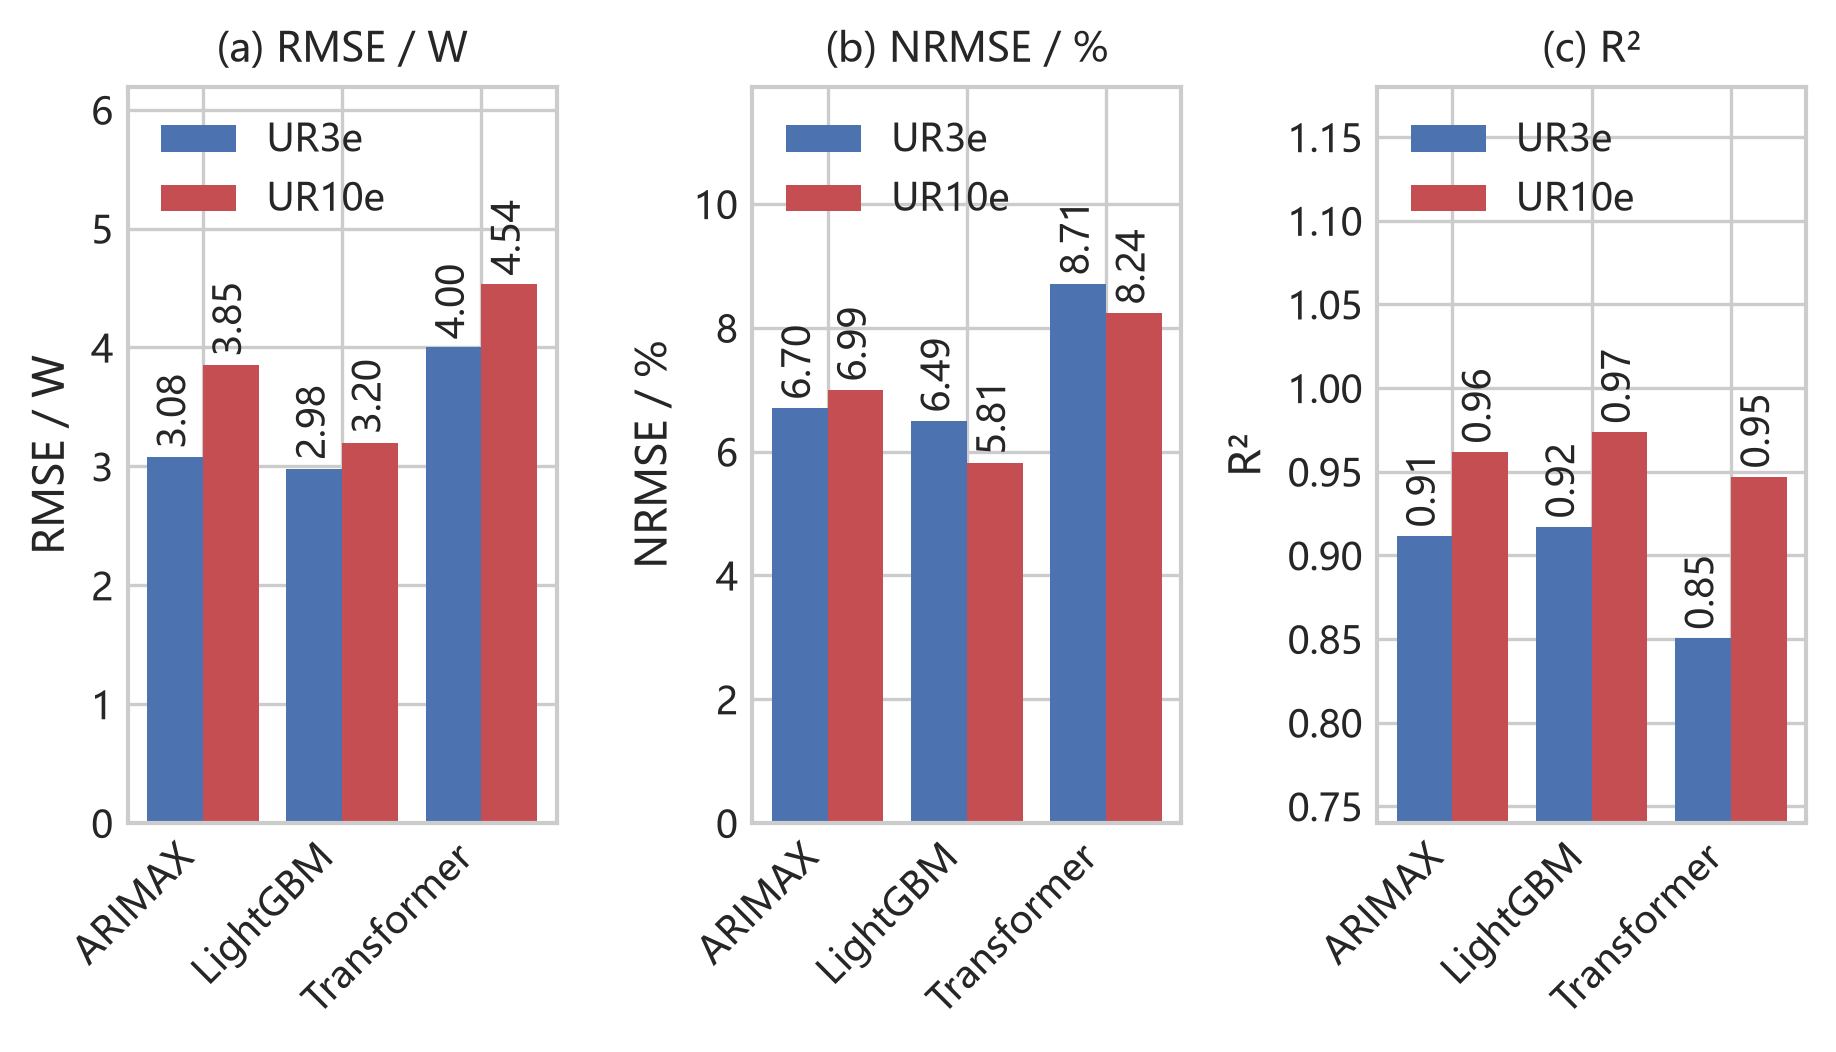

模型排序（测试集 RMSE，由优到劣）：
  UR3e: LightGBM < ARIMAX < Transformer
  UR10e: LightGBM < ARIMAX < Transformer


In [23]:
# ---------- 12.6 跨机型对照（UR3e vs UR10e，均为单步预测） ----------
u10_cmp = pd.DataFrame({
    "UR3e RMSE / W": accuracy_table["RMSE / W"],
    "UR10e RMSE / W": u10_acc["RMSE / W"],
    "UR3e NRMSE / %": accuracy_table["NRMSE / %"],
    "UR10e NRMSE / %": u10_acc["NRMSE / %"],
    "UR3e R²": accuracy_table["R²"],
    "UR10e R²": u10_acc["R²"],
})
u10_cmp["RMSE 变化 / %"] = (u10_cmp["UR10e RMSE / W"] / u10_cmp["UR3e RMSE / W"] - 1) * 100
display(u10_cmp.round(4))

print("自回归项在 SHAP 归因中的占比（%，UR3e 见 9.4.5 / UR10e 见 12.5）")
display(pd.DataFrame({"UR3e": share_all.loc[LBL_AR], "UR10e": u10_share[LBL_AR]}).T.round(1))

# ---------- 12g 跨机型指标对照（同类图罗列，保留 1×3） ----------
fig, axes = plt.subplots(1, 3, figsize=fig_size(0.58))
idx = np.arange(len(u10_acc))
for ax, tag, col in zip(axes, "abc", ["RMSE / W", "NRMSE / %", "R²"]):
    ax.bar(idx - 0.2, accuracy_table[col], 0.4, label="UR3e", color="#4C72B0")
    ax.bar(idx + 0.2, u10_acc[col], 0.4, label="UR10e", color="#C44E52")
    ax.set_xticks(idx)
    ax.set_xticklabels(u10_acc.index, fontsize=FS_TICK, rotation=45, ha="right")
    ax.set_ylabel(col, fontsize=FS_LABEL)
    ax.tick_params(labelsize=FS_TICK)
    tag_title(ax, tag, col, fontsize=9.5)
    for c in ax.containers:
        ax.bar_label(c, fmt="%.2f", fontsize=FS_TICK, padding=2, rotation=90)
    _lo, _hi = ax.get_ylim()
    ax.set_ylim(_lo, _hi + 0.30 * (_hi - _lo))      # 顶部留白放竖排数值与图例
    ax.legend(fontsize=FS_LEGEND, ncol=1, loc="upper left", framealpha=0.9)

axes[2].set_ylim(0.74, 1.18)
fig.tight_layout()
savefig(fig, "12g_cross_machine")
plt.show()

print("模型排序（测试集 RMSE，由优到劣）：")
for nm, tbl in (("UR3e", accuracy_table), ("UR10e", u10_acc)):
    print(f"  {nm}: " + " < ".join(tbl["RMSE / W"].sort_values().index.tolist()))

### 12.7 局限与后续工作（UR10e 部分）

1. **窗口时长未对齐**：UR10e 是 100 Hz，同样 $L=20$ 只覆盖 200 ms（UR3e 为 400 ms）。本章的对齐维度是"相同的窗口步数与特征维度"，若要严格对齐**时间跨度**，应把 UR10e 的 $L$ 设为 40——这会让参数矩阵变为 $40\times26+25=1065$ 维，值得单独做一次消融。
2. **验证集与测试集的分布差异**：96 条训练轨迹按 8:2 划分后，验证集 20 条、训练集 76 条。ARIMAX 与 LightGBM 的验证误差已与测试集持平（3.72 / 3.28 W vs 3.85 / 3.20 W），但 Transformer 的验证误差仍偏难（6.19 vs 4.54 W）。根源是训练集包含功率高达 904 W 的极端轨迹（训练集 `PC` 标准差 33.0 W，测试集仅 19.8 W），因此早停与正则强度实际上是在"更难的子集"上决定的。后续建议按功率水平**分层抽样轨迹**，或改用按轨迹的多折交叉验证决定迭代轮数。
3. **样本独立性问题**：UR10e 每条轨迹仅 500 点（5 s），滑窗高度重叠；96 条轨迹虽然提供 46,080 个净滑窗（训练 36,480 / 验证 9,600 / 测试 5,760），但有效独立样本远少于此，深度模型仍容易记住单条轨迹的局部动态。
4. **未做多步预测**：本章只验证了单步。UR10e 的自回归归因占比为 ARIMAX 4.3% / LightGBM 70.0% / Transformer 16.4%，与 UR3e 的 2.8% / 70.8% / 29.5% 接近，因此其递归多步的误差累积速度预计与 UR3e 相当（Transformer 可能更慢），但这仍是一个值得验证的假设。
5. **未做跨机型迁移**：目前两个数据集各自独立训练。可以尝试用 UR3e 预训练、UR10e 微调，检验表征的可迁移性；或把机型参数（连杆长度、额定负载）作为条件输入纳入模型。
6. **可扩展方向**：把 $P=\tau\cdot\dot q$ 作为硬约束嵌入损失（PINN）；对 UR10e 采用更细的时间步采样以降低单步内的动力学变化幅度。
